# Notebook 08 — Thesis Bricks: the figures of the thesis

Notebooks 01–06 do the analysis. This notebook turns their outputs into **eight presentation bricks**. Each brick answers one reader question and writes its own figures, tables and a short text note to `outputs/thesis_bricks/<brick>/`. Nothing here recomputes a result from Notebooks 05–06. Bricks 1–7 describe the data and the network; Brick 8 redraws the model results from the tables those notebooks wrote.

| Brick | Reader question | Thesis chapter | Main inputs |
|---|---|---|---|
| **1 · Data construction** | What data did the thesis start from, and how did it become the network corpus? | Data | NB01 corpora, funnel |
| **2 · NLP similarity** | How does a plot overview become a similarity between two films? | Method | NB03 embeddings, overviews |
| **3 · Network construction** | How do similarities become a clean, analysable network? | Method | NB03 nodes, edges, audit |
| **4 · Narrative communities** | Which kinds of story does the network contain? | Results I | NB03–04 communities, labels |
| **5 · Central story positions** | Which films are typical of their narrative, and what does centrality mean? | Results I | NB04 positions |
| **6 · Bridging positions** | Which films sit between narratives, and which narratives touch? | Results I | NB03 betweenness, NB04 participation |
| **7 · Success dimensions** | Is success one thing or several? | Results II | NB05 modelling table |
| **8 · Structure and success** | How is a film's place in plot space associated with its success? | Results II | NB05 + NB06 result tables |

**Reading rules used in every brick**
* Centrality is a position in *plot-similarity* space, not fame or quality.
* Example films shown by name have at least 50 votes, with one film per title family (franchise cap). The network itself is never changed.
* Success results are **associations**, not causal effects.

**How to run:** run Cells 1–3 once, then any brick on its own, or everything top to bottom. A figure whose input is missing is skipped with a message. The final cell lists what was written and what was skipped.

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — CONFIG
# ═══════════════════════════════════════════════════════════════════════════
CFG = {
    "project_dir": "/content/drive/MyDrive/thesis_movie_project",
    "bricks_dir": "outputs/thesis_bricks",

    # ── display rules (same as Notebook 04) ─────────────────────────────────
    "display_min_vote_count": 50,        # films shown by name must be recognisable
    "well_known_min_votes": 1000,
    "core_internal_share": 0.75,         # core film: ≥ 75% of its plot similarity stays in its community
    "tentative_robustness": 0.50,        # community robustness below this = tentative
    "label_chars": 34,                   # long labels are shortened at a word boundary in figures

    # ── Brick 2: worked examples (first title found in the network is used) ─
    "anchor_titles": ["Toy Story", "The Dark Knight", "Titanic", "Alien", "The Notebook", "Inception"],
    "n_neighbour_cards": 5,
    "random_pairs": 200_000,             # random film pairs for the 'chance level' of similarity
    "map_communities": 8,                # embedding map: the n largest major communities …
    "map_films_per_community": 350,      # … with this many films each
    "random_state": 42,

    # ── Brick 4–6 ───────────────────────────────────────────────────────────
    "table_communities": 12,             # rows in the community / central-film tables
    "profile_communities": 6,            # profile cards
    "bridge_top_share": 0.05,            # 'high betweenness' = top 5% of films
    "bridge_participation": 0.50,        # 'spread' neighbourhood = participation ≥ 0.5
    "path_titles": None,                 # e.g. ("Toy Story", "Saw"); None = picked automatically

    # ── Brick 7 ─────────────────────────────────────────────────────────────
    "min_money_for_roi": 10_000,         # same rule as Notebook 06

    # ── output ──────────────────────────────────────────────────────────────
    "figure_dpi": 220,
    "save_svg": True,                    # vector copy for the thesis document
    "stop_on_error": False,              # True: a failing figure stops the notebook (for debugging)
    # Earlier brick notebooks wrote to the same folders with other file names (01_data_funnel_main.png …).
    # True: move those files into outputs/thesis_bricks/_v1_archive/ (moved, never deleted), so each
    # brick folder holds only the figures this notebook makes.
    "archive_v1_outputs": True,
}
print("CONFIG loaded.")

CONFIG loaded.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — Imports, Drive mount, paths, figure style, helpers
# ═══════════════════════════════════════════════════════════════════════════
import json, os, re, shutil, textwrap, time, traceback, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
import networkx as nx

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
try:
    display
except NameError:
    display = print

def mount_drive():
    """Mount Google Drive in Colab. Safe to re-run."""
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab — using local paths.")
        return
    if os.path.ismount("/content/drive"):
        print("Google Drive already mounted.")
        return
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        aside = f"/content/drive_local_leftover_{time.strftime('%Y%m%d_%H%M%S')}"
        shutil.move("/content/drive", aside)
        print(f"Moved a local leftover folder (not the Drive itself) to {aside}.")
    drive.mount("/content/drive")
mount_drive()

PROJECT_DIR = Path(os.environ.get("THESIS_PROJECT_DIR", CFG["project_dir"]))
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check that Google Drive is mounted "
                            "(left sidebar → Files → drive/MyDrive) and that CFG['project_dir'] is right.")
CFG["stop_on_error"] = CFG["stop_on_error"] or os.environ.get("THESIS_STRICT") == "1"
CORE_DIR     = PROJECT_DIR / "processed" / "core"
NETWORK_DIR  = PROJECT_DIR / "processed" / "network"
FEATURES_DIR = PROJECT_DIR / "processed" / "features"
TABLES_DIR   = PROJECT_DIR / "outputs" / "tables"
BRICKS_DIR   = PROJECT_DIR / CFG["bricks_dir"]

FILES = {
    "thesis":        CORE_DIR / "df_thesis_films.csv",
    "corpus":        CORE_DIR / "df_network_corpus.csv",
    "corpus_manifest": CORE_DIR / "corpus_manifest.json",
    "funnel":        TABLES_DIR / "filtering_funnel.csv",
    "nodes":         NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges":         NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "positions":     NETWORK_DIR / "node_positions_nb04.csv",
    "network_manifest": NETWORK_DIR / "network_manifest.json",
    "network_audit": TABLES_DIR / "network_audit.csv",
    "labels":        TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "genre_nmi":     TABLES_DIR / "interpretation" / "communities_vs_genre_nmi.csv",
    "franchise":     TABLES_DIR / "interpretation" / "franchise_or_name_driven_communities.csv",
    "model_table":   FEATURES_DIR / "modeling_table_success_star_power.csv",
    "time_aware":    FEATURES_DIR / "time_aware_plot_features.csv",
    "model_fit":     TABLES_DIR / "success" / "model_fit_summary.csv",
    "coefficients":  TABLES_DIR / "success" / "fig_05_coefficients.csv",
    "community_effects": TABLES_DIR / "success" / "fig_04_community_effects.csv",
    "novelty_shape": TABLES_DIR / "success" / "novelty_shape.csv",
    "timing":        TABLES_DIR / "narrative_dynamics" / "timing_regressions.csv",
    "moran":         TABLES_DIR / "narrative_dynamics" / "fig_04_morans_i.csv",
    "oos":           TABLES_DIR / "narrative_dynamics" / "out_of_sample_prediction.csv",
    "trends":        TABLES_DIR / "narrative_dynamics" / "community_trends.csv",
    # Notebook 07 (robustness) — optional; the storyline uses it when present
    "fdr_tests":     TABLES_DIR / "robustness" / "multiple_testing_plot_and_timing.csv",
    "fdr_communities": TABLES_DIR / "robustness" / "multiple_testing_communities.csv",
    "foresight_windows": TABLES_DIR / "robustness" / "foresight_by_window.csv",
    "imitation":     TABLES_DIR / "robustness" / "success_predicts_later_similar_stories.csv",
    "net_robust":    TABLES_DIR / "robustness" / "network_robustness_model_fit.csv",
    "plain_units":   TABLES_DIR / "robustness" / "effects_in_plain_units.csv",
    "sim_check":     TABLES_DIR / "robustness" / "similarity_validation_summary.csv",
    "story_vs_stars": TABLES_DIR / "robustness" / "story_vs_stars_interactions.csv",
    "wild_bootstrap": TABLES_DIR / "robustness" / "wild_cluster_bootstrap.csv",
}

# ── one figure style for all notebooks (same palette as Notebooks 02–06) ────
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
PALE = ["#dbe8f8", "#fbe3d7", "#d5f0e5", "#fbedcc"]
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8b5fbf", "#d64f8a", "#4bb3c4", "#8c6d46",
               "#5c6bc0", "#7cb342", "#c0504d", "#607d8b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "DejaVu Sans", "lines.linewidth": 2, "legend.frameon": False,
    "svg.fonttype": "none",
})

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", ha="left")

def fig_header(fig, title, sub, band_in=0.85):
    """Lay out panels first, then put title and subtitle in a fixed-height band (inches) above them."""
    h = fig.get_figheight()
    fig.tight_layout()
    fig.subplots_adjust(top=1 - band_in / h)
    fig.text(0.01, 1 - 0.05 / h, title, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 1 - 0.37 / h, sub, fontsize=9.5, color=INK_2, va="top")

def short(text, n=None):
    return textwrap.shorten(str(text), width=n or CFG["label_chars"], placeholder="…")

def wrap(text, width):
    return "\n".join(textwrap.wrap(str(text), width))

def no_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

def label_points(ax, xs, ys, texts, fontsize=7.5, step=11):
    """Label points with vertical offsets that grow when labels would sit on top of each other."""
    placed = []
    for x, y, t in sorted(zip(xs, ys, texts), key=lambda r: -r[1]):
        px = ax.transData.transform((x, y))
        k = sum(1 for q in placed if abs(q[0] - px[0]) < 120 and abs(q[1] - px[1]) < 14)
        ax.annotate(t, (x, y), xytext=(5, 3 + step * k), textcoords="offset points", fontsize=fontsize, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5) if k else None)
        placed.append((px[0], px[1] + step * k))

def numbered_labels(ax, xs, ys, texts, where=(0.02, 0.03), va="bottom", ha="left"):
    """Number points on the plot and list the names in a box (no overlapping labels in dense corners)."""
    for k, (x, y) in enumerate(zip(xs, ys), start=1):
        ax.annotate(str(k), (x, y), xytext=(0, 0), textcoords="offset points", ha="center", va="center", fontsize=6.5,
                    color="white", fontweight="bold", zorder=5,
                    bbox=dict(boxstyle="circle,pad=0.2", fc=INK, ec="none"))
    ax.text(*where, "\n".join(f"{k}  {t}" for k, t in enumerate(texts, start=1)), transform=ax.transAxes, fontsize=7.5,
            va=va, ha=ha, multialignment="left", color=INK, zorder=6, bbox=dict(boxstyle="round,pad=0.4", fc=SURFACE, ec=GRID, alpha=0.95))

def fmt_int(x):
    return "—" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{int(x):,}"

def spearman(a, b):
    d = pd.concat([pd.Series(a), pd.Series(b)], axis=1).dropna()
    return d.corr(method="spearman").iloc[0, 1] if len(d) > 2 else np.nan

# ── brick bookkeeping: every figure is saved with the table holding its numbers ──
BRICKS = {1: "01_data_construction", 2: "02_nlp_similarity", 3: "03_network_construction",
          4: "04_narrative_communities", 5: "05_central_story_positions", 6: "06_bridging_story_positions",
          7: "07_success_dimensions", 8: "08_structure_success"}
OUTPUTS, SKIPPED = [], []
CUR = {}

V1_ARCHIVE = BRICKS_DIR / "_v1_archive"
V1_ONLY_FOLDERS = ["06_advanced_brokerage", "06_bridging_analysis"]      # older folders this notebook does not use

def archive_v1(root):
    """Move files this notebook does not write (older names) from a brick folder into _v1_archive/."""
    moved = 0
    for sub in ["figures", "tables", "text"]:
        d = root / sub
        if not d.exists():
            continue
        for f in d.iterdir():
            ours = f.name.startswith("fig_") or re.fullmatch(r"brick_\d\d_notes\.txt", f.name)
            if f.is_file() and not ours:
                dest = V1_ARCHIVE / root.name / sub
                dest.mkdir(parents=True, exist_ok=True)
                shutil.move(str(f), str(dest / f.name))
                moved += 1
    if moved:
        print(f"  ↪ moved {moved} older file(s) to {V1_ARCHIVE.relative_to(PROJECT_DIR)}/{root.name}/")

if CFG["archive_v1_outputs"]:
    for name in V1_ONLY_FOLDERS:
        if (BRICKS_DIR / name).exists():
            V1_ARCHIVE.mkdir(parents=True, exist_ok=True)
            shutil.move(str(BRICKS_DIR / name), str(V1_ARCHIVE / name))
            print(f"  ↪ moved older folder {name}/ to {V1_ARCHIVE.relative_to(PROJECT_DIR)}/")

def start_brick(n):
    root = BRICKS_DIR / BRICKS[n]
    if CFG["archive_v1_outputs"]:
        archive_v1(root)
    CUR.update(n=n, root=root, fig=root / "figures", tab=root / "tables", txt=root / "text")
    for d in [CUR["fig"], CUR["tab"], CUR["txt"]]:
        d.mkdir(parents=True, exist_ok=True)
    print(f"Brick {n} → {root.relative_to(PROJECT_DIR)}")

def save(fig, table, name):
    fig.savefig(CUR["fig"] / f"{name}.png", dpi=CFG["figure_dpi"], bbox_inches="tight")
    if CFG["save_svg"]:
        fig.savefig(CUR["fig"] / f"{name}.svg", bbox_inches="tight")
    if table is not None:
        table.to_csv(CUR["tab"] / f"{name}.csv", index=False)
    plt.show()
    plt.close(fig)
    OUTPUTS.append({"brick": BRICKS[CUR["n"]], "kind": "figure", "file": f"{name}.png"})
    print(f"  ✓ {BRICKS[CUR['n']]}/figures/{name}.png" + (" + table" if table is not None else ""))

def save_tab(df, name):
    df.to_csv(CUR["tab"] / name, index=False)
    OUTPUTS.append({"brick": BRICKS[CUR["n"]], "kind": "table", "file": name})
    print(f"  ✓ {BRICKS[CUR['n']]}/tables/{name}")

def write_note(lines):
    text = "\n".join(lines)
    name = f"brick_{CUR['n']:02d}_notes.txt"
    (CUR["txt"] / name).write_text(text, encoding="utf-8")
    OUTPUTS.append({"brick": BRICKS[CUR["n"]], "kind": "text", "file": name})
    print(text)
    print(f"\n  ✓ {BRICKS[CUR['n']]}/text/{name}")

def figure(fn):
    """Decorator: run a figure function now; if its inputs are missing, skip it with a message."""
    try:
        fn()
    except Exception as ex:
        plt.close("all")
        SKIPPED.append({"brick": BRICKS.get(CUR.get("n"), "?"), "figure": fn.__name__, "reason": repr(ex)[:300]})
        print(f"  ✗ {fn.__name__} skipped: {ex!r}")
        if CFG["stop_on_error"]:
            raise
    return fn

class Missing(Exception):
    """An optional input file is not there."""

def need(*keys):
    gone = [FILES[k].name for k in keys if not FILES[k].exists()]
    if gone:
        raise Missing(f"missing input {gone}")

def card_figure(cards, title, sub, ncols=3):
    """A grid of number cards: (value, label, note)."""
    nrows = int(np.ceil(len(cards) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 1.75 * nrows + 0.9))
    for i, ax in enumerate(np.atleast_1d(axes).ravel()):
        no_axes(ax)
        if i >= len(cards):
            continue
        value, label, note_ = cards[i]
        ax.add_patch(FancyBboxPatch((0.03, 0.06), 0.94, 0.88, boxstyle="round,pad=0,rounding_size=0.06",
                                    transform=ax.transAxes, facecolor=PALE[i % 4], edgecolor="none"))
        ax.text(0.08, 0.72, value, transform=ax.transAxes, fontsize=19, fontweight="bold", color=INK, va="center")
        ax.text(0.08, 0.46, wrap(short(label, 64), 34), transform=ax.transAxes, fontsize=10, color=INK, va="center",
                fontweight="bold", linespacing=1.1)
        ax.text(0.08, 0.2, wrap(short(note_, 88), 46), transform=ax.transAxes, fontsize=8.2, color=INK_2, va="center",
                linespacing=1.15)
    h = fig.get_figheight()
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=1 - 0.85 / h, wspace=0.06, hspace=0.12)
    fig.text(0.01, 1 - 0.05 / h, title, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 1 - 0.37 / h, sub, fontsize=9.5, color=INK_2, va="top")
    return fig

print("PROJECT_DIR:", PROJECT_DIR)
for k, p in FILES.items():
    print(f"  {'✓' if p.exists() else '–'} {k:18s} {p.relative_to(PROJECT_DIR)}")

Not running in Colab — using local paths.
PROJECT_DIR: /tmp/run78
  ✓ thesis             processed/core/df_thesis_films.csv
  ✓ corpus             processed/core/df_network_corpus.csv
  ✓ corpus_manifest    processed/core/corpus_manifest.json
  ✓ funnel             outputs/tables/filtering_funnel.csv
  ✓ nodes              processed/network/semantic_network_nodes_lcc.csv
  ✓ edges              processed/network/semantic_network_edges_mutual_knn.csv
  ✓ positions          processed/network/node_positions_nb04.csv
  ✓ network_manifest   processed/network/network_manifest.json
  ✓ network_audit      outputs/tables/network_audit.csv
  ✓ labels             outputs/tables/community_manual_labeling_template_labeled.csv
  ✓ genre_nmi          outputs/tables/interpretation/communities_vs_genre_nmi.csv
  ✓ franchise          outputs/tables/interpretation/franchise_or_name_driven_communities.csv
  ✓ model_table        processed/features/modeling_table_success_star_power.csv
  ✓ time_aware        

In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — Load the shared inputs once and check they belong together
# ═══════════════════════════════════════════════════════════════════════════
need("nodes", "edges", "labels")
nodes = pd.read_csv(FILES["nodes"], low_memory=False)
edges = pd.read_csv(FILES["edges"], usecols=["source_node_id", "target_node_id", "cosine_similarity",
                                             "source_rank", "target_rank"])
labels = pd.read_csv(FILES["labels"])
net_manifest = json.loads(FILES["network_manifest"].read_text()) if FILES["network_manifest"].exists() else {}
corpus_manifest = json.loads(FILES["corpus_manifest"].read_text()) if FILES["corpus_manifest"].exists() else {}
audit = (pd.read_csv(FILES["network_audit"]).set_index("metric")["value"]
         if FILES["network_audit"].exists() else pd.Series(dtype=object))

sizes = nodes["community_id"].value_counts()
stale = [(c, n) for c, n in zip(labels["community_id"], labels["n_films"]) if sizes.get(c) != n]
if stale:
    raise ValueError(f"The labelled file does not match the current communities (e.g. {stale[:3]}). "
                     "Re-run Notebook 04 until it writes the labelled file, then run this notebook.")
if net_manifest.get("lcc_nodes") not in (None, len(nodes)):
    raise ValueError("semantic_network_nodes_lcc.csv does not match network_manifest.json — re-run Notebook 03.")
print(f"network {len(nodes):,} films · {len(edges):,} edges · {nodes['community_id'].nunique()} communities "
      f"· {len(labels)} labelled ✓")

BETW = "betweenness_centrality" if "betweenness_centrality" in nodes else "betweenness_centrality_sampled"
if FILES["positions"].exists():
    pos_cols = ["participation_coefficient", "within_community_strength", "main_external_community", "external_share"]
    p = pd.read_csv(FILES["positions"])
    nodes = nodes.drop(columns=[c for c in pos_cols if c in nodes]).merge(
        p[["tmdb_id"] + [c for c in pos_cols if c in p]], on="tmdb_id", how="left")
    nodes["main_external_community"] = nodes["main_external_community"].astype("Int64")
else:
    print("node_positions_nb04.csv not found — participation and within-community strength unavailable (run NB04).")

# ── labels used in every figure: the short label, else the full label shortened ──
MAJOR = labels.sort_values("n_films", ascending=False)["community_id"].tolist()
lab = labels.set_index("community_id")
def _label(c):
    s = lab.loc[c].get("short_label") if "short_label" in lab else None
    return s if isinstance(s, str) and s.strip() else short(lab.loc[c, "suggested_label_manual"])
SHORT = {c: _label(c) for c in MAJOR}
CLAB = {c: f"C{c} · {SHORT[c]}" for c in MAJOR}
FULL = lab["suggested_label_manual"].to_dict()
TENTATIVE = set(lab.index[lab["community_robustness"] < CFG["tentative_robustness"]]) \
    if "community_robustness" in lab else set()
def clab(c):
    return CLAB.get(c, f"C{c} · minor")

# ── title families (display-only franchise cap, same rule as Notebook 04) ────
FRANCHISE = {
    "scooby_doo": r"scooby[\s\-]*doo|\bscoob\b", "star_wars": r"star\s+wars",
    "harry_potter": r"harry\s+potter|fantastic\s+beasts", "lord_of_the_rings": r"lord\s+of\s+the\s+rings|hobbit",
    "batman": r"\bbatman\b|dark\s+knight", "superman": r"\bsuperman\b", "spider_man": r"spider[\s\-]*man",
    "x_men": r"\bx[\s\-]*men\b|wolverine", "avengers": r"\bavengers\b",
    "fast_furious": r"fast\s+.*furious|fast\s+five|fast\s+x", "mission_impossible": r"mission[\s:]*impossible",
    "james_bond": r"james\s+bond|007", "jurassic": r"jurassic\s+park|jurassic\s+world",
    "godzilla": r"\bgodzilla\b", "king_kong": r"king\s+kong", "pokemon": r"pok[eé]mon", "naruto": r"\bnaruto\b",
    "dragon_ball": r"dragon\s+ball", "one_piece": r"one\s+piece", "detective_conan": r"detective\s+conan|case\s+closed",
    "barbie": r"\bbarbie\b", "cinderella": r"\bcinderella\b", "snow_white": r"snow\s+white",
    "alice_wonderland": r"alice\s+.*wonderland", "christmas_carol": r"christmas\s+carol",
    "sherlock_holmes": r"sherlock\s+holmes", "zorro": r"\bzorro\b",
}
def title_family(titles):
    raw = titles.fillna("").astype(str).str.lower().str.strip()
    fam = pd.Series(np.nan, index=raw.index, dtype=object)
    for family, pattern in FRANCHISE.items():
        fam = fam.mask(fam.isna() & raw.str.contains(pattern, regex=True), family)
    t = (raw.str.replace(r"['’]s\b", "", regex=True).str.replace(r"[^a-z0-9\s]", " ", regex=True)
            .str.replace(r"\b(the|a|an)\b", " ", regex=True)
            .str.replace(r"\b(part|chapter|episode|vol|volume|season|book|movie|film|return|revenge|rise|fall|curse|legend)\b\s*[ivx0-9]*", " ", regex=True)
            .str.replace(r"\b[ivx]{1,5}\b", " ", regex=True).str.replace(r"\b\d{1,4}\b", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip())
    return fam.fillna(t.mask(t == "", raw))

nodes["title_family"] = title_family(nodes["title"])
nodes["visible"] = nodes["vote_count"].fillna(0) >= CFG["display_min_vote_count"]
nodes["label"] = nodes["title"].astype(str).map(lambda t: short(t, 30)) + " (" + nodes["release_year"].astype("Int64").astype(str) + ")"
nodes["is_major"] = nodes["community_id"].isin(MAJOR)
if "external_share" in nodes:
    nodes["is_core"] = (1 - nodes["external_share"]) >= CFG["core_internal_share"]
node_ix = nodes.set_index("node_id")
comm_of = node_ix["community_id"]

e = edges.rename(columns={"source_node_id": "a", "target_node_id": "b", "cosine_similarity": "w"})
e["ca"], e["cb"] = e["a"].map(comm_of), e["b"].map(comm_of)
e["internal"] = e["ca"] == e["cb"]

G = nx.Graph()
G.add_nodes_from(nodes["node_id"])
G.add_weighted_edges_from(e[["a", "b", "w"]].itertuples(index=False, name=None))
print(f"Graph rebuilt: {G.number_of_nodes():,} films, {G.number_of_edges():,} edges")

# ── optional inputs: overviews, embeddings, modelling table ─────────────────
overview = (pd.read_csv(FILES["corpus"], usecols=["tmdb_id", "overview"]).drop_duplicates("tmdb_id")
            .set_index("tmdb_id")["overview"] if FILES["corpus"].exists() else pd.Series(dtype=str))
tag = "_names_masked" if net_manifest.get("config", {}).get("mask_person_names", False) else ""
emb_file = FEATURES_DIR / f"sbert_minilm_embeddings{tag}.npy"
idx_file = FEATURES_DIR / f"sbert_minilm_embedding_index{tag}.csv"
if not idx_file.exists():
    idx_file = FEATURES_DIR / "sbert_minilm_embedding_index.csv"
E, emb_index, row_of = None, None, None
if emb_file.exists() and idx_file.exists():
    E = np.load(emb_file).astype(np.float32)
    E /= np.linalg.norm(E, axis=1, keepdims=True)
    emb_index = pd.read_csv(idx_file)
    if len(emb_index) != len(E):
        raise ValueError("Embedding index does not match the embedding matrix — re-run Notebook 03.")
    emb_index["row"] = np.arange(len(E))
    row_of = emb_index.drop_duplicates("tmdb_id").set_index("tmdb_id")["row"]
    print(f"embeddings {E.shape} ({emb_file.name})")
else:
    print("Embeddings not found — Bricks 2 and 5 skip the figures that need them.")
mt = pd.read_csv(FILES["model_table"], low_memory=False) if FILES["model_table"].exists() else None
print("modelling table:", "not found (Brick 7 needs Notebook 05)" if mt is None else mt.shape)

network 19,084 films · 70,252 edges · 105 communities · 35 labelled ✓


Graph rebuilt: 19,084 films, 70,252 edges


embeddings (19919, 384) (sbert_minilm_embeddings_names_masked.npy)


modelling table: (19084, 89)


---
## Brick 1 — Data construction
**Reader question:** what data did the thesis start from, and how did it become the network corpus?

The funnel follows each filtering step of Notebook 01 down to the films in the network. Revenue and budget subsets are shown as **availability**, not as filtering: they define which films the commercial models can use. Coverage by year and genre shows what kind of cinema the network describes.

In [4]:
start_brick(1)
thesis = (pd.read_csv(FILES["thesis"], usecols=lambda c: c in {"tmdb_id", "release_year", "primary_genre"},
                      low_memory=False) if FILES["thesis"].exists() else None)
counts = corpus_manifest.get("row_counts", {})
nodes["has_revenue"] = pd.to_numeric(nodes.get("revenue_clean"), errors="coerce") > 0
if mt is not None and {"revenue_clean", "budget_clean"} <= set(mt):
    mm = CFG["min_money_for_roi"]
    roi_ids = set(mt.loc[(mt["revenue_clean"] >= mm) & (mt["budget_clean"] >= mm), "tmdb_id"])
else:
    roi_ids = None

Brick 1 → outputs/thesis_bricks/01_data_construction


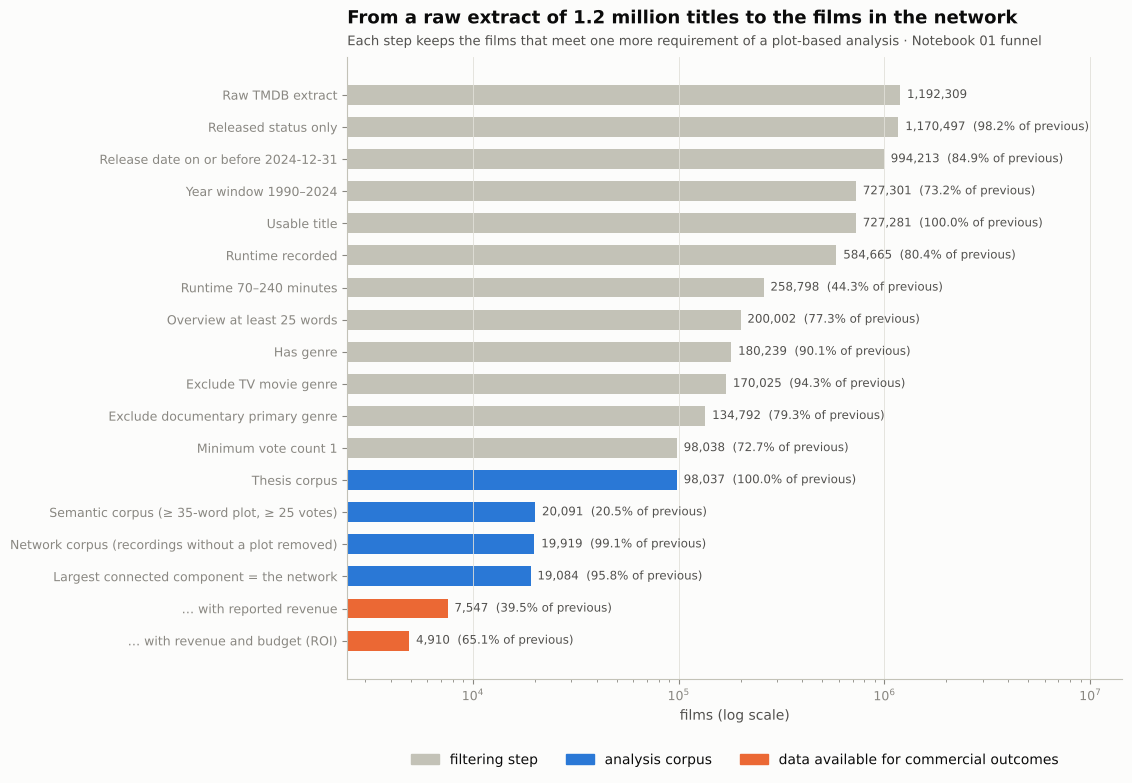

  ✓ 01_data_construction/figures/fig_01_data_funnel.png + table


In [5]:
@figure
def b1_fig01_funnel():
    need("funnel")
    f = pd.read_csv(FILES["funnel"])
    steps = [("Raw TMDB extract", int(f["rows_before"].iloc[0]), "filter")]
    for r in f.iloc[1:].itertuples():
        steps.append((re.sub(r"(\d+) (\d+)", r"\1–\2", r.step.replace("_", " ")).capitalize().replace("Tv ", "TV ").replace("tv ", "TV "), int(r.rows_after), "filter"))
    if counts.get("df_thesis_films") == steps[-1][1]:
        steps[-1] = (steps[-1][0] + " = thesis corpus", steps[-1][1], "corpus")
    tail = [("Thesis corpus", counts.get("df_thesis_films"), "corpus") if steps[-1][2] != "corpus" else None,
            ("Semantic corpus (≥ 35-word plot, ≥ 25 votes)", counts.get("df_semantic_analysis"), "corpus"),
            ("Network corpus (recordings without a plot removed)", counts.get("df_network_corpus"), "corpus"),
            ("Largest connected component = the network", len(nodes), "corpus"),
            ("… with reported revenue", int(nodes["has_revenue"].sum()), "subset")]
    if roi_ids is not None:
        tail.append(("… with revenue and budget (ROI)", len(roi_ids), "subset"))
    steps += [t for t in tail if t is not None and t[1] is not None]
    t = pd.DataFrame(steps, columns=["stage", "films", "kind"])
    t["pct_of_previous"] = (t["films"] / t["films"].shift() * 100).round(1)
    color = t["kind"].map({"filter": AXIS, "corpus": SERIES[0], "subset": SERIES[1]})
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(t) + 1.6))
    y = np.arange(len(t))[::-1]
    ax.barh(y, t["films"], color=color, height=0.62)
    for yi, r in zip(y, t.itertuples()):
        extra_ = "" if np.isnan(r.pct_of_previous) else f"  ({r.pct_of_previous:.1f}% of previous)"
        ax.text(r.films * 1.08, yi, f"{r.films:,}{extra_}", va="center", fontsize=8.5, color=INK_2)
    ax.set_xscale("log")
    ax.set_xlim(t["films"].min() / 2, t["films"].max() * 12)
    ax.set_yticks(y, [short(s, 52) for s in t["stage"]])
    ax.set_xlabel("films (log scale)")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=AXIS, label="filtering step"), Patch(color=SERIES[0], label="analysis corpus"),
                       Patch(color=SERIES[1], label="data available for commercial outcomes")],
              loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    ax.set_title("From a raw extract of 1.2 million titles to the films in the network")
    subtitle(ax, "Each step keeps the films that meet one more requirement of a plot-based analysis · Notebook 01 funnel")
    save(fig, t, "fig_01_data_funnel")

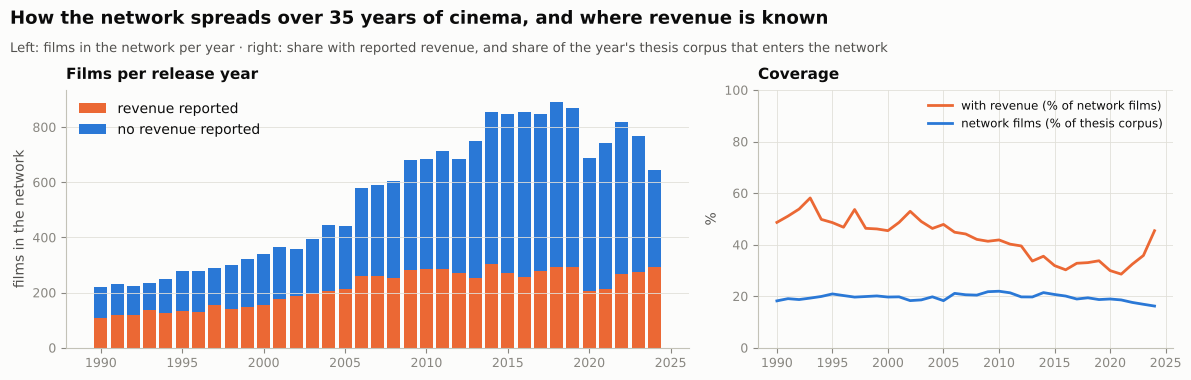

  ✓ 01_data_construction/figures/fig_02_year_coverage.png + table


In [6]:
@figure
def b1_fig02_year_coverage():
    yr = nodes.groupby("release_year").agg(films=("node_id", "size"), with_revenue=("has_revenue", "sum")).reset_index()
    yr["revenue_share"] = yr["with_revenue"] / yr["films"]
    if thesis is not None:
        yr = yr.merge(thesis.groupby("release_year").size().rename("thesis_films").reset_index(), on="release_year", how="left")
        yr["network_share_of_thesis"] = yr["films"] / yr["thesis_films"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
    ax = axes[0]
    ax.bar(yr["release_year"], yr["with_revenue"], color=SERIES[1], width=0.8, label="revenue reported")
    ax.bar(yr["release_year"], yr["films"] - yr["with_revenue"], bottom=yr["with_revenue"], color=SERIES[0],
           width=0.8, label="no revenue reported")
    ax.set_ylabel("films in the network")
    ax.set_title("Films per release year", fontsize=11, pad=8)
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)
    ax = axes[1]
    ax.plot(yr["release_year"], yr["revenue_share"] * 100, color=SERIES[1], label="with revenue (% of network films)")
    if "network_share_of_thesis" in yr:
        ax.plot(yr["release_year"], yr["network_share_of_thesis"] * 100, color=SERIES[0],
                label="network films (% of thesis corpus)")
    ax.set_ylim(0, 100)
    ax.set_ylabel("%")
    ax.set_title("Coverage", fontsize=11, pad=8)
    ax.legend(loc="upper right", fontsize=8.5)
    fig_header(fig, "How the network spreads over 35 years of cinema, and where revenue is known",
               "Left: films in the network per year · right: share with reported revenue, and share of the year's thesis corpus that enters the network")
    save(fig, yr, "fig_02_year_coverage")

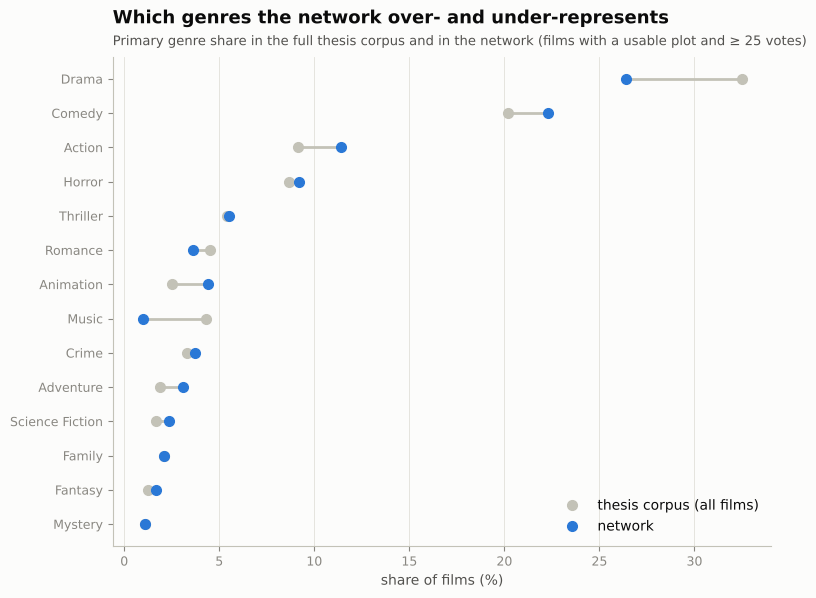

  ✓ 01_data_construction/figures/fig_03_genre_representativeness.png + table


In [7]:
@figure
def b1_fig03_genre_representativeness():
    if thesis is None:
        raise Missing("df_thesis_films.csv not found")
    a = thesis["primary_genre"].value_counts(normalize=True).rename("thesis corpus")
    b = nodes["primary_genre"].value_counts(normalize=True).rename("network")
    t = pd.concat([a, b], axis=1).fillna(0)
    t = t.loc[t.max(axis=1).sort_values(ascending=False).index[:14]].iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(t) + 1.6))
    y = np.arange(len(t))
    ax.hlines(y, t.min(axis=1) * 100, t.max(axis=1) * 100, color=AXIS, linewidth=2)
    ax.plot(t["thesis corpus"] * 100, y, "o", color=AXIS, markersize=7, label="thesis corpus (all films)")
    ax.plot(t["network"] * 100, y, "o", color=SERIES[0], markersize=7, label="network")
    ax.set_yticks(y, t.index)
    ax.set_xlabel("share of films (%)")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    ax.set_title("Which genres the network over- and under-represents")
    subtitle(ax, "Primary genre share in the full thesis corpus and in the network (films with a usable plot and ≥ 25 votes)")
    save(fig, t.iloc[::-1].reset_index().rename(columns={"index": "primary_genre"}), "fig_03_genre_representativeness")

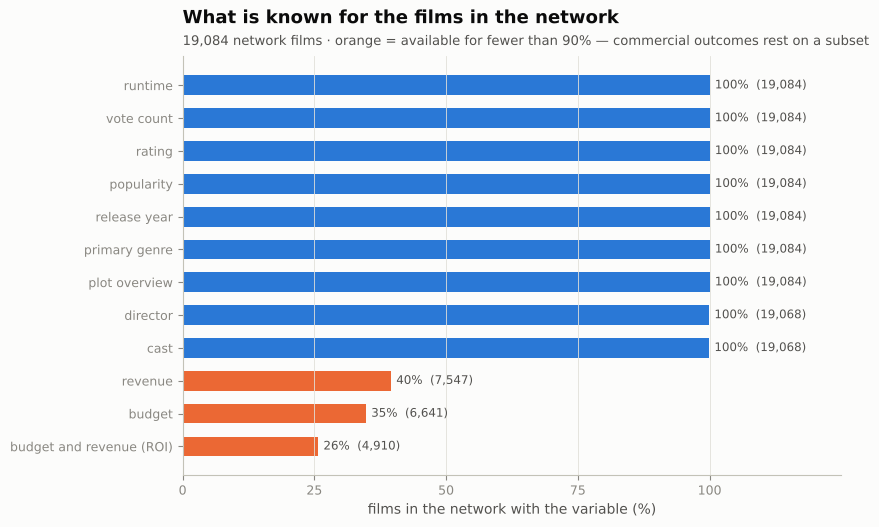

  ✓ 01_data_construction/figures/fig_04_variable_availability.png + table


In [8]:
@figure
def b1_fig04_variable_availability():
    src = mt if mt is not None else nodes
    if overview is not None and len(overview):
        src = src.assign(overview=src["tmdb_id"].map(overview))
    cand = [("overview", "plot overview"), ("release_year", "release year"), ("primary_genre", "primary genre"),
            ("runtime", "runtime"), ("vote_count", "vote count"), ("vote_average", "rating"),
            ("popularity", "popularity"), ("cast_clean", "cast"), ("director_name", "director"),
            ("revenue_clean", "revenue"), ("budget_clean", "budget")]
    rows = []
    for c, name in cand:
        if c in src:
            s = src[c]
            ok = s.notna() & ~s.astype(str).str.strip().isin(["", "nan", "0", "0.0"])
            rows.append({"variable": name, "column": c, "available_pct": ok.mean() * 100, "n_available": int(ok.sum())})
    if roi_ids is not None:
        rows.append({"variable": "budget and revenue (ROI)", "column": "log_roi",
                     "available_pct": len(roi_ids) / len(src) * 100, "n_available": len(roi_ids)})
    t = pd.DataFrame(rows).sort_values("available_pct")
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(t) + 1.6))
    colors = [SERIES[1] if p < 90 else SERIES[0] for p in t["available_pct"]]
    ax.barh(t["variable"], t["available_pct"], color=colors, height=0.6)
    for i, r in enumerate(t.itertuples()):
        ax.text(r.available_pct + 1, i, f"{r.available_pct:.0f}%  ({r.n_available:,})", va="center", fontsize=8.5, color=INK_2)
    ax.set_xlim(0, 125)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("films in the network with the variable (%)")
    ax.grid(axis="y", visible=False)
    ax.set_title("What is known for the films in the network")
    subtitle(ax, f"{len(src):,} network films · orange = available for fewer than 90% — commercial outcomes rest on a subset")
    save(fig, t, "fig_04_variable_availability")

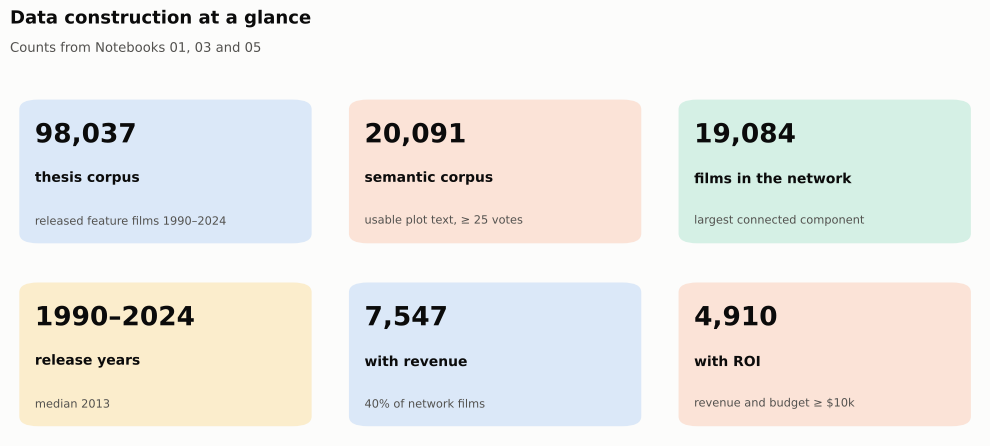

  ✓ 01_data_construction/figures/fig_05_summary_cards.png + table


In [9]:
@figure
def b1_fig05_summary_cards():
    yrs = nodes["release_year"]
    cards = [(fmt_int(counts.get("df_thesis_films")), "thesis corpus", "released feature films 1990–2024"),
             (fmt_int(counts.get("df_semantic_analysis")), "semantic corpus", "usable plot text, ≥ 25 votes"),
             (f"{len(nodes):,}", "films in the network", "largest connected component"),
             (f"{int(yrs.min())}–{int(yrs.max())}", "release years", f"median {int(yrs.median())}"),
             (f"{int(nodes['has_revenue'].sum()):,}", "with revenue", f"{nodes['has_revenue'].mean():.0%} of network films"),
             (fmt_int(len(roi_ids)) if roi_ids is not None else "—", "with ROI", "revenue and budget ≥ $10k")]
    fig = card_figure(cards, "Data construction at a glance", "Counts from Notebooks 01, 03 and 05")
    save(fig, pd.DataFrame(cards, columns=["value", "label", "note"]), "fig_05_summary_cards")

In [10]:
write_note([
    "Brick 1 — Data construction",
    "",
    f"The thesis corpus holds {fmt_int(counts.get('df_thesis_films'))} released feature films (1990–2024). "
    f"{fmt_int(counts.get('df_semantic_analysis'))} have a plot overview of at least 35 words and at least 25 votes; "
    f"after removing recordings without a plot, {fmt_int(counts.get('df_network_corpus'))} films are embedded, and the "
    f"largest connected component of the plot-similarity network holds {len(nodes):,} films.",
    f"Revenue is reported for {int(nodes['has_revenue'].sum()):,} network films ({nodes['has_revenue'].mean():.0%})"
    + (f"; revenue and budget (ROI) for {len(roi_ids):,}." if roi_ids is not None else "."),
    "Interpretation: the revenue and ROI subsets are data-availability constraints, not filtering decisions; the revenue "
    "models describe the reported-revenue market.",
    "Main text: fig_01_data_funnel, fig_02_year_coverage. Appendix: fig_03_genre_representativeness, "
    "fig_04_variable_availability, fig_05_summary_cards.",
])

Brick 1 — Data construction

The thesis corpus holds 98,037 released feature films (1990–2024). 20,091 have a plot overview of at least 35 words and at least 25 votes; after removing recordings without a plot, 19,919 films are embedded, and the largest connected component of the plot-similarity network holds 19,084 films.
Revenue is reported for 7,547 network films (40%); revenue and budget (ROI) for 4,910.
Interpretation: the revenue and ROI subsets are data-availability constraints, not filtering decisions; the revenue models describe the reported-revenue market.
Main text: fig_01_data_funnel, fig_02_year_coverage. Appendix: fig_03_genre_representativeness, fig_04_variable_availability, fig_05_summary_cards.

  ✓ 01_data_construction/text/brick_01_notes.txt


---
## Brick 2 — From plot text to similarity
**Reader question:** how does a plot overview become a similarity between two films?

One well-known film is followed through the method. Its overview becomes a 384-number vector (sentence-BERT, *all-MiniLM-L6-v2*, character names masked). Cosine similarity finds its nearest plots. The mutual *k*-nearest-neighbour rule then keeps only the links both films agree on. The last figures put these similarities on a scale: how similar real edges are compared with random pairs of films.

In [11]:
start_brick(2)
def find_film(titles):
    """Most-voted network film whose title matches one of `titles` (case-insensitive), else None."""
    low = nodes["title"].astype(str).str.lower()
    for t in titles or []:
        hit = nodes[low == str(t).lower()]
        if len(hit):
            return hit.sort_values("vote_count", ascending=False).iloc[0]
    return None

anchor = find_film(CFG["anchor_titles"])
if anchor is None:
    anchor = nodes[nodes["community_id"] == MAJOR[0]].sort_values("vote_count", ascending=False).iloc[0]
print(f"Anchor film: {anchor['title']} ({int(anchor['release_year'])}) · community {clab(anchor['community_id'])}")

def need_embeddings():
    if E is None:
        raise Missing("embeddings not found (Notebook 03)")

def top_neighbours(tmdb_id, k):
    """k most similar embedded films (rows, similarities), self excluded."""
    s = E @ E[row_of[tmdb_id]]
    s[row_of[tmdb_id]] = -np.inf
    top = np.argpartition(s, -k)[-k:]
    top = top[np.argsort(-s[top])]
    return top, s[top]

K = int(net_manifest.get("config", {}).get("k_neighbors", 20))

Brick 2 → outputs/thesis_bricks/02_nlp_similarity
Anchor film: Toy Story (1995) · community C6 · Fairy tale & fantasy


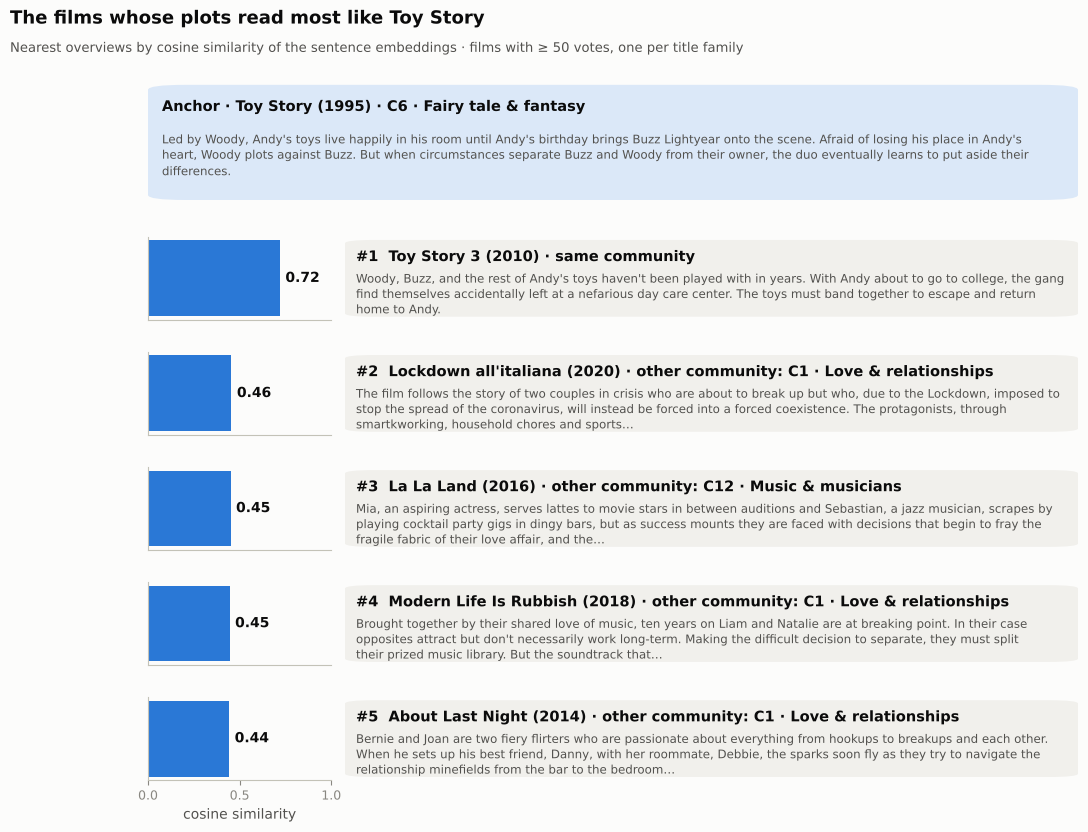

  ✓ 02_nlp_similarity/figures/fig_01_neighbour_cards.png + table


In [12]:
@figure
def b2_fig01_neighbour_cards():
    need_embeddings()
    rows, sims = top_neighbours(anchor["tmdb_id"], 60)
    cand = emb_index.iloc[rows][["tmdb_id", "title", "release_year"]].assign(cosine=sims)
    cand = cand.merge(nodes[["tmdb_id", "vote_count", "community_id", "title_family"]], on="tmdb_id", how="left")
    cand = cand[cand["vote_count"].fillna(0) >= CFG["display_min_vote_count"]].drop_duplicates("title_family")
    cand = cand.head(CFG["n_neighbour_cards"])
    n = len(cand)
    fig = plt.figure(figsize=(12, 2.0 + 1.25 * n))
    gs = fig.add_gridspec(n + 1, 2, width_ratios=[1, 4], height_ratios=[1.5] + [1] * n, hspace=0.35, wspace=0.03,
                          top=1 - 0.75 / (2.0 + 1.25 * n), bottom=0.06)
    def box(ax, title, body, color, sim=None):
        no_axes(ax)
        ax.add_patch(FancyBboxPatch((0, 0.04), 1, 0.92, boxstyle="round,pad=0,rounding_size=0.04",
                                    transform=ax.transAxes, facecolor=color, edgecolor="none"))
        ax.text(0.015, 0.84, title, transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="top")
        ax.text(0.015, 0.58, body, transform=ax.transAxes, fontsize=8.5, color=INK_2, va="top", linespacing=1.3)
    ov = lambda t, w=118: wrap(short(overview.get(t, "(overview not available)"), int(2.4 * w)), w)
    box(fig.add_subplot(gs[0, :]), f"Anchor · {anchor['title']} ({int(anchor['release_year'])}) · {clab(anchor['community_id'])}",
        ov(anchor["tmdb_id"], 150), PALE[0])
    for i, r in enumerate(cand.itertuples(), start=1):
        axb = fig.add_subplot(gs[i, 0])
        axb.barh([0], [r.cosine], color=SERIES[0], height=0.5)
        axb.set_xlim(0, 1); axb.set_yticks([]); axb.grid(False)
        axb.text(r.cosine + 0.03, 0, f"{r.cosine:.2f}", va="center", fontsize=10, fontweight="bold")
        axb.set_xticks([0, 0.5, 1] if i == n else [])
        if i == n:
            axb.set_xlabel("cosine similarity")
        same = "same community" if r.community_id == anchor["community_id"] else f"other community: {clab(r.community_id)}"
        box(fig.add_subplot(gs[i, 1]), f"#{i}  {r.title} ({int(r.release_year)}) · {same}", ov(r.tmdb_id), "#f1f0ec")
    hh = fig.get_figheight()
    fig.text(0.01, 1 - 0.05 / hh, f"The films whose plots read most like {anchor['title']}", fontsize=13, fontweight="bold", va="top")
    fig.text(0.01, 1 - 0.37 / hh, "Nearest overviews by cosine similarity of the sentence embeddings · films with ≥ 50 votes, one per title family",
             fontsize=9.5, color=INK_2, va="top")
    save(fig, cand, "fig_01_neighbour_cards")

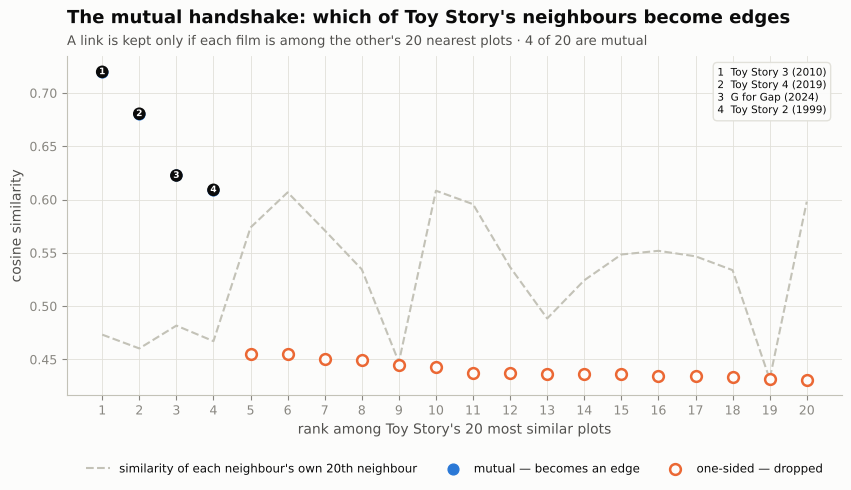

  ✓ 02_nlp_similarity/figures/fig_02_mutual_handshake.png + table


In [13]:
@figure
def b2_fig02_mutual_handshake():
    need_embeddings()
    rows, sims = top_neighbours(anchor["tmdb_id"], K)
    a_row = row_of[anchor["tmdb_id"]]
    S = E[rows] @ E.T
    S[np.arange(len(rows)), rows] = -np.inf                         # each neighbour excluded from its own list
    kth = np.partition(S, -K, axis=1)[:, -K]                        # similarity of each neighbour's K-th neighbour
    mutual = S[:, a_row] >= kth
    t = emb_index.iloc[rows][["tmdb_id", "title", "release_year"]].assign(rank=np.arange(1, K + 1), cosine=sims,
                                                                       mutual=mutual, their_kth_similarity=kth)
    fig, ax = plt.subplots(figsize=(10, 4.4))
    ax.plot(t["rank"], t["their_kth_similarity"], color=AXIS, linewidth=1.5, linestyle="--",
            label=f"similarity of each neighbour's own {K}th neighbour")
    ax.scatter(t.loc[t["mutual"], "rank"], t.loc[t["mutual"], "cosine"], s=60, color=SERIES[0], zorder=3,
               label="mutual — becomes an edge")
    ax.scatter(t.loc[~t["mutual"], "rank"], t.loc[~t["mutual"], "cosine"], s=60, facecolor=SURFACE,
               edgecolor=SERIES[1], linewidth=1.8, zorder=3, label="one-sided — dropped")
    top_ = t[t["mutual"]].head(6)
    numbered_labels(ax, top_["rank"], top_["cosine"], [f"{short(a, 34)} ({int(b)})" for a, b in zip(top_["title"], top_["release_year"])],
                    where=(0.98, 0.97), va="top", ha="right")
    ax.set_xticks(range(1, K + 1))
    ax.set_xlabel(f"rank among {anchor['title']}'s {K} most similar plots")
    ax.set_ylabel("cosine similarity")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8.5)
    ax.set_title(f"The mutual handshake: which of {anchor['title']}'s neighbours become edges")
    subtitle(ax, f"A link is kept only if each film is among the other's {K} nearest plots · "
                 f"{int(mutual.sum())} of {K} are mutual")
    save(fig, t, "fig_02_mutual_handshake")

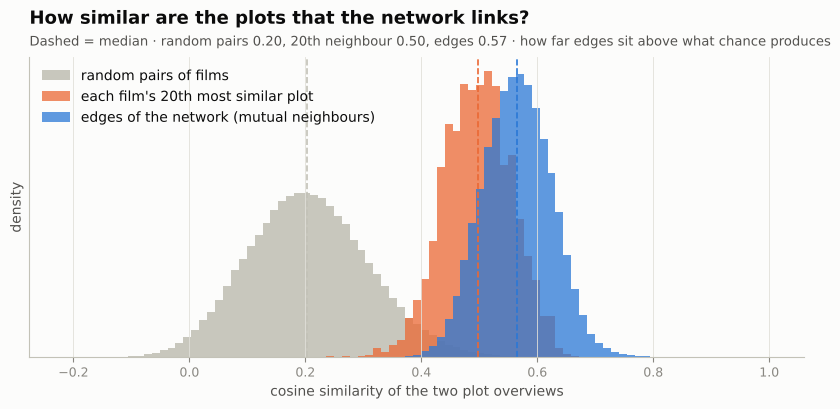

  ✓ 02_nlp_similarity/figures/fig_03_similarity_scale.png + table


In [14]:
@figure
def b2_fig03_similarity_scale():
    need_embeddings()
    rng = np.random.default_rng(CFG["random_state"])
    n = len(E)
    i, j = rng.integers(0, n, CFG["random_pairs"]), rng.integers(0, n, CFG["random_pairs"])
    keep = i != j
    rand = np.einsum("ij,ij->i", E[i[keep]], E[j[keep]])
    sample = rng.choice(n, min(3000, n), replace=False)
    S = E[sample] @ E.T
    S[np.arange(len(sample)), sample] = -np.inf
    kth = np.partition(S, -K, axis=1)[:, -K]
    w = e["w"].values
    bins = np.linspace(min(rand.min(), 0) - 0.02, 1, 90)
    fig, ax = plt.subplots(figsize=(10, 3.9))
    for vals, color, name in [(rand, AXIS, "random pairs of films"), (kth, SERIES[1], f"each film's {K}th most similar plot"),
                              (w, SERIES[0], "edges of the network (mutual neighbours)")]:
        ax.hist(vals, bins=bins, density=True, color=color, alpha=0.75 if color != AXIS else 0.9, label=name)
        ax.axvline(np.median(vals), color=color, linewidth=1.2, linestyle="--")
    ax.set_xlabel("cosine similarity of the two plot overviews")
    ax.set_ylabel("density")
    ax.set_yticks([])
    ax.legend(loc="upper left")
    ax.set_title("How similar are the plots that the network links?")
    subtitle(ax, f"Dashed = median · random pairs {np.median(rand):.2f}, {K}th neighbour {np.median(kth):.2f}, "
                 f"edges {np.median(w):.2f} · how far edges sit above what chance produces")
    t = pd.DataFrame({"distribution": ["random pairs", f"{K}th neighbour", "network edges"],
                      "n": [len(rand), len(kth), len(w)],
                      "median": [np.median(rand), np.median(kth), np.median(w)],
                      "p05": [np.quantile(rand, .05), np.quantile(kth, .05), np.quantile(w, .05)],
                      "p95": [np.quantile(rand, .95), np.quantile(kth, .95), np.quantile(w, .95)]})
    save(fig, t.round(4), "fig_03_similarity_scale")

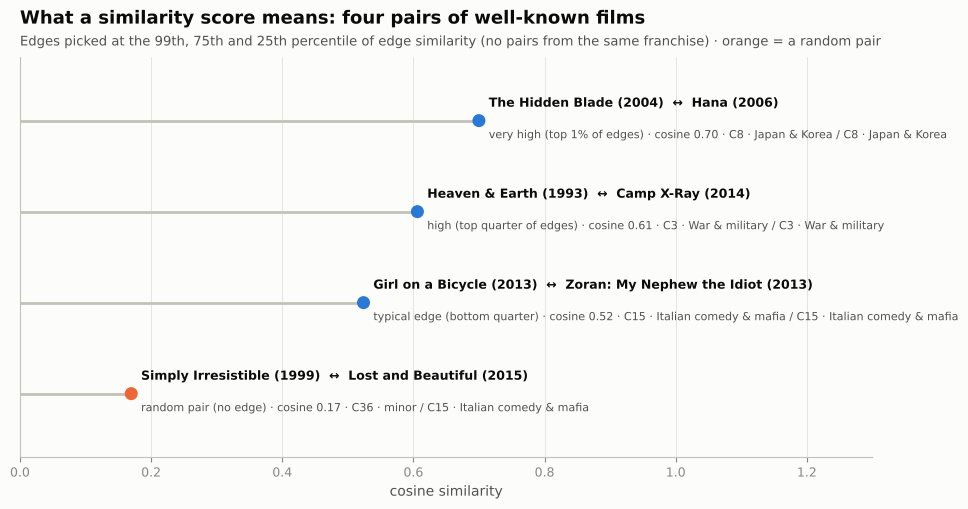

  ✓ 02_nlp_similarity/figures/fig_04_example_pairs.png + table


In [15]:
@figure
def b2_fig04_example_pairs():
    vis_ids = set(nodes.loc[nodes["visible"], "node_id"])
    ev = e[e["a"].isin(vis_ids) & e["b"].isin(vis_ids)].copy()
    fam = node_ix["title_family"]
    ev = ev[fam.reindex(ev["a"]).values != fam.reindex(ev["b"]).values]          # no sequel pairs …
    words_ = node_ix["title"].astype(str).str.lower().str.findall(r"[a-z]{5,}").map(set)
    ev = ev[[not (words_[a_] & words_[b_]) for a_, b_ in zip(ev["a"], ev["b"])]]  # … nor titles sharing a long word
    rows = []
    for q, name in [(0.99, "very high (top 1% of edges)"), (0.75, "high (top quarter of edges)"),
                    (0.25, "typical edge (bottom quarter)")]:
        target = ev["w"].quantile(q)
        r = ev.iloc[(ev["w"] - target).abs().argsort().values[0]]
        rows.append((name, r["a"], r["b"], r["w"], "edge"))
    if E is not None:
        rng = np.random.default_rng(CFG["random_state"])
        vis = nodes[nodes["visible"]]
        for _ in range(200):
            a_, b_ = vis.sample(2, random_state=int(rng.integers(1e9))).itertuples()
            s = float(E[row_of[a_.tmdb_id]] @ E[row_of[b_.tmdb_id]])
            if s < np.quantile(ev["w"], 0.01) - 0.1:
                rows.append(("random pair (no edge)", a_.node_id, b_.node_id, s, "random"))
                break
    t = pd.DataFrame(rows, columns=["level", "a", "b", "cosine", "kind"])
    t["film_a"] = t["a"].map(node_ix["label"]); t["film_b"] = t["b"].map(node_ix["label"])
    t["community_a"] = t["a"].map(comm_of).map(clab); t["community_b"] = t["b"].map(comm_of).map(clab)
    fig, ax = plt.subplots(figsize=(11, 0.95 * len(t) + 1.4))
    y = np.arange(len(t))[::-1]
    ax.hlines(y, 0, t["cosine"], color=AXIS, linewidth=2)
    ax.scatter(t["cosine"], y, s=70, color=[SERIES[0] if k == "edge" else SERIES[1] for k in t["kind"]], zorder=3)
    for yi, r in zip(y, t.itertuples()):
        ax.text(r.cosine + 0.015, yi + 0.12, f"{r.film_a}  ↔  {r.film_b}", fontsize=9, va="bottom", fontweight="bold")
        ax.text(r.cosine + 0.015, yi - 0.1, f"{r.level} · cosine {r.cosine:.2f} · {short(r.community_a, 28)} / {short(r.community_b, 28)}",
                fontsize=8, color=INK_2, va="top")
    ax.set_xlim(min(0, t["cosine"].min() - 0.05), 1.3)
    ax.set_ylim(-0.7, len(t) - 0.3)
    ax.set_yticks([])
    ax.set_xlabel("cosine similarity")
    ax.grid(axis="y", visible=False)
    ax.set_title("What a similarity score means: four pairs of well-known films")
    subtitle(ax, "Edges picked at the 99th, 75th and 25th percentile of edge similarity (no pairs from the same franchise) · orange = a random pair")
    save(fig, t.drop(columns=["a", "b"]), "fig_04_example_pairs")

In [16]:
@figure
def b2_fig05_embedding_map():
    need_embeddings()
    from sklearn.manifold import TSNE
    show_c = MAJOR[:CFG["map_communities"]]
    pick = (nodes[nodes["community_id"].isin(show_c)].groupby("community_id", group_keys=False)
            .apply(lambda d: d.sample(min(len(d), CFG["map_films_per_community"]), random_state=CFG["random_state"])))
    X = E[pick["tmdb_id"].map(row_of).values]
    xy = TSNE(n_components=2, perplexity=40, init="pca", random_state=CFG["random_state"], metric="cosine").fit_transform(X)
    pick = pick.assign(x=xy[:, 0], y=xy[:, 1])
    fig, ax = plt.subplots(figsize=(10.5, 8))
    for k, c in enumerate(show_c):
        d = pick[pick["community_id"] == c]
        ax.scatter(d["x"], d["y"], s=7, color=CATEGORICAL[k % len(CATEGORICAL)], alpha=0.55, linewidth=0)
        ax.annotate(wrap(CLAB[c], 24), (d["x"].median(), d["y"].median()), ha="center", va="center", fontsize=8.5,
                    fontweight="bold", color=INK, bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec=CATEGORICAL[k % len(CATEGORICAL)], alpha=0.9))
    no_axes(ax)
    ax.set_title("Plot space: films with similar stories lie close together")
    # t-SNE places the points slightly differently with each scikit-learn version and CPU: the neighbourhoods are
    # stable, the arrangement on the page is not. Describe the map by which communities sit together, not by where.
    subtitle(ax, f"t-SNE projection of the 384-dimension plot embeddings · {CFG['map_films_per_community']} films from each of the "
                 f"{len(show_c)} largest communities · colour = community (found from the network, not from this map)")
    save(fig, pick[["tmdb_id", "title", "release_year", "community_id", "x", "y"]].round(3), "fig_05_embedding_map")

  ✗ b2_fig05_embedding_map skipped: KeyError('community_id')


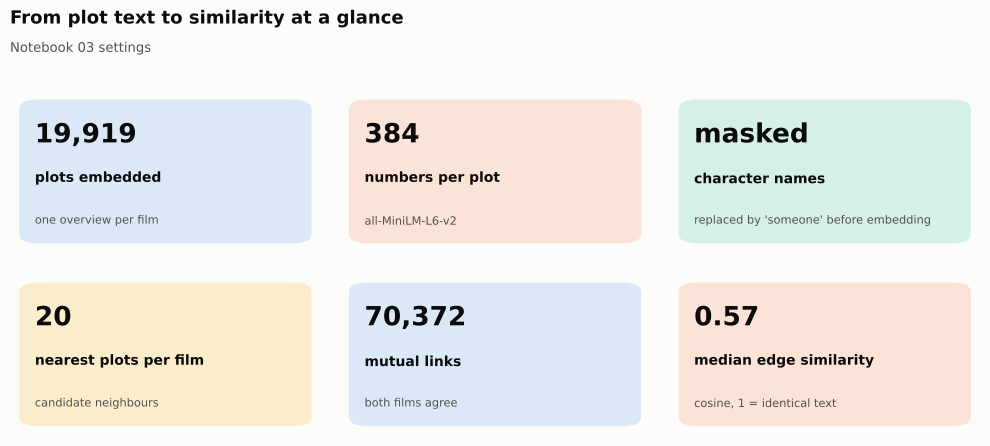

  ✓ 02_nlp_similarity/figures/fig_06_summary_cards.png + table


In [17]:
@figure
def b2_fig06_summary_cards():
    cfg = net_manifest.get("config", {})
    cards = [(fmt_int(audit.get("input_network_corpus_films", counts.get("df_network_corpus"))), "plots embedded", "one overview per film"),
             (str(E.shape[1]) if E is not None else "384", "numbers per plot", short(cfg.get("sbert_model", "sentence-BERT").split("/")[-1], 40)),
             ("masked" if cfg.get("mask_person_names") else "kept", "character names", "replaced by 'someone' before embedding"),
             (str(K), "nearest plots per film", "candidate neighbours"),
             (fmt_int(audit.get("mutual_knn_edges_full_graph")), "mutual links", "both films agree"),
             (f"{e['w'].median():.2f}", "median edge similarity", "cosine, 1 = identical text")]
    fig = card_figure(cards, "From plot text to similarity at a glance", "Notebook 03 settings")
    save(fig, pd.DataFrame(cards, columns=["value", "label", "note"]), "fig_06_summary_cards")

In [18]:
write_note([
    "Brick 2 — From plot text to similarity",
    "",
    f"Anchor film: {anchor['title']} ({int(anchor['release_year'])}), community {clab(anchor['community_id'])}.",
    f"Each overview is embedded with {net_manifest.get('config', {}).get('sbert_model', 'sentence-BERT')} after person names are "
    f"masked; similarity is the cosine of two embeddings. Each film lists its {K} most similar plots and a link is kept only "
    "when both films list each other (mutual k-nearest neighbours).",
    f"Median cosine similarity of network edges: {e['w'].median():.2f}. Figure 3 compares it with random pairs of films "
    "(chance level).",
    "Interpretation: 'two films are linked when their plot overviews describe similar stories', not 'similar films'. The network "
    "uses the plot overview only: no genre labels, cast or outcomes.",
    "Main text: fig_01_neighbour_cards, fig_02_mutual_handshake, fig_03_similarity_scale. Appendix: fig_04_example_pairs, "
    "fig_05_embedding_map, fig_06_summary_cards.",
])

Brick 2 — From plot text to similarity

Anchor film: Toy Story (1995), community C6 · Fairy tale & fantasy.
Each overview is embedded with sentence-transformers/all-MiniLM-L6-v2 after person names are masked; similarity is the cosine of two embeddings. Each film lists its 20 most similar plots and a link is kept only when both films list each other (mutual k-nearest neighbours).
Median cosine similarity of network edges: 0.57. Figure 3 compares it with random pairs of films (chance level).
Interpretation: 'two films are linked when their plot overviews describe similar stories', not 'similar films'. The network uses the plot overview only: no genre labels, cast or outcomes.
Main text: fig_01_neighbour_cards, fig_02_mutual_handshake, fig_03_similarity_scale. Appendix: fig_04_example_pairs, fig_05_embedding_map, fig_06_summary_cards.

  ✓ 02_nlp_similarity/text/brick_02_notes.txt


---
## Brick 3 — Network construction
**Reader question:** how do similarities become a clean, analysable network?

No full 19k-node hairball. This brick shows the construction steps with their numbers and the shape of the resulting network: degrees capped by *k*, edge strength inside and between communities, local clustering. It also tests whether edges simply join films of the same genre or decade.

In [19]:
start_brick(3)
deg = nodes["degree"] if "degree" in nodes else nodes["node_id"].map(dict(G.degree()))

Brick 3 → outputs/thesis_bricks/03_network_construction


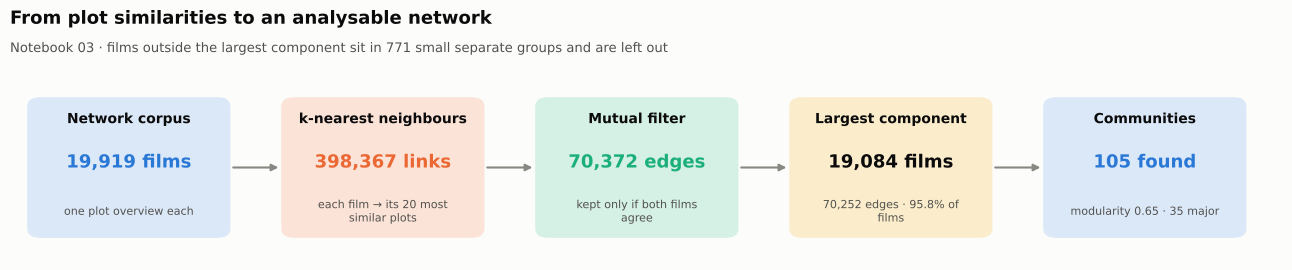

  ✓ 03_network_construction/figures/fig_01_construction_flow.png + table


In [20]:
@figure
def b3_fig01_construction_flow():
    a = lambda k, d=None: audit.get(k, d)
    steps = [("Network corpus", f"{fmt_int(a('input_network_corpus_films', counts.get('df_network_corpus')))} films", "one plot overview each"),
             ("k-nearest neighbours", f"{fmt_int(a('directed_knn_edges'))} links", f"each film → its {K} most similar plots"),
             ("Mutual filter", f"{fmt_int(a('mutual_knn_edges_full_graph'))} edges", "kept only if both films agree"),
             ("Largest component", f"{len(nodes):,} films", f"{len(edges):,} edges · {float(a('largest_component_share', len(nodes) / max(1, int(a('full_graph_nodes', len(nodes)))))):.1%} of films"),
             ("Communities", f"{nodes['community_id'].nunique()} found", f"modularity {float(net_manifest.get('modularity', np.nan)):.2f} · {len(MAJOR)} major")]
    fig, ax = plt.subplots(figsize=(13, 2.7))
    no_axes(ax)
    ax.set_xlim(0, len(steps)); ax.set_ylim(0, 1)
    for i, (head, big, small_) in enumerate(steps):
        ax.add_patch(FancyBboxPatch((i + 0.06, 0.12), 0.8, 0.76, boxstyle="round,pad=0,rounding_size=0.05",
                                    facecolor=PALE[i % 4], edgecolor="none"))
        ax.text(i + 0.46, 0.74, head, ha="center", fontsize=10, fontweight="bold")
        ax.text(i + 0.46, 0.5, big, ha="center", fontsize=13, fontweight="bold", color=SERIES[i % 4] if i % 4 != 3 else INK)
        ax.text(i + 0.46, 0.26, wrap(small_, 26), ha="center", va="center", fontsize=8, color=INK_2)
        if i < len(steps) - 1:
            ax.annotate("", xy=(i + 1.06, 0.5), xytext=(i + 0.86, 0.5), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.5))
    small_comp = int(a("full_graph_components", 1)) - 1 if a("full_graph_components") is not None else None
    fig_header(fig, "From plot similarities to an analysable network",
               f"Notebook 03 · films outside the largest component sit in {fmt_int(small_comp)} small separate groups and are left out",
               band_in=0.7)
    save(fig, pd.DataFrame(steps, columns=["step", "count", "note"]), "fig_01_construction_flow")

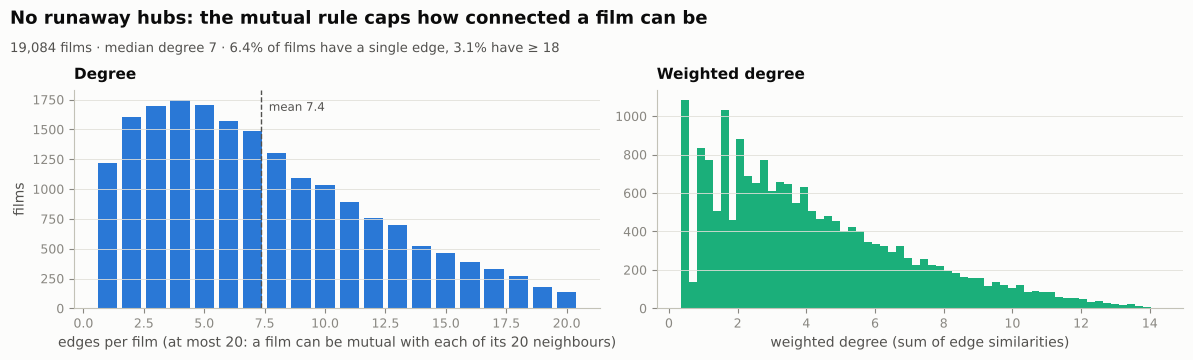

  ✓ 03_network_construction/figures/fig_02_degree_distribution.png + table


In [21]:
@figure
def b3_fig02_degree_distribution():
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    vc = deg.value_counts().sort_index()
    axes[0].bar(vc.index, vc.values, color=SERIES[0], width=0.8)
    axes[0].axvline(deg.mean(), color=INK_2, linewidth=1, linestyle="--")
    axes[0].text(deg.mean(), vc.max() * 0.95, f"  mean {deg.mean():.1f}", fontsize=8.5, color=INK_2)
    axes[0].set_xlabel(f"edges per film (at most {K}: a film can be mutual with each of its {K} neighbours)")
    axes[0].set_ylabel("films")
    axes[0].set_title("Degree", fontsize=11, pad=8)
    axes[0].grid(axis="x", visible=False)
    wd = nodes["weighted_degree"]
    axes[1].hist(wd, bins=60, color=SERIES[2])
    axes[1].set_xlabel("weighted degree (sum of edge similarities)")
    axes[1].set_title("Weighted degree", fontsize=11, pad=8)
    axes[1].grid(axis="x", visible=False)
    fig_header(fig, "No runaway hubs: the mutual rule caps how connected a film can be",
               f"{len(nodes):,} films · median degree {deg.median():.0f} · {(deg == 1).mean():.1%} of films have a single edge, {(deg >= K - 2).mean():.1%} have ≥ {K - 2}")
    save(fig, vc.rename_axis("degree").reset_index(name="films"), "fig_02_degree_distribution")

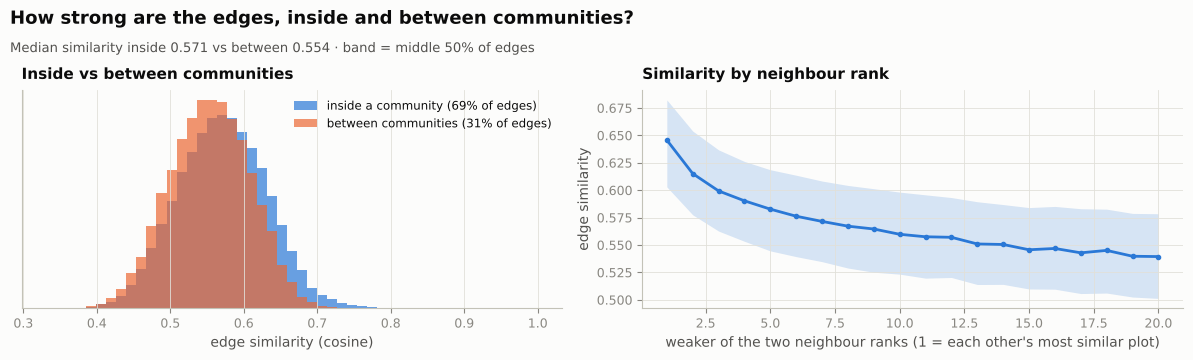

  ✓ 03_network_construction/figures/fig_03_edge_strength.png + table


In [22]:
@figure
def b3_fig03_edge_strength():
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    bins = np.linspace(e["w"].min(), e["w"].max(), 50)
    for flag, color, name in [(True, SERIES[0], "inside a community"), (False, SERIES[1], "between communities")]:
        axes[0].hist(e.loc[e["internal"] == flag, "w"], bins=bins, density=True, alpha=0.7, color=color,
                     label=f"{name} ({(e['internal'] == flag).mean():.0%} of edges)")
    axes[0].set_xlabel("edge similarity (cosine)")
    axes[0].set_yticks([])
    axes[0].legend(loc="upper right", fontsize=8.5)
    axes[0].set_title("Inside vs between communities", fontsize=11, pad=8)
    r = e.assign(rank=np.maximum(e["source_rank"], e["target_rank"]))
    g = r.groupby("rank")["w"].agg(["median", lambda x: x.quantile(.25), lambda x: x.quantile(.75), "size"])
    g.columns = ["median", "q25", "q75", "edges"]
    axes[1].fill_between(g.index, g["q25"], g["q75"], color=SERIES[0], alpha=0.18, linewidth=0)
    axes[1].plot(g.index, g["median"], color=SERIES[0], marker="o", markersize=3)
    axes[1].set_xlabel("weaker of the two neighbour ranks (1 = each other's most similar plot)")
    axes[1].set_ylabel("edge similarity")
    axes[1].set_title("Similarity by neighbour rank", fontsize=11, pad=8)
    fig_header(fig, "How strong are the edges, inside and between communities?",
               f"Median similarity inside {e.loc[e['internal'], 'w'].median():.3f} vs between {e.loc[~e['internal'], 'w'].median():.3f} · band = middle 50% of edges")
    save(fig, g.reset_index().round(4), "fig_03_edge_strength")

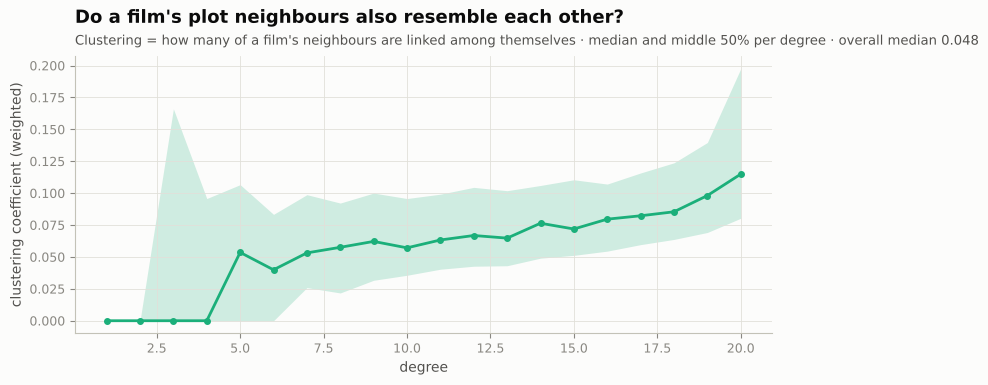

  ✓ 03_network_construction/figures/fig_04_clustering_by_degree.png + table


In [23]:
@figure
def b3_fig04_clustering_by_degree():
    d = nodes.assign(degree_=deg)
    g = d.groupby("degree_")["clustering_coefficient"].agg(["median", lambda x: x.quantile(.25), lambda x: x.quantile(.75), "size"])
    g.columns = ["median", "q25", "q75", "films"]
    g = g[g["films"] >= 20]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.fill_between(g.index, g["q25"], g["q75"], color=SERIES[2], alpha=0.2, linewidth=0)
    ax.plot(g.index, g["median"], color=SERIES[2], marker="o", markersize=4)
    ax.set_xlabel("degree")
    ax.set_ylabel("clustering coefficient (weighted)")
    ax.set_title("Do a film's plot neighbours also resemble each other?")
    subtitle(ax, "Clustering = how many of a film's neighbours are linked among themselves · median and middle 50% per degree "
                 f"· overall median {nodes['clustering_coefficient'].median():.3f}")
    save(fig, g.reset_index().round(4), "fig_04_clustering_by_degree")

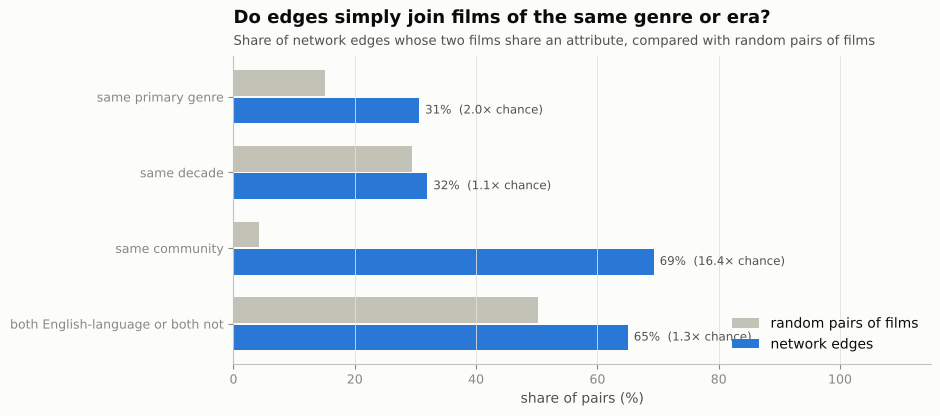

  ✓ 03_network_construction/figures/fig_05_edge_homophily.png + table


In [24]:
@figure
def b3_fig05_edge_homophily():
    meta = nodes.set_index("node_id")
    rows = []
    attrs = {"same primary genre": meta["primary_genre"], "same decade": (meta["release_year"] // 10),
             "same community": meta["community_id"]}
    if mt is not None and "is_english" in mt:
        attrs["both English-language or both not"] = meta["tmdb_id"].map(mt.drop_duplicates("tmdb_id").set_index("tmdb_id")["is_english"])
    for name, s in attrs.items():
        obs = (s.reindex(e["a"]).values == s.reindex(e["b"]).values).mean()
        p_ = s.value_counts(normalize=True)
        rows.append({"attribute": name, "share_of_edges": obs, "expected_random_pairs": float((p_ ** 2).sum())})
    t = pd.DataFrame(rows)
    t["ratio"] = t["share_of_edges"] / t["expected_random_pairs"]
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(t) + 1.6))
    y = np.arange(len(t))[::-1]
    ax.barh(y + 0.18, t["expected_random_pairs"] * 100, height=0.34, color=AXIS, label="random pairs of films")
    ax.barh(y - 0.18, t["share_of_edges"] * 100, height=0.34, color=SERIES[0], label="network edges")
    for yi, r in zip(y, t.itertuples()):
        ax.text(r.share_of_edges * 100 + 1, yi - 0.18, f"{r.share_of_edges:.0%}  ({r.ratio:.1f}× chance)", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(y, t["attribute"])
    ax.set_xlim(0, 115)
    ax.set_xlabel("share of pairs (%)")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    ax.set_title("Do edges simply join films of the same genre or era?")
    subtitle(ax, "Share of network edges whose two films share an attribute, compared with random pairs of films")
    save(fig, t.round(4), "fig_05_edge_homophily")

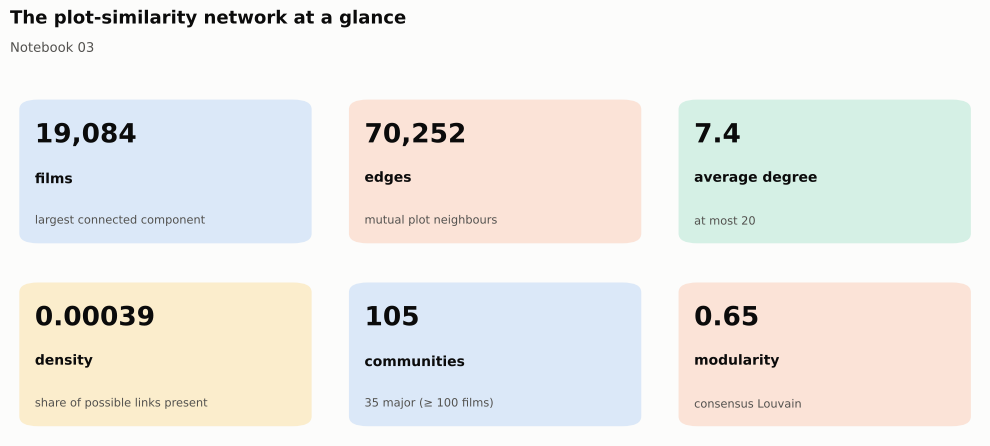

  ✓ 03_network_construction/figures/fig_06_summary_cards.png + table


In [25]:
@figure
def b3_fig06_summary_cards():
    cards = [(f"{len(nodes):,}", "films", "largest connected component"),
             (f"{len(edges):,}", "edges", "mutual plot neighbours"),
             (f"{2 * len(edges) / len(nodes):.1f}", "average degree", f"at most {K}"),
             (f"{nx.density(G):.5f}", "density", "share of possible links present"),
             (f"{nodes['community_id'].nunique()}", "communities", f"{len(MAJOR)} major (≥ 100 films)"),
             (f"{float(net_manifest.get('modularity', np.nan)):.2f}", "modularity", "consensus Louvain")]
    fig = card_figure(cards, "The plot-similarity network at a glance", "Notebook 03")
    save(fig, pd.DataFrame(cards, columns=["value", "label", "note"]), "fig_06_summary_cards")

In [26]:
write_note([
    "Brick 3 — Network construction",
    "",
    f"Mutual {K}-nearest-neighbour network: {fmt_int(audit.get('directed_knn_edges'))} directed candidate links → "
    f"{fmt_int(audit.get('mutual_knn_edges_full_graph'))} mutual edges. The largest connected component holds {len(nodes):,} films "
    f"and {len(edges):,} edges (average degree {2 * len(edges) / len(nodes):.2f}, density {nx.density(G):.6f}).",
    f"{e['internal'].mean():.0%} of edges lie inside a community; edges inside are stronger (median cosine "
    f"{e.loc[e['internal'], 'w'].median():.3f} vs {e.loc[~e['internal'], 'w'].median():.3f}).",
    "Interpretation: the mutual rule removes one-sided links to generic, hub-like plots, so no film can have more than k edges.",
    "Main text: fig_01_construction_flow, fig_05_edge_homophily. Appendix: fig_02–04, fig_06.",
])

Brick 3 — Network construction

Mutual 20-nearest-neighbour network: 398,367 directed candidate links → 70,372 mutual edges. The largest connected component holds 19,084 films and 70,252 edges (average degree 7.36, density 0.000386).
69% of edges lie inside a community; edges inside are stronger (median cosine 0.571 vs 0.554).
Interpretation: the mutual rule removes one-sided links to generic, hub-like plots, so no film can have more than k edges.
Main text: fig_01_construction_flow, fig_05_edge_homophily. Appendix: fig_02–04, fig_06.

  ✓ 03_network_construction/text/brick_03_notes.txt


---
## Brick 4 — Narrative communities
**Reader question:** which kinds of story does the network contain?

Communities come from consensus Louvain (Notebook 03). Labels come from the reviewed labels file (Notebook 04). *Tentative* communities (robustness < 0.5) are real regions of plot space with blurred borders. They are marked, so the text can describe them with care.

In [27]:
start_brick(4)
cs = (nodes.groupby("community_id").agg(n_films=("node_id", "size"), median_year=("release_year", "median"),
                                        median_votes=("vote_count", "median"))
      .join(lab[[c for c in ["community_robustness", "key_terms", "well_known_examples"] if c in lab]], how="left"))
cs["share_pct"] = cs["n_films"] / len(nodes) * 100

Brick 4 → outputs/thesis_bricks/04_narrative_communities


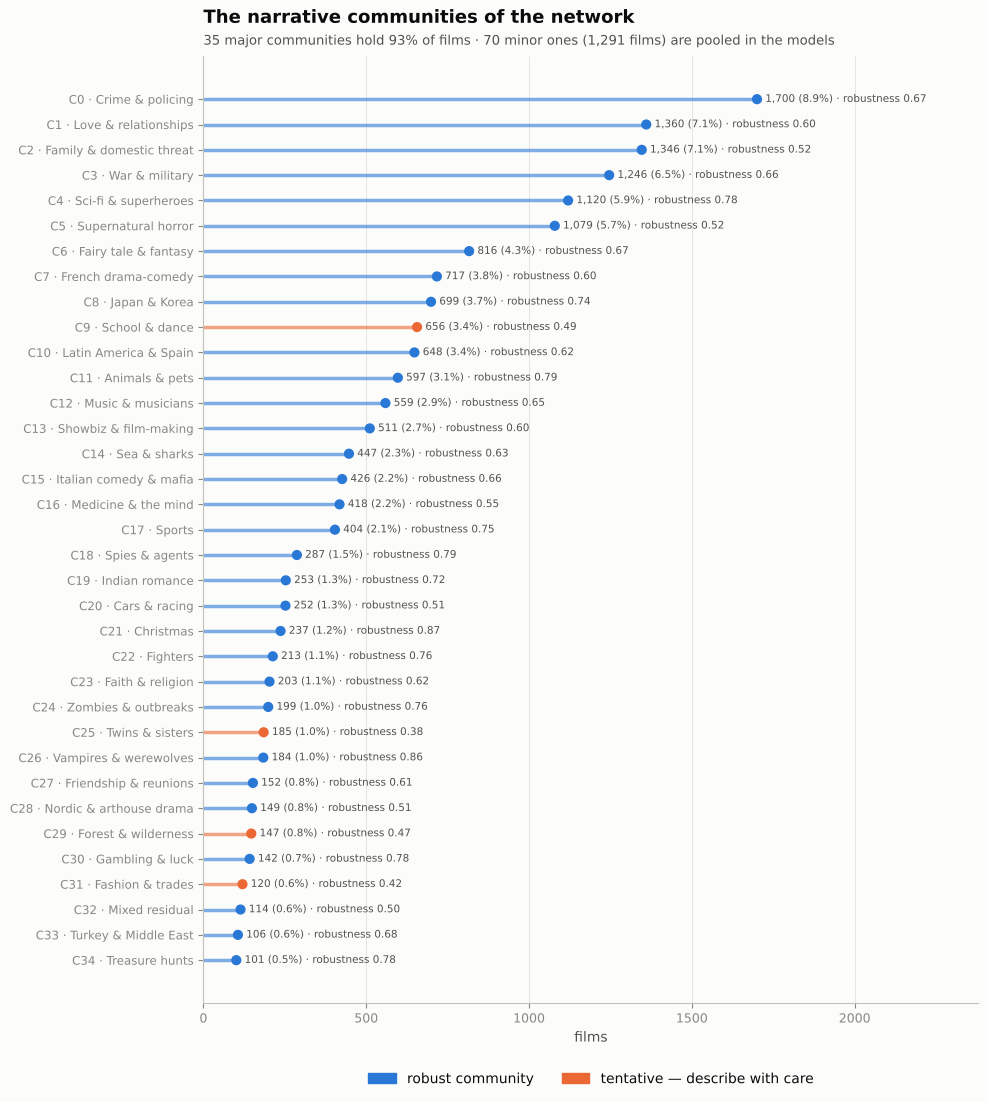

  ✓ 04_narrative_communities/figures/fig_01_major_communities.png + table


In [28]:
@figure
def b4_fig01_major_communities():
    t = cs.loc[MAJOR].reset_index()
    fig, ax = plt.subplots(figsize=(10, 0.3 * len(t) + 1.8))
    y = np.arange(len(t))[::-1]
    tent = t["community_id"].isin(TENTATIVE)
    ax.hlines(y, 0, t["n_films"], color=np.where(tent, SERIES[1], SERIES[0]), linewidth=2.5, alpha=0.6)
    ax.scatter(t["n_films"], y, s=40, color=np.where(tent, SERIES[1], SERIES[0]), zorder=3)
    for yi, r in zip(y, t.itertuples()):
        rob = f" · robustness {r.community_robustness:.2f}" if "community_robustness" in t and pd.notna(r.community_robustness) else ""
        ax.text(r.n_films + t["n_films"].max() * 0.015, yi, f"{r.n_films:,} ({r.share_pct:.1f}%){rob}", va="center", fontsize=7.5, color=INK_2)
    ax.set_yticks(y, [CLAB[c] for c in t["community_id"]], fontsize=8.5)
    ax.set_xlim(0, t["n_films"].max() * 1.4)
    ax.set_xlabel("films")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=SERIES[0], label="robust community"), Patch(color=SERIES[1], label="tentative — describe with care")],
              loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2)
    ax.set_title("The narrative communities of the network")
    minor_n = len(nodes) - t["n_films"].sum()
    subtitle(ax, f"{len(MAJOR)} major communities hold {t['n_films'].sum() / len(nodes):.0%} of films · "
                 f"{nodes['community_id'].nunique() - len(MAJOR)} minor ones ({minor_n:,} films) are pooled in the models")
    save(fig, t, "fig_01_major_communities")

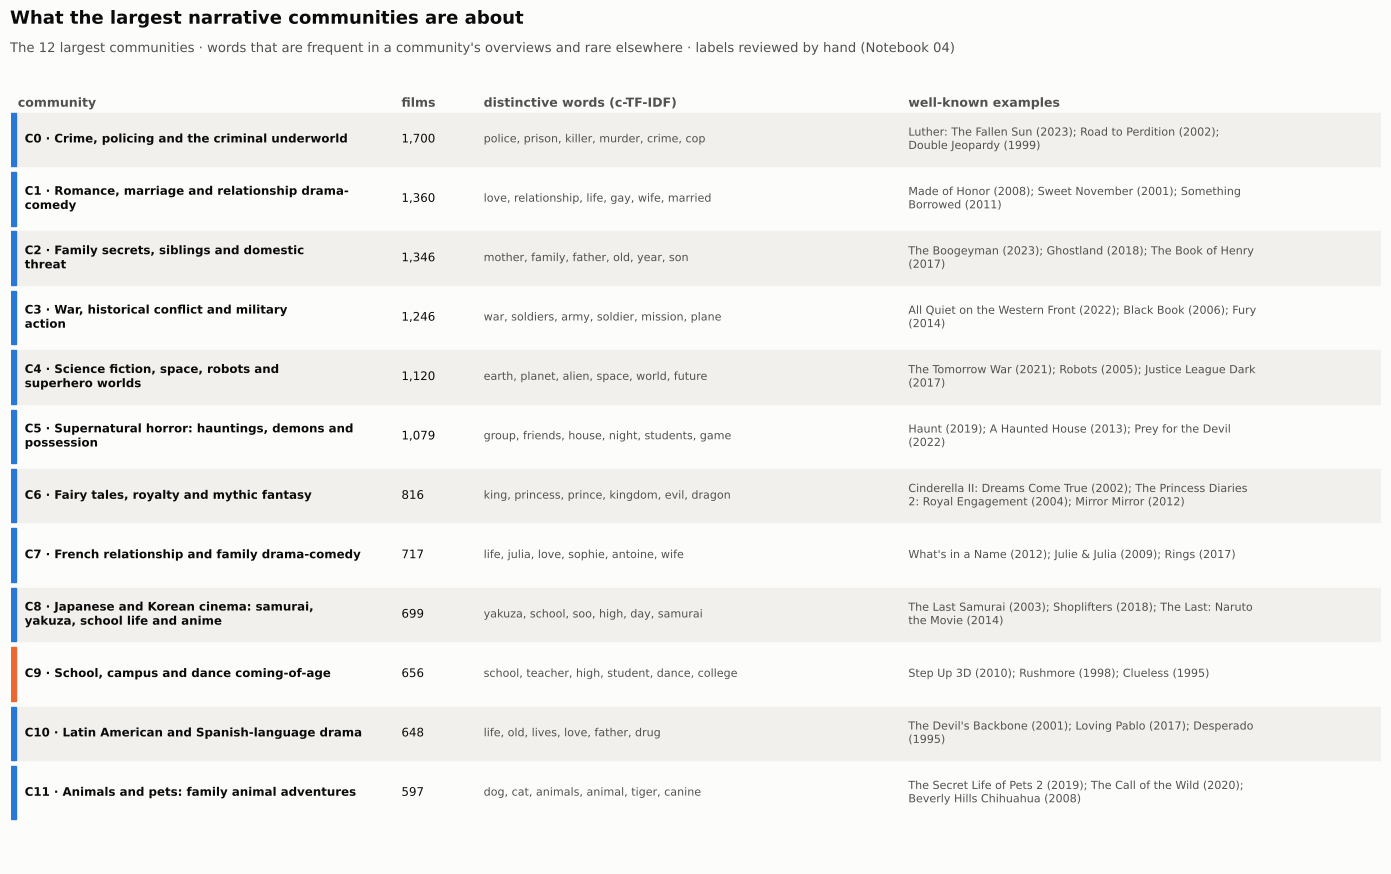

  ✓ 04_narrative_communities/figures/fig_02_community_index_table.png + table


In [29]:
@figure
def b4_fig02_community_index_table():
    n = CFG["table_communities"]
    t = cs.loc[MAJOR[:n]].reset_index()
    t["label"] = t["community_id"].map(FULL)
    terms = t["key_terms"] if "key_terms" in t else pd.Series("", index=t.index)
    ex = t["well_known_examples"] if "well_known_examples" in t else pd.Series("", index=t.index)
    t["terms_short"] = terms.fillna("").map(lambda s: ", ".join(str(s).split("; ")[:6]))
    t["examples_short"] = ex.fillna("").map(lambda s: "; ".join(str(s).split("; ")[:3]))
    fig, ax = plt.subplots(figsize=(14, 0.62 * n + 1.3))
    no_axes(ax)
    cols = [(0.0, "community", 0.27), (0.28, "films", 0.05), (0.34, "distinctive words (c-TF-IDF)", 0.3), (0.65, "well-known examples", 0.35)]
    ax.set_xlim(0, 1); ax.set_ylim(n + 0.2, -1)
    for x, h, _ in cols:
        ax.text(x + 0.005, -0.55, h, fontsize=9, fontweight="bold", color=INK_2)
    for i, r in enumerate(t.itertuples()):
        if i % 2 == 0:
            ax.add_patch(plt.Rectangle((0, i - 0.45), 1, 0.9, color="#f1f0ec", zorder=0))
        color = SERIES[1] if r.community_id in TENTATIVE else SERIES[0]
        ax.add_patch(plt.Rectangle((0, i - 0.45), 0.004, 0.9, color=color))
        ax.text(0.01, i, wrap(f"C{r.community_id} · {r.label}", 48), va="center", fontsize=8.5, fontweight="bold")
        ax.text(0.285, i, f"{r.n_films:,}", va="center", fontsize=8.5)
        ax.text(0.345, i, wrap(r.terms_short, 55), va="center", fontsize=8, color=INK_2)
        ax.text(0.655, i, wrap(r.examples_short, 62), va="center", fontsize=8, color=INK_2)
    fig_header(fig, "What the largest narrative communities are about",
               f"The {n} largest communities · words that are frequent in a community's overviews and rare elsewhere · labels reviewed by hand (Notebook 04)",
               band_in=0.75)
    save(fig, t[["community_id", "label", "n_films", "terms_short", "examples_short"]], "fig_02_community_index_table")

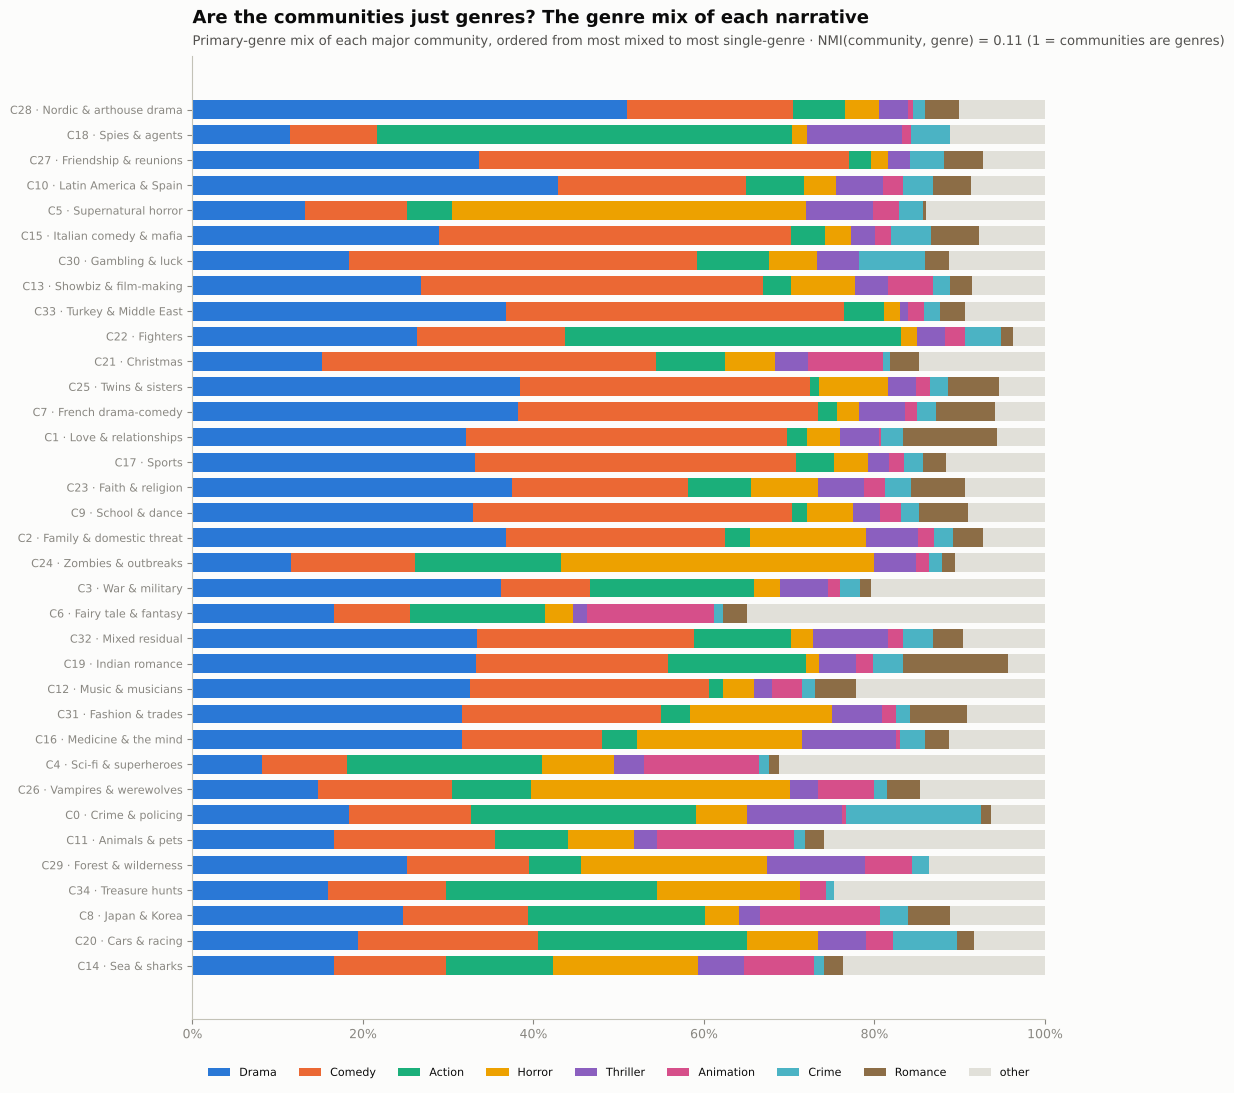

  ✓ 04_narrative_communities/figures/fig_03_genre_mix.png + table


In [30]:
@figure
def b4_fig03_genre_mix():
    g = nodes[nodes["is_major"]].dropna(subset=["primary_genre"])
    top = g["primary_genre"].value_counts().head(8).index
    ct = pd.crosstab(g["community_id"], g["primary_genre"].where(g["primary_genre"].isin(top), "other"), normalize="index")
    ct = ct[list(top) + (["other"] if "other" in ct else [])]
    ct = ct.loc[ct.max(axis=1).sort_values().index]
    nmi = pd.read_csv(FILES["genre_nmi"]).set_index("comparison")["NMI"] if FILES["genre_nmi"].exists() else None
    fig, ax = plt.subplots(figsize=(11, 0.3 * len(ct) + 2))
    left = np.zeros(len(ct))
    colors = CATEGORICAL[:len(top)] + [GRID]
    for col, c in zip(ct.columns, colors):
        ax.barh(range(len(ct)), ct[col], left=left, color=c, height=0.75, label=col)
        left += ct[col].values
    ax.set_yticks(range(len(ct)), [CLAB[c] for c in ct.index], fontsize=8)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=9, fontsize=8)
    ax.set_title("Are the communities just genres? The genre mix of each narrative")
    nm = f"NMI(community, genre) = {nmi.iloc[0]:.2f} (1 = communities are genres)" if nmi is not None else ""
    subtitle(ax, f"Primary-genre mix of each major community, ordered from most mixed to most single-genre · {nm}")
    save(fig, ct.reset_index().round(4), "fig_03_genre_mix")

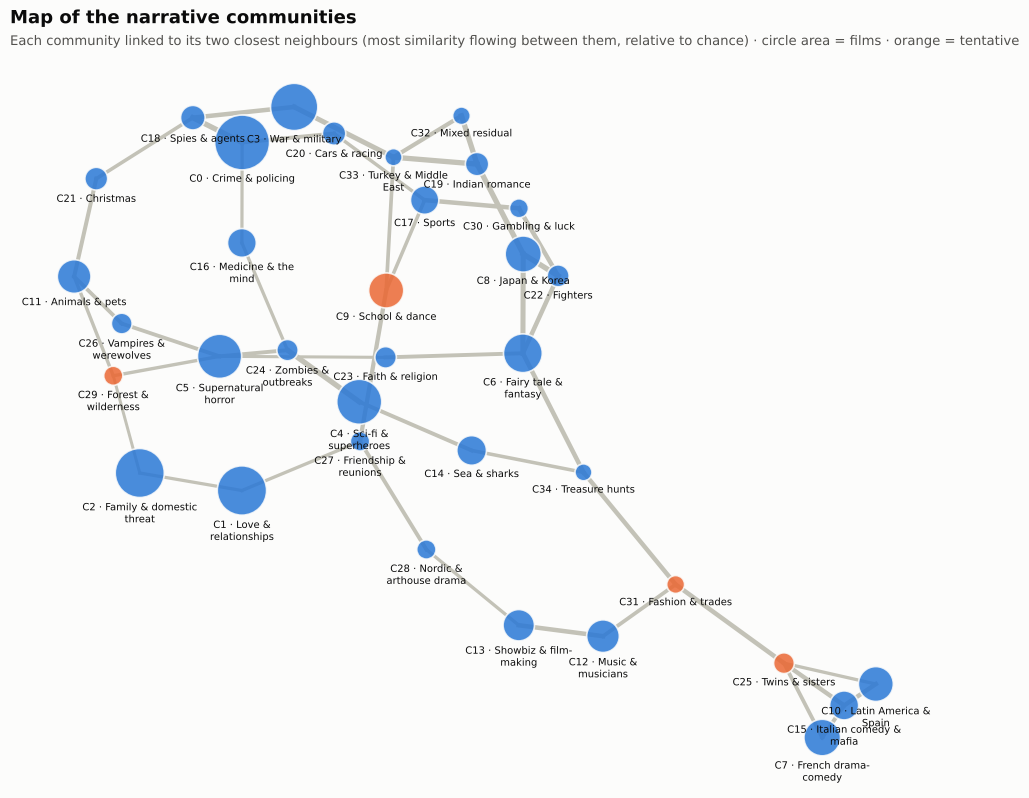

  ✓ 04_narrative_communities/figures/fig_04_community_map.png + table


In [31]:
@figure
def b4_fig04_community_map():
    pair = pd.concat([e[["ca", "cb", "w"]], e[["cb", "ca", "w"]].set_axis(["ca", "cb", "w"], axis=1)])
    W = pair[pair["ca"] != pair["cb"]].groupby(["ca", "cb"])["w"].sum().unstack(fill_value=0.0)
    out = W.sum(axis=1)
    lift = W / np.outer(out, out) * out.sum()
    lift = lift.loc[lift.index.isin(MAJOR), lift.columns.isin(MAJOR)]
    links = (lift.stack().rename("lift").reset_index().set_axis(["c", "nb", "lift"], axis=1)
             .sort_values(["c", "lift"], ascending=[True, False]).groupby("c").head(2))
    H = nx.Graph()
    H.add_nodes_from(MAJOR)
    for r in links.itertuples():
        H.add_edge(int(r.c), int(r.nb), lift=float(r.lift))
    pos = nx.spring_layout(H, weight="lift", seed=CFG["random_state"], k=1.7 / np.sqrt(len(MAJOR)), iterations=400)
    fig, ax = plt.subplots(figsize=(12, 9.5))
    for u, v, d in H.edges(data=True):
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=AXIS, linewidth=0.6 + 0.8 * min(d["lift"], 4), zorder=1)
    xy = np.array([pos[c] for c in MAJOR])
    area = 60 + 1500 * sizes[MAJOR].values / sizes[MAJOR].max()
    ax.scatter(xy[:, 0], xy[:, 1], s=area, color=[SERIES[1] if c in TENTATIVE else SERIES[0] for c in MAJOR],
               alpha=0.85, edgecolor=SURFACE, linewidth=1.2, zorder=2)
    for c, (x_, y_), a_ in zip(MAJOR, xy, area):
        ax.annotate(wrap(CLAB[c], 22), (x_, y_), xytext=(0, -np.sqrt(a_) / 2 - 3), textcoords="offset points",
                    ha="center", va="top", fontsize=7.2, color=INK, zorder=3)
    no_axes(ax)
    ax.margins(0.08)
    ax.set_title("Map of the narrative communities")
    subtitle(ax, "Each community linked to its two closest neighbours (most similarity flowing between them, relative to chance) "
                 "· circle area = films · orange = tentative")
    save(fig, links.round(4), "fig_04_community_map")

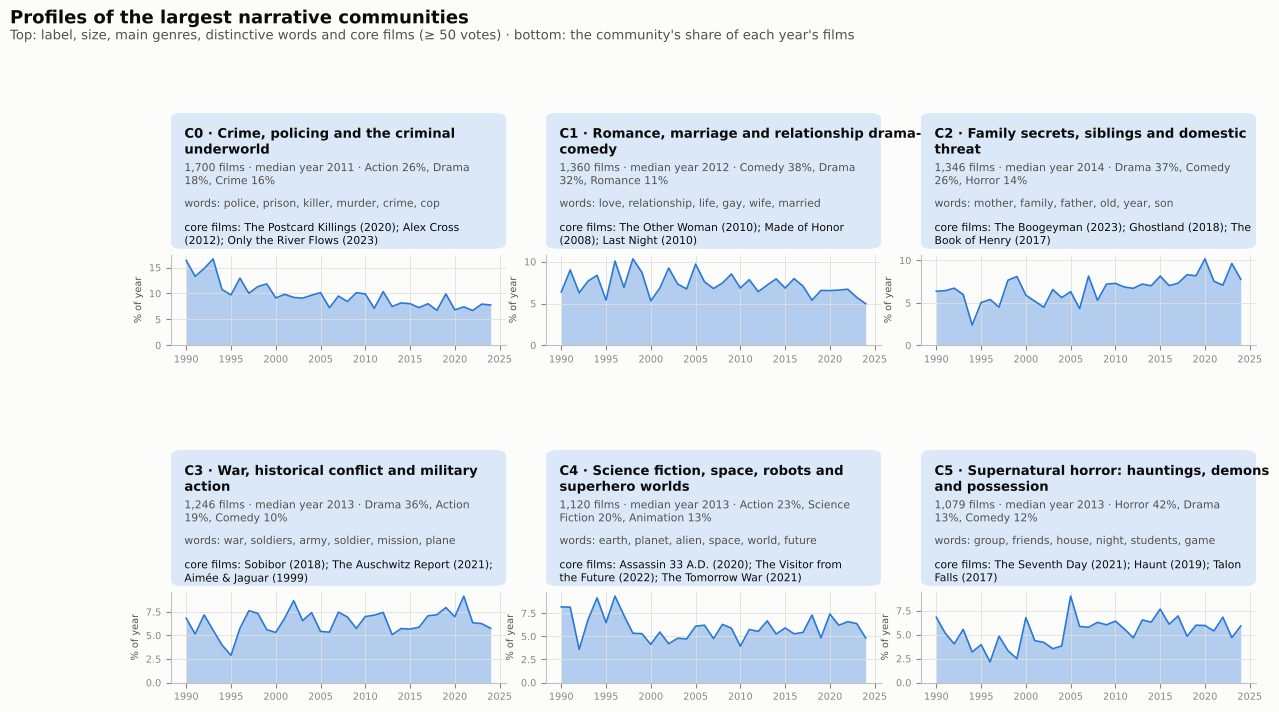

  ✓ 04_narrative_communities/figures/fig_05_profile_cards.png + table


In [32]:
@figure
def b4_fig05_profile_cards():
    show_c = MAJOR[:CFG["profile_communities"]]
    ncols = 3
    nrows = int(np.ceil(len(show_c) / ncols))
    fig = plt.figure(figsize=(14, 3.3 * nrows + 0.8))
    outer = fig.add_gridspec(nrows, ncols, hspace=0.45, wspace=0.12)
    years = np.arange(int(nodes["release_year"].min()), int(nodes["release_year"].max()) + 1)
    rows = []
    for k, c in enumerate(show_c):
        sub = outer[k // ncols, k % ncols].subgridspec(2, 1, height_ratios=[1.5, 1], hspace=0.05)
        axt, axs = fig.add_subplot(sub[0]), fig.add_subplot(sub[1])
        no_axes(axt)
        d = nodes[nodes["community_id"] == c]
        genres = d["primary_genre"].value_counts(normalize=True).head(3)
        ex = (d[d["visible"]].sort_values("within_community_strength" if "within_community_strength" in d else "weighted_degree",
                                            ascending=False).drop_duplicates("title_family").head(3)["label"])
        terms = ", ".join(str(lab.loc[c].get("key_terms", "")).split("; ")[:6]) if "key_terms" in lab else ""
        axt.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.04", transform=axt.transAxes,
                                     facecolor=PALE[1] if c in TENTATIVE else PALE[0], edgecolor="none"))
        axt.text(0.04, 0.9, wrap(f"C{c} · {FULL[c]}", 46), transform=axt.transAxes, fontsize=9.5, fontweight="bold", va="top")
        axt.text(0.04, 0.64, wrap(f"{len(d):,} films · median year {int(d['release_year'].median())} · "
                                + ", ".join(f"{g} {s:.0%}" for g, s in genres.items()), 54),
                 transform=axt.transAxes, fontsize=7.8, color=INK_2, va="top")
        axt.text(0.04, 0.37, wrap("words: " + short(terms, 60), 56), transform=axt.transAxes, fontsize=7.8, color=INK_2, va="top")
        axt.text(0.04, 0.2, wrap("core films: " + "; ".join(ex), 56), transform=axt.transAxes, fontsize=7.8, color=INK, va="top")
        share = d["release_year"].value_counts().reindex(years, fill_value=0) / nodes["release_year"].value_counts().reindex(years, fill_value=1)
        axs.fill_between(years, share * 100, color=SERIES[1] if c in TENTATIVE else SERIES[0], alpha=0.35, linewidth=0)
        axs.plot(years, share * 100, color=SERIES[1] if c in TENTATIVE else SERIES[0], linewidth=1.2)
        axs.set_ylim(0, None); axs.tick_params(labelsize=7)
        axs.set_ylabel("% of year", fontsize=7)
        rows.append({"community_id": c, "label": FULL[c], "n_films": len(d), "core_films": "; ".join(ex), "key_terms": terms})
    fig.text(0.01, 0.995, "Profiles of the largest narrative communities", fontsize=13, fontweight="bold", va="bottom")
    fig.text(0.01, 0.975, "Top: label, size, main genres, distinctive words and core films (≥ 50 votes) · bottom: the community's share of each year's films",
             fontsize=9.5, color=INK_2, va="bottom")
    save(fig, pd.DataFrame(rows), "fig_05_profile_cards")

In [33]:
nmi_v = pd.read_csv(FILES["genre_nmi"]).iloc[0]["NMI"] if FILES["genre_nmi"].exists() else np.nan

In [34]:
write_note([
    "Brick 4 — Narrative communities",
    "",
    f"{nodes['community_id'].nunique()} communities (consensus Louvain, modularity {float(net_manifest.get('modularity', np.nan)):.2f}); "
    f"the {len(MAJOR)} major ones (≥ 100 films) hold {sizes[MAJOR].sum() / len(nodes):.0%} of films and carry reviewed labels. "
    f"{len(TENTATIVE)} are tentative (robustness < {CFG['tentative_robustness']}).",
    f"Largest: {FULL[MAJOR[0]]} ({sizes[MAJOR[0]]:,} films), {FULL[MAJOR[1]]} ({sizes[MAJOR[1]]:,}), {FULL[MAJOR[2]]} ({sizes[MAJOR[2]]:,}).",
    (f"Communities are not genres: normalised mutual information between community and primary genre is {nmi_v:.2f}." if pd.notna(nmi_v) else ""),
    "Interpretation: 'narrative community' = a region of plot space whose films have similar overviews; tentative communities "
    "should be described as broad neighbourhoods, not sharply bounded story types.",
    "Main text: fig_01_major_communities, fig_02_community_index_table, fig_04_community_map. Appendix: fig_03_genre_mix, fig_05_profile_cards.",
])

Brick 4 — Narrative communities

105 communities (consensus Louvain, modularity 0.65); the 35 major ones (≥ 100 films) hold 93% of films and carry reviewed labels. 4 are tentative (robustness < 0.5).
Largest: Crime, policing and the criminal underworld (1,700 films), Romance, marriage and relationship drama-comedy (1,360), Family secrets, siblings and domestic threat (1,346).
Communities are not genres: normalised mutual information between community and primary genre is 0.11.
Interpretation: 'narrative community' = a region of plot space whose films have similar overviews; tentative communities should be described as broad neighbourhoods, not sharply bounded story types.
Main text: fig_01_major_communities, fig_02_community_index_table, fig_04_community_map. Appendix: fig_03_genre_mix, fig_05_profile_cards.

  ✓ 04_narrative_communities/text/brick_04_notes.txt


---
## Brick 5 — Central story positions
**Reader question:** which films are typical of their narrative, and what does centrality mean here?

A central film has many strong plot neighbours. Its story is told often, so centrality reads as **typicality**, not importance. Representative films are ranked by **within-community strength**: similarity to films of the *same* community, with core films first.

In [35]:
start_brick(5)
if E is not None:
    rows_ = nodes["tmdb_id"].map(row_of).values
    typ = np.empty(len(nodes))
    for s in range(0, len(nodes), 2000):                           # mean similarity to the K most similar plots
        S = E[rows_[s:s + 2000]] @ E.T
        S[np.arange(S.shape[0]), rows_[s:s + 2000]] = -np.inf
        typ[s:s + 2000] = np.partition(S, -K, axis=1)[:, -K:].mean(axis=1)
    nodes["typicality"] = typ
elif mt is not None and "novelty" in mt:
    nodes["typicality"] = 1 - nodes["tmdb_id"].map(mt.drop_duplicates("tmdb_id").set_index("tmdb_id")["novelty"])
STRENGTH = "within_community_strength" if "within_community_strength" in nodes else "weighted_degree"
nodes["_central_key"] = (nodes["is_core"].astype(int) * 1e6 if "is_core" in nodes else 0) + nodes[STRENGTH]

Brick 5 → outputs/thesis_bricks/05_central_story_positions


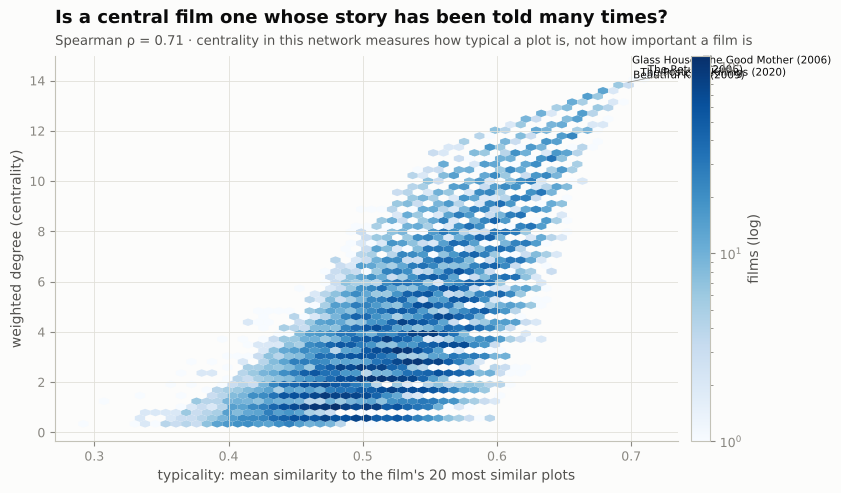

  ✓ 05_central_story_positions/figures/fig_01_centrality_is_typicality.png + table


In [36]:
@figure
def b5_fig01_centrality_is_typicality():
    if "typicality" not in nodes:
        raise Missing("embeddings or novelty not available")
    fig, ax = plt.subplots(figsize=(8.5, 5))
    hb = ax.hexbin(nodes["typicality"], nodes["weighted_degree"], gridsize=55, cmap="Blues", mincnt=1, bins="log", linewidths=0)
    fig.colorbar(hb, ax=ax, fraction=0.035, pad=0.02, label="films (log)")
    ex = nodes[nodes["visible"]].sort_values("weighted_degree", ascending=False).drop_duplicates("title_family").head(4)
    label_points(ax, ex["typicality"], ex["weighted_degree"], ex["label"])
    rho = spearman(nodes["typicality"], nodes["weighted_degree"])
    ax.set_xlabel(f"typicality: mean similarity to the film's {K} most similar plots")
    ax.set_ylabel("weighted degree (centrality)")
    ax.set_title("Is a central film one whose story has been told many times?")
    subtitle(ax, f"Spearman ρ = {rho:.2f} · centrality in this network measures how typical a plot is, not how important a film is")
    save(fig, nodes[["tmdb_id", "title", "typicality", "weighted_degree"]].round(4), "fig_01_centrality_is_typicality")

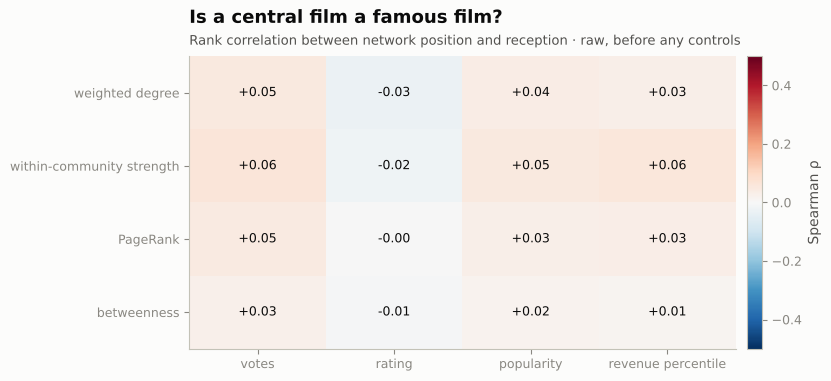

  ✓ 05_central_story_positions/figures/fig_02_centrality_vs_fame.png + table


In [37]:
@figure
def b5_fig02_centrality_vs_fame():
    cent = [(c, n) for c, n in [("weighted_degree", "weighted degree"), (STRENGTH, "within-community strength"),
                                ("pagerank", "PageRank"), (BETW, "betweenness")] if c in nodes]
    cent = list(dict(cent).items())
    rec = [(c, n) for c, n in [("vote_count", "votes"), ("vote_average", "rating"), ("popularity", "popularity")] if c in nodes]
    if mt is not None and "revenue_percentile_year" in mt:
        nodes["revenue_percentile_year"] = nodes["tmdb_id"].map(mt.drop_duplicates("tmdb_id").set_index("tmdb_id")["revenue_percentile_year"])
        rec.append(("revenue_percentile_year", "revenue percentile"))
    M = pd.DataFrame([[spearman(nodes[a], nodes[b]) for b, _ in rec] for a, _ in cent],
                     index=[n for _, n in cent], columns=[n for _, n in rec])
    fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(cent) + 1.8))
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks(range(M.shape[0]), M.index)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:+.2f}", ha="center", va="center", fontsize=9, color="white" if abs(M.values[i, j]) > 0.3 else INK)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Spearman ρ")
    ax.set_title("Is a central film a famous film?")
    subtitle(ax, "Rank correlation between network position and reception · raw, before any controls")
    save(fig, M.reset_index().rename(columns={"index": "centrality"}).round(4), "fig_02_centrality_vs_fame")

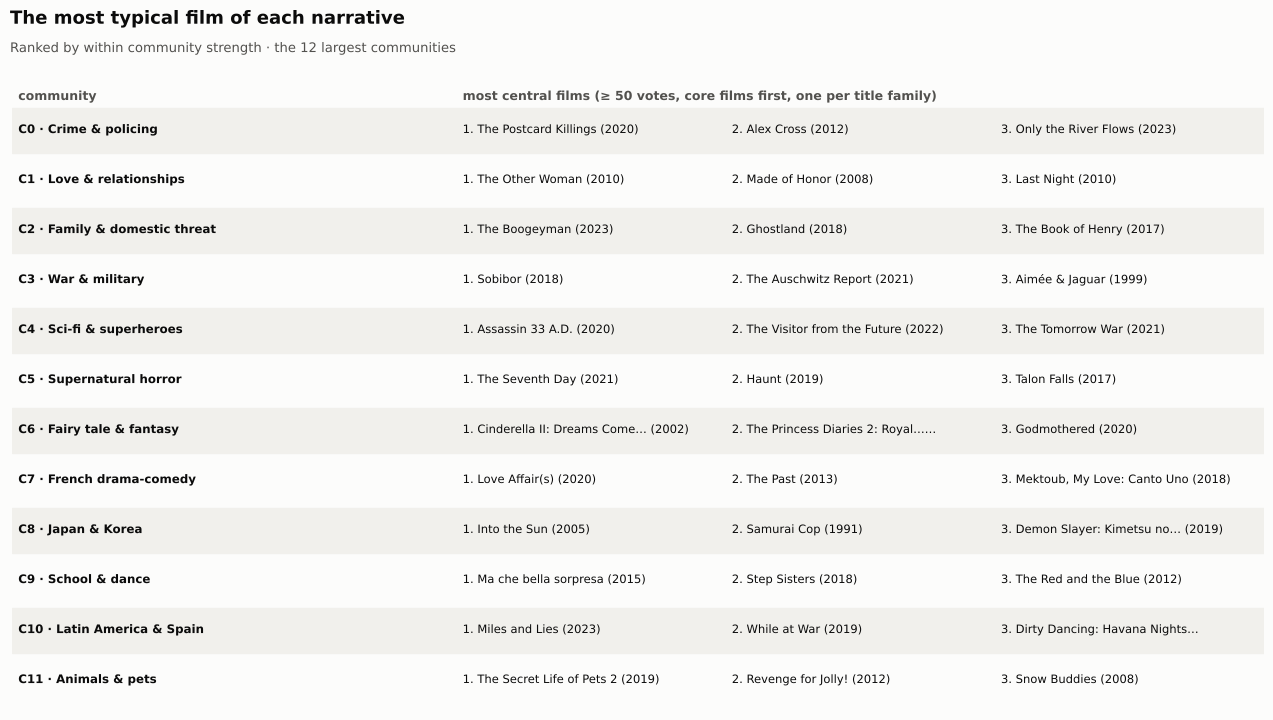

  ✓ 05_central_story_positions/figures/fig_03_central_films_table.png + table


In [38]:
@figure
def b5_fig03_central_films_table():
    n = CFG["table_communities"]
    t = (nodes[nodes["visible"] & nodes["community_id"].isin(MAJOR[:n])]
         .sort_values(["community_id", "_central_key"], ascending=[True, False])
         .drop_duplicates(["community_id", "title_family"]).groupby("community_id").head(3))
    t["rank"] = t.groupby("community_id").cumcount() + 1
    fig, ax = plt.subplots(figsize=(13, 0.5 * n + 1.2))
    no_axes(ax)
    ax.set_xlim(0, 1); ax.set_ylim(n - 0.4, -1)
    for x, h in [(0.005, "community"), (0.36, "most central films (≥ 50 votes, core films first, one per title family)")]:
        ax.text(x, -0.6, h, fontsize=9, fontweight="bold", color=INK_2)
    for i, c in enumerate(MAJOR[:n]):
        if i % 2 == 0:
            ax.add_patch(plt.Rectangle((0, i - 0.45), 1, 0.9, color="#f1f0ec", zorder=0))
        ax.text(0.005, i, short(CLAB[c], 52), va="center", fontsize=8.5, fontweight="bold")
        films = t[t["community_id"] == c]
        for j, r in enumerate(films.itertuples()):
            ax.text(0.36 + 0.215 * j, i, f"{r.rank}. {short(r.label, 34)}", va="center", fontsize=8.3)
    fig_header(fig, "The most typical film of each narrative", f"Ranked by {STRENGTH.replace('_', ' ')} · the {n} largest communities", band_in=0.75)
    save(fig, t[["community_id", "rank", "title", "release_year", "vote_count", STRENGTH] + (["is_core"] if "is_core" in t else [])], "fig_03_central_films_table")

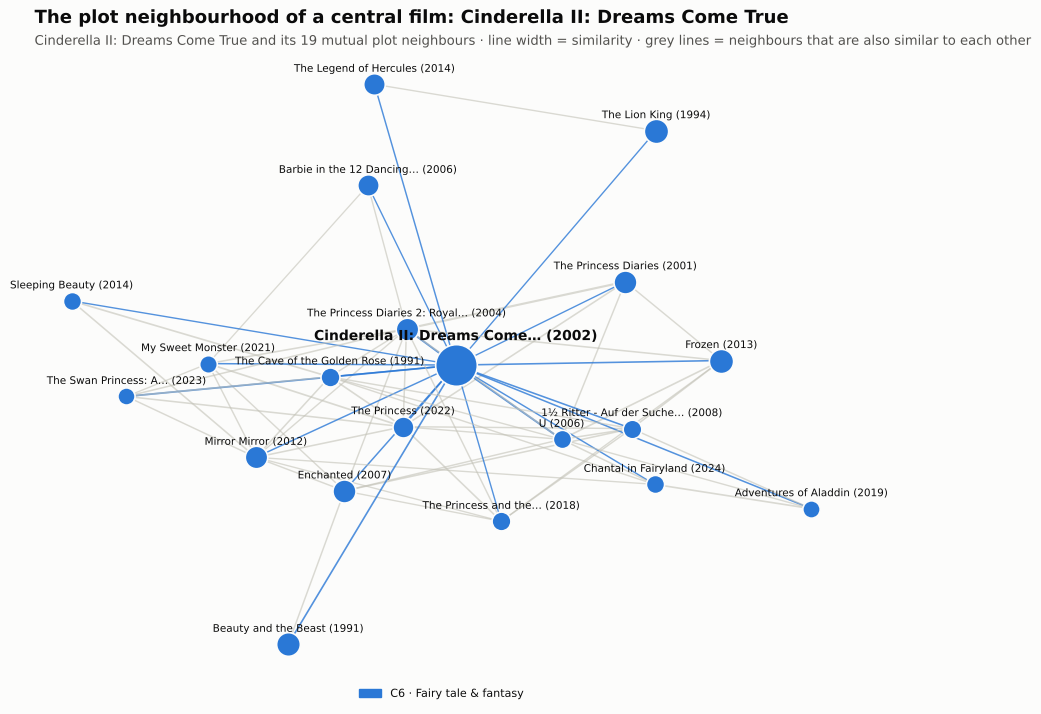

  ✓ 05_central_story_positions/figures/fig_04_ego_network.png + table


In [39]:
@figure
def b5_fig04_ego_network():
    c = anchor["community_id"] if anchor["community_id"] in MAJOR else MAJOR[0]
    focus = (nodes[nodes["visible"] & (nodes["community_id"] == c)].sort_values("_central_key", ascending=False).iloc[0])
    nb = list(G.neighbors(focus["node_id"]))
    H = G.subgraph([focus["node_id"]] + nb).copy()
    pos = nx.spring_layout(H, weight="weight", seed=CFG["random_state"], k=0.9)
    comms = sorted({comm_of[v] for v in H}, key=lambda x: -sizes[x])
    cmap = {cc: CATEGORICAL[k % len(CATEGORICAL)] for k, cc in enumerate(comms)}
    fig, ax = plt.subplots(figsize=(10.5, 8))
    for u, v, d in H.edges(data=True):
        hub = focus["node_id"] in (u, v)
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=SERIES[0] if hub else AXIS,
                linewidth=0.5 + 3 * max(d["weight"] - 0.4, 0), alpha=0.8 if hub else 0.6, zorder=1)
    for v in H:
        r = node_ix.loc[v]
        s = 900 if v == focus["node_id"] else 60 + 25 * np.log1p(r["vote_count"])
        ax.scatter(*pos[v], s=s, color=cmap[comm_of[v]], edgecolor=SURFACE, linewidth=1.2, zorder=2)
        ax.annotate(r["label"], pos[v], xytext=(0, 9 if v != focus["node_id"] else 18), textcoords="offset points",
                    ha="center", fontsize=7.5 if v != focus["node_id"] else 10, fontweight="bold" if v == focus["node_id"] else None, zorder=3)
    ax.legend(handles=[Patch(color=cmap[cc], label=short(clab(cc), 45)) for cc in comms[:6]], loc="upper center",
              bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=8)
    no_axes(ax)
    ax.set_title(f"The plot neighbourhood of a central film: {focus['title']}")
    subtitle(ax, f"{focus['title']} and its {len(nb)} mutual plot neighbours · line width = similarity · grey lines = neighbours that are also similar to each other")
    t = pd.DataFrame([{"node_id": v, "title": node_ix.loc[v, "title"], "community_id": comm_of[v],
                       "similarity_to_focus": G[focus["node_id"]][v]["weight"] if v != focus["node_id"] else 1.0} for v in H])
    save(fig, t.round(4), "fig_04_ego_network")

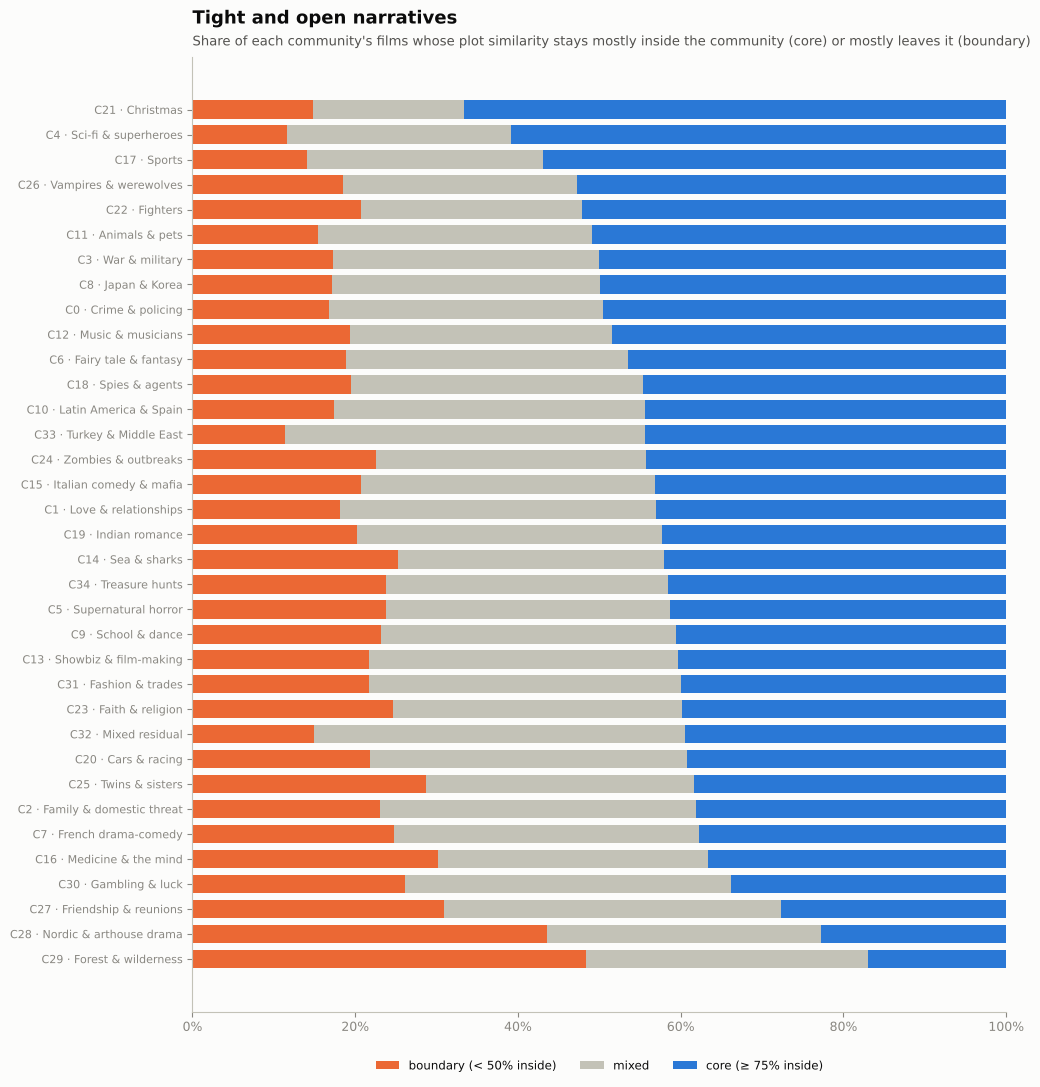

  ✓ 05_central_story_positions/figures/fig_05_core_boundary.png + table


In [40]:
@figure
def b5_fig05_core_boundary():
    if "external_share" not in nodes:
        raise Missing("node_positions_nb04.csv not found")
    d = nodes[nodes["is_major"]].assign(internal=1 - nodes["external_share"])
    d["position"] = pd.cut(d["internal"], [-0.01, 0.5, CFG["core_internal_share"], 1.0],
                           labels=["boundary (< 50% inside)", "mixed", f"core (≥ {CFG['core_internal_share']:.0%} inside)"])
    t = pd.crosstab(d["community_id"], d["position"], normalize="index")
    t = t.loc[t.iloc[:, -1].sort_values().index]
    fig, ax = plt.subplots(figsize=(10.5, 0.3 * len(t) + 1.9))
    left = np.zeros(len(t))
    for col, c in zip(t.columns, [SERIES[1], AXIS, SERIES[0]]):
        ax.barh(range(len(t)), t[col], left=left, color=c, height=0.75, label=col)
        left += t[col].values
    ax.set_yticks(range(len(t)), [CLAB[c] for c in t.index], fontsize=8)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=3, fontsize=8.5)
    ax.set_title("Tight and open narratives")
    subtitle(ax, "Share of each community's films whose plot similarity stays mostly inside the community (core) or mostly leaves it (boundary)")
    save(fig, t.reset_index().round(4), "fig_05_core_boundary")

In [41]:
top_c = nodes[nodes["visible"]].sort_values("weighted_degree", ascending=False).drop_duplicates("title_family").head(5)["label"].tolist()

In [42]:
write_note([
    "Brick 5 — Central story positions",
    "",
    "Centrality here is typicality: a central film has many strong mutual plot neighbours, i.e. its kind of story is told often."
    + (f" Weighted degree and mean similarity to the {K} nearest plots correlate at Spearman ρ = "
       f"{spearman(nodes['typicality'], nodes['weighted_degree']):.2f}." if "typicality" in nodes else ""),
    ("Centrality and fame are different: " if abs(spearman(nodes["weighted_degree"], nodes["vote_count"])) < 0.2 else "Centrality and fame: ")
    + f"ρ(weighted degree, votes) = {spearman(nodes['weighted_degree'], nodes['vote_count']):.2f}, "
    f"ρ(weighted degree, rating) = {spearman(nodes['weighted_degree'], nodes['vote_average']):.2f}.",
    "Most central well-known films (≥ 50 votes, one per title family): " + "; ".join(top_c) + ".",
    f"Representative films per community are ranked by {STRENGTH.replace('_', ' ')}, core films first, so the films used to "
    "describe a community actually belong to it.",
    "Main text: fig_01_centrality_is_typicality, fig_03_central_films_table, fig_04_ego_network. Appendix: fig_02, fig_05.",
])

Brick 5 — Central story positions

Centrality here is typicality: a central film has many strong mutual plot neighbours, i.e. its kind of story is told often. Weighted degree and mean similarity to the 20 nearest plots correlate at Spearman ρ = 0.71.
Centrality and fame are different: ρ(weighted degree, votes) = 0.05, ρ(weighted degree, rating) = -0.03.
Most central well-known films (≥ 50 votes, one per title family): The Return (2006); The Postcard Killings (2020); Beautiful Kate (2009); Glass House: The Good Mother (2006); All That Glitters (2010).
Representative films per community are ranked by within community strength, core films first, so the films used to describe a community actually belong to it.
Main text: fig_01_centrality_is_typicality, fig_03_central_films_table, fig_04_ego_network. Appendix: fig_02, fig_05.

  ✓ 05_central_story_positions/text/brick_05_notes.txt


---
## Brick 6 — Bridging positions
**Reader question:** which films sit between narratives, and which narratives touch?

Two measures are crossed. **Exact betweenness**: how often a film lies on shortest paths between other films. **Participation**: how evenly a film's own neighbours are spread over communities (Guimerà & Amaral, 2005). A **broker** scores high on both. A **connector** carries many paths but links into one other area. A **hybrid** has neighbours spread across communities without carrying many paths.

In [43]:
start_brick(6)
if "participation_coefficient" in nodes:
    b_cut = nodes[BETW].quantile(1 - CFG["bridge_top_share"])
    hiB, hiP = nodes[BETW] >= b_cut, nodes["participation_coefficient"] >= CFG["bridge_participation"]
    nodes["position_type"] = np.select([hiB & hiP, hiB & ~hiP, ~hiB & hiP], ["broker", "connector", "hybrid"], "embedded")
TYPE_COL = {"broker": SERIES[1], "connector": SERIES[0], "hybrid": SERIES[2], "embedded": AXIS}

Brick 6 → outputs/thesis_bricks/06_bridging_story_positions


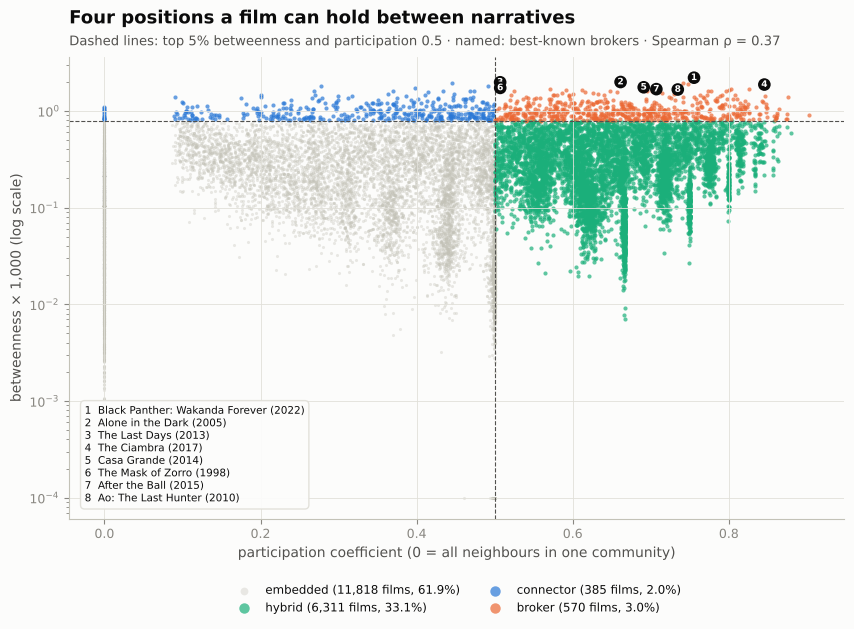

  ✓ 06_bridging_story_positions/figures/fig_01_bridge_typology.png + table


In [44]:
@figure
def b6_fig01_bridge_typology():
    if "position_type" not in nodes:
        raise Missing("participation coefficient not available")
    fig, ax = plt.subplots(figsize=(10, 6))
    y = nodes[BETW] * 1e3 + 1e-4
    counts_ = nodes["position_type"].value_counts()
    for t_ in ["embedded", "hybrid", "connector", "broker"]:
        m = nodes["position_type"] == t_
        ax.scatter(nodes.loc[m, "participation_coefficient"], y[m], s=5 if t_ == "embedded" else 9, alpha=0.35 if t_ == "embedded" else 0.7,
                   color=TYPE_COL[t_], linewidth=0, label=f"{t_} ({counts_.get(t_, 0):,} films, {counts_.get(t_, 0) / len(nodes):.1%})")
    ax.set_yscale("log")
    ax.axhline(b_cut * 1e3, color=INK_2, linewidth=0.8, linestyle="--")
    ax.axvline(CFG["bridge_participation"], color=INK_2, linewidth=0.8, linestyle="--")
    ex = nodes[nodes["visible"] & (nodes["position_type"] == "broker")].sort_values(BETW, ascending=False).drop_duplicates("title_family").head(8)
    numbered_labels(ax, ex["participation_coefficient"], ex[BETW] * 1e3, ex["label"])
    ax.set_xlabel("participation coefficient (0 = all neighbours in one community)")
    ax.set_ylabel("betweenness × 1,000 (log scale)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, markerscale=2.5, fontsize=8.5)
    ax.set_title("Four positions a film can hold between narratives")
    subtitle(ax, f"Dashed lines: top {CFG['bridge_top_share']:.0%} betweenness and participation {CFG['bridge_participation']} · "
                 f"named: best-known brokers · Spearman ρ = {spearman(nodes['participation_coefficient'], nodes[BETW]):.2f}")
    save(fig, nodes[["tmdb_id", "title", "community_id", BETW, "participation_coefficient", "position_type"]], "fig_01_bridge_typology")

In [45]:
@figure
def b6_fig02_community_contact_matrix():
    from scipy.cluster.hierarchy import linkage, leaves_list
    pair = pd.concat([e[["ca", "cb", "w"]], e[["cb", "ca", "w"]].set_axis(["ca", "cb", "w"], axis=1)])
    pair = pair[(pair["ca"] != pair["cb"]) & pair["ca"].isin(MAJOR) & pair["cb"].isin(MAJOR)]
    W = pair.groupby(["ca", "cb"])["w"].sum().unstack(fill_value=0.0).reindex(index=MAJOR, columns=MAJOR, fill_value=0.0)
    out = W.sum(axis=1)
    L = W / np.outer(out, out) * out.sum()
    LL = np.log2(L.clip(lower=0.125, upper=8).where(L > 0, 0.125))
    np.fill_diagonal(LL.values, 3)
    order = leaves_list(linkage(LL.values, "average"))
    LL = LL.iloc[order, order]
    np.fill_diagonal(LL.values, np.nan)
    fig, ax = plt.subplots(figsize=(11.5, 10))
    im = ax.imshow(LL.values, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_xticks(range(len(LL)), [f"C{c}" for c in LL.columns], rotation=90, fontsize=7)
    ax.set_yticks(range(len(LL)), [short(CLAB[c], 40) for c in LL.index], fontsize=7)
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cb.set_ticks([-3, -2, -1, 0, 1, 2, 3]); cb.set_ticklabels(["⅛", "¼", "½", "1", "2", "4", "8"])
    cb.set_label("similarity between the two communities ÷ chance")
    ax.set_title("Which narratives touch each other")
    subtitle(ax, "Plot similarity flowing between each pair of major communities relative to chance · ordered so that neighbouring narratives sit together")
    save(fig, L.reset_index().rename(columns={"ca": "community_id"}).round(4), "fig_02_community_contact_matrix")

  ✗ b6_fig02_community_contact_matrix skipped: ValueError('underlying array is read-only')


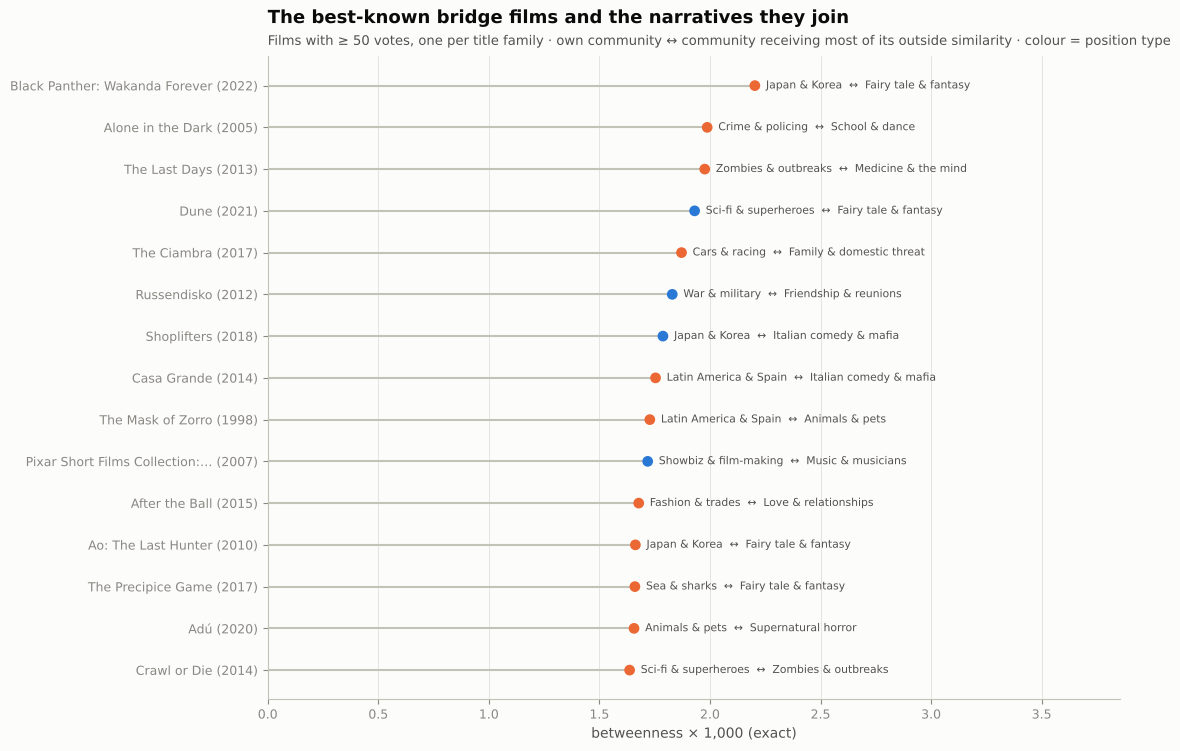

  ✓ 06_bridging_story_positions/figures/fig_03_top_bridges.png + table


In [46]:
@figure
def b6_fig03_top_bridges():
    if "main_external_community" not in nodes:
        raise Missing("node_positions_nb04.csv not found")
    tb = (nodes[nodes["visible"]].dropna(subset=["main_external_community"]).sort_values(BETW, ascending=False)
          .drop_duplicates("title_family").head(15).iloc[::-1])
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(tb) + 1.6))
    y = np.arange(len(tb))
    ax.hlines(y, 0, tb[BETW] * 1e3, color=AXIS, linewidth=1.5)
    ax.scatter(tb[BETW] * 1e3, y, s=45, color=[TYPE_COL.get(t_, SERIES[0]) for t_ in tb.get("position_type", ["connector"] * len(tb))], zorder=3)
    for yi, r in zip(y, tb.itertuples()):
        ax.annotate(f"{short(SHORT.get(r.community_id, f'C{r.community_id}'), 26)}  ↔  "
                    f"{short(SHORT.get(int(r.main_external_community), f'C{int(r.main_external_community)}'), 26)}",
                    (getattr(r, BETW) * 1e3, yi), xytext=(8, 0), textcoords="offset points", va="center", fontsize=7.8, color=INK_2)
    ax.set_yticks(y, tb["label"])
    ax.set_xlim(0, tb[BETW].max() * 1e3 * 1.75)
    ax.set_xlabel("betweenness × 1,000 (exact)")
    ax.grid(axis="y", visible=False)
    ax.set_title("The best-known bridge films and the narratives they join")
    subtitle(ax, "Films with ≥ 50 votes, one per title family · own community ↔ community receiving most of its outside similarity · colour = position type")
    save(fig, tb[["title", "release_year", "community_id", "main_external_community", BETW] +
                 [c for c in ["participation_coefficient", "position_type"] if c in tb]], "fig_03_top_bridges")

In [47]:
def path_endpoints():
    if CFG["path_titles"]:
        a_, b_ = find_film([CFG["path_titles"][0]]), find_film([CFG["path_titles"][1]])
        if a_ is not None and b_ is not None:
            return a_, b_
    big = MAJOR[:10]
    pair = pd.concat([e[["ca", "cb", "w"]], e[["cb", "ca", "w"]].set_axis(["ca", "cb", "w"], axis=1)])
    W = pair[pair["ca"].isin(big) & pair["cb"].isin(big) & (pair["ca"] != pair["cb"])].groupby(["ca", "cb"])["w"].sum()
    out = W.groupby(level=0).sum()
    lift = (W / (out.reindex(W.index.get_level_values(0)).values * out.reindex(W.index.get_level_values(1)).values) * out.sum())
    full_ = pd.Series(0.0, index=pd.MultiIndex.from_product([big, big]))
    full_.update(lift)
    full_ = full_[full_.index.get_level_values(0) < full_.index.get_level_values(1)]
    ca_, cb_ = full_.idxmin()                                  # the two large narratives furthest apart
    pick = lambda c: nodes[(nodes["community_id"] == c)].sort_values("vote_count", ascending=False).iloc[0]
    return pick(ca_), pick(cb_)

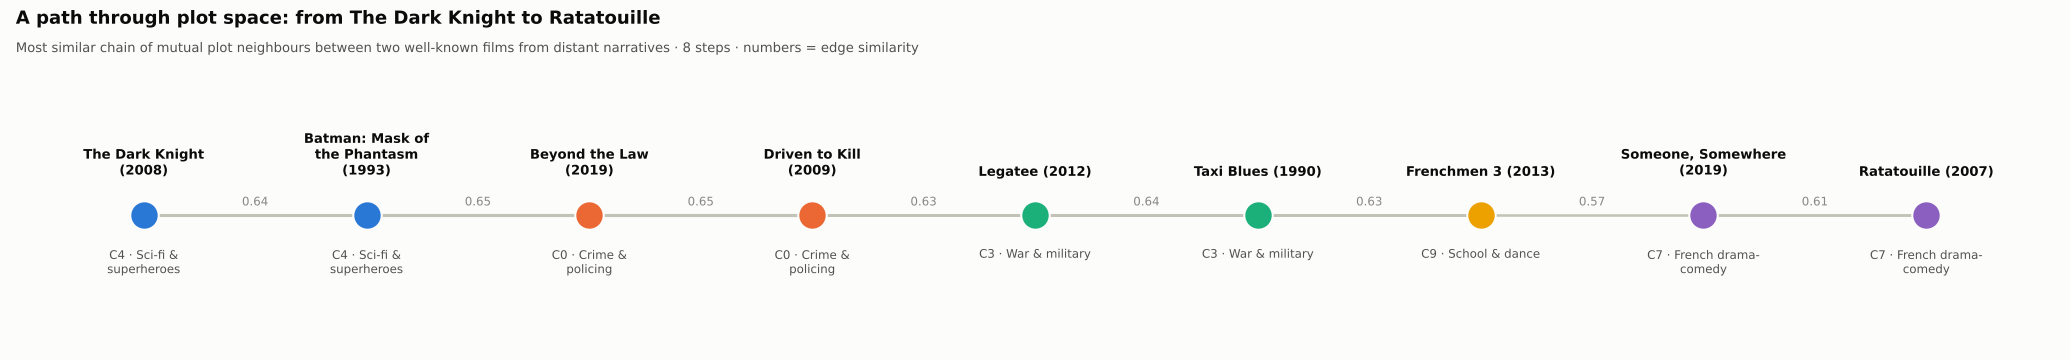

  ✓ 06_bridging_story_positions/figures/fig_04_bridge_pathway.png + table


In [48]:
@figure
def b6_fig04_bridge_pathway():
    a_, b_ = path_endpoints()
    H = G.copy()
    for u, v, d in H.edges(data=True):
        d["dist"] = 1 - d["weight"]
    path = nx.shortest_path(H, a_["node_id"], b_["node_id"], weight="dist")
    t = pd.DataFrame({"step": range(len(path)), "node_id": path})
    t["title"] = t["node_id"].map(node_ix["label"]); t["community_id"] = t["node_id"].map(comm_of)
    t["similarity_to_next"] = [G[u][v]["weight"] for u, v in zip(path[:-1], path[1:])] + [np.nan]
    t["betweenness"] = t["node_id"].map(node_ix[BETW])
    n = len(t)
    fig, ax = plt.subplots(figsize=(min(2.2 * n + 1, 22), 3.6))
    no_axes(ax)
    ax.set_xlim(-0.6, n - 0.4); ax.set_ylim(-1.2, 1.2)
    comms = list(dict.fromkeys(t["community_id"]))
    cmap = {c: CATEGORICAL[k % len(CATEGORICAL)] for k, c in enumerate(comms)}
    for i, r in t.iterrows():
        ax.scatter(i, 0, s=420, color=cmap[r["community_id"]], zorder=3, edgecolor=SURFACE, linewidth=1.5)
        ax.text(i, 0.32, wrap(r["title"], 18), ha="center", va="bottom", fontsize=9.5, fontweight="bold")
        ax.text(i, -0.3, wrap(short(clab(r["community_id"]), 40), 20), ha="center", va="top", fontsize=8.5, color=INK_2)
        if i < n - 1:
            ax.plot([i, i + 1], [0, 0], color=AXIS, linewidth=1 + 5 * max(r["similarity_to_next"] - 0.4, 0), zorder=1)
            ax.text(i + 0.5, 0.06, f"{r['similarity_to_next']:.2f}", ha="center", va="bottom", fontsize=8.5, color=MUTED)
    fig_header(fig, f"A path through plot space: from {a_['title']} to {b_['title']}",
               f"Most similar chain of mutual plot neighbours between two well-known films from distant narratives · {n - 1} steps · numbers = edge similarity",
               band_in=0.75)
    save(fig, t.round(4), "fig_04_bridge_pathway")

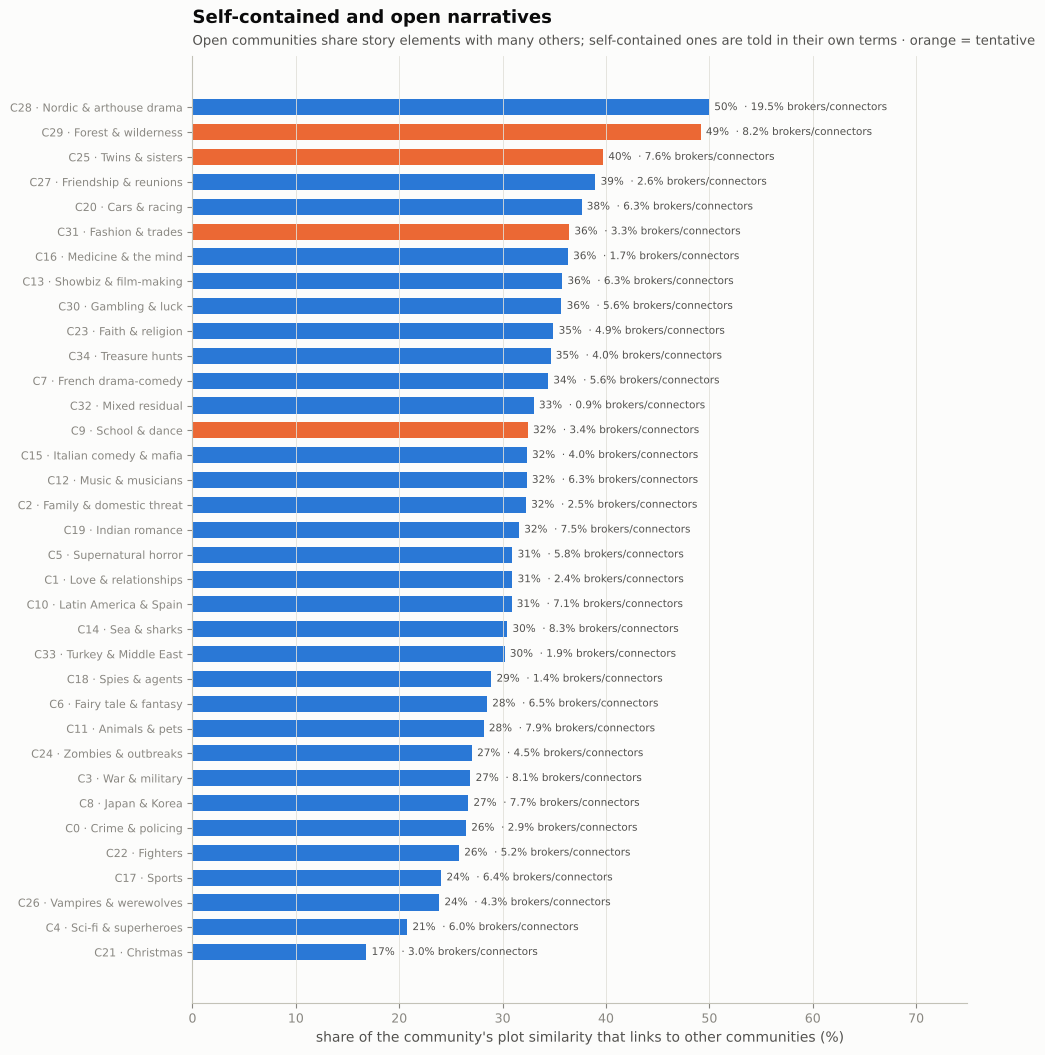

  ✓ 06_bridging_story_positions/figures/fig_05_open_narratives.png + table


In [49]:
@figure
def b6_fig05_open_narratives():
    pair = e[e["ca"].isin(MAJOR) | e["cb"].isin(MAJOR)]
    both = pd.concat([pair[["ca", "w", "internal"]].rename(columns={"ca": "c"}), pair[["cb", "w", "internal"]].rename(columns={"cb": "c"})])
    both = both[both["c"].isin(MAJOR)]
    t = both.groupby("c").apply(lambda d: d.loc[~d["internal"], "w"].sum() / d["w"].sum()).rename("external_share").to_frame()
    if "position_type" in nodes:
        t["broker_share"] = nodes[nodes["is_major"]].groupby("community_id")["position_type"].apply(lambda s: s.isin(["broker", "connector"]).mean())
    t = t.sort_values("external_share")
    fig, ax = plt.subplots(figsize=(10, 0.3 * len(t) + 1.8))
    yy = np.arange(len(t))
    ax.barh(yy, t["external_share"] * 100, color=[SERIES[1] if c in TENTATIVE else SERIES[0] for c in t.index], height=0.65)
    for yi, (c, r) in zip(yy, t.iterrows()):
        extra_ = f"  · {r['broker_share']:.1%} brokers/connectors" if "broker_share" in t else ""
        ax.text(r["external_share"] * 100 + 0.5, yi, f"{r['external_share']:.0%}{extra_}", va="center", fontsize=7.5, color=INK_2)
    ax.set_yticks(yy, [CLAB[c] for c in t.index], fontsize=8)
    ax.set_xlim(0, t["external_share"].max() * 100 * 1.5)
    ax.set_xlabel("share of the community's plot similarity that links to other communities (%)")
    ax.grid(axis="y", visible=False)
    ax.set_title("Self-contained and open narratives")
    subtitle(ax, "Open communities share story elements with many others; self-contained ones are told in their own terms · orange = tentative")
    save(fig, t.reset_index().rename(columns={"c": "community_id"}).round(4), "fig_05_open_narratives")

In [50]:
bt = (nodes[nodes["visible"]].sort_values(BETW, ascending=False).drop_duplicates("title_family").head(5)["label"].tolist())

In [51]:
write_note([
    "Brick 6 — Bridging positions",
    "",
    "Best-known bridge films (exact betweenness, ≥ 50 votes, one per title family): " + "; ".join(bt) + ".",
    (f"Position types (top {CFG['bridge_top_share']:.0%} betweenness × participation ≥ {CFG['bridge_participation']}): "
     + ", ".join(f"{k} {v:,} ({v / len(nodes):.1%})" for k, v in nodes["position_type"].value_counts().items()) + "."
     if "position_type" in nodes else ""),
    (f"Participation and betweenness correlate only at ρ = {spearman(nodes['participation_coefficient'], nodes[BETW]):.2f}: "
     "carrying many shortest paths and having a mixed neighbourhood are different kinds of bridging." if "participation_coefficient" in nodes else ""),
    "Interpretation: a bridge film 'connects narratives' through its plot description; it is a structural position, not a judgement "
    "of originality.",
    "Main text: fig_01_bridge_typology, fig_03_top_bridges, fig_04_bridge_pathway. Appendix: fig_02_community_contact_matrix, fig_05_open_narratives.",
])

Brick 6 — Bridging positions

Best-known bridge films (exact betweenness, ≥ 50 votes, one per title family): Black Panther: Wakanda Forever (2022); Alone in the Dark (2005); The Last Days (2013); Dune (2021); The Ciambra (2017).
Position types (top 5% betweenness × participation ≥ 0.5): embedded 11,818 (61.9%), hybrid 6,311 (33.1%), broker 570 (3.0%), connector 385 (2.0%).
Participation and betweenness correlate only at ρ = 0.37: carrying many shortest paths and having a mixed neighbourhood are different kinds of bridging.
Interpretation: a bridge film 'connects narratives' through its plot description; it is a structural position, not a judgement of originality.
Main text: fig_01_bridge_typology, fig_03_top_bridges, fig_04_bridge_pathway. Appendix: fig_02_community_contact_matrix, fig_05_open_narratives.

  ✓ 06_bridging_story_positions/text/brick_06_notes.txt


---
## Brick 7 — Success dimensions
**Reader question:** is success one thing or several?

Four outcomes, as in Notebooks 05–06: **revenue percentile** within the year's market, **return on investment** (revenue ÷ budget, when both are at least $10k), **rating** and **popularity** (attention). If they correlated perfectly, one model would do. They do not, so Brick 8 reads the plot-network results for each one.

In [52]:
start_brick(7)
OUT7 = {"revenue_percentile_year": "revenue percentile", "log_roi": "log ROI", "vote_average": "rating",
        "log_popularity": "log popularity", "log_votes": "log votes"}
if mt is not None:
    s7 = mt.copy()
    mm = CFG["min_money_for_roi"]
    ok = (s7["revenue_clean"] >= mm) & (s7["budget_clean"] >= mm)
    s7["log_roi"] = np.where(ok, np.log(s7["revenue_clean"].where(ok) / s7["budget_clean"].where(ok)), np.nan)
    if "log_popularity" not in s7:
        s7["log_popularity"] = np.log1p(s7["popularity"].where(s7["popularity"] > 0))
    s7["log_votes"] = np.log1p(s7["vote_count"])
    s7["title_family"] = title_family(s7["title"])
    s7["label"] = s7["title"].astype(str).map(lambda t: short(t, 28)) + " (" + s7["release_year"].astype("Int64").astype(str) + ")"
    OUT7 = {k: v for k, v in OUT7.items() if k in s7}
def need_model_table():
    if mt is None:
        raise Missing("modeling_table_success_star_power.csv not found (Notebook 05)")

Brick 7 → outputs/thesis_bricks/07_success_dimensions


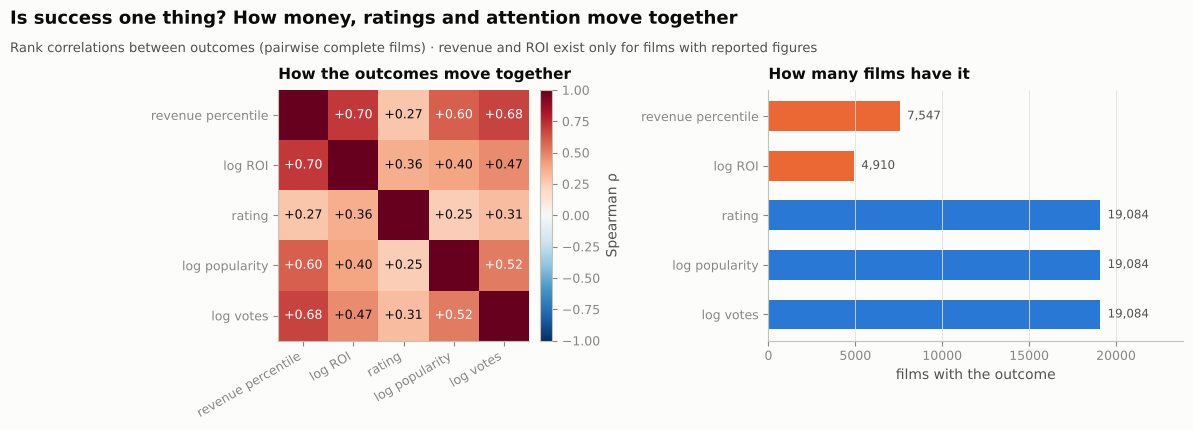

  ✓ 07_success_dimensions/figures/fig_01_outcome_correlations.png + table
  ✓ 07_success_dimensions/tables/fig_01_pair_counts.csv


In [53]:
@figure
def b7_fig01_outcome_correlations():
    need_model_table()
    C = s7[list(OUT7)].corr(method="spearman", min_periods=100)
    N = pd.DataFrame([[int(s7[[a, b]].dropna().shape[0]) for b in OUT7] for a in OUT7], index=list(OUT7), columns=list(OUT7))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(C)), [OUT7[c] for c in C], rotation=30, ha="right"); ax.set_yticks(range(len(C)), [OUT7[c] for c in C])
    ax.grid(False)
    for i in range(len(C)):
        for j in range(len(C)):
            if i != j:
                ax.text(j, i, f"{C.values[i, j]:+.2f}", ha="center", va="center", fontsize=9, color="white" if abs(C.values[i, j]) > 0.5 else INK)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Spearman ρ")
    ax.set_title("How the outcomes move together", fontsize=11, pad=8)
    ax = axes[1]
    n_ = s7[list(OUT7)].notna().sum()
    ax.barh(range(len(n_)), n_.values, color=[SERIES[1] if v < 0.9 * len(s7) else SERIES[0] for v in n_.values], height=0.6)
    for i, v in enumerate(n_.values):
        ax.text(v, i, f"  {v:,}", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(range(len(n_)), [OUT7[c] for c in n_.index])
    ax.invert_yaxis()
    ax.set_xlim(0, len(s7) * 1.25)
    ax.set_xlabel("films with the outcome")
    ax.grid(axis="y", visible=False)
    ax.set_title("How many films have it", fontsize=11, pad=8)
    fig_header(fig, "Is success one thing? How money, ratings and attention move together",
               "Rank correlations between outcomes (pairwise complete films) · revenue and ROI exist only for films with reported figures")
    save(fig, C.reset_index().rename(columns={"index": "outcome"}).round(4), "fig_01_outcome_correlations")
    save_tab(N.reset_index().rename(columns={"index": "outcome"}), "fig_01_pair_counts.csv")

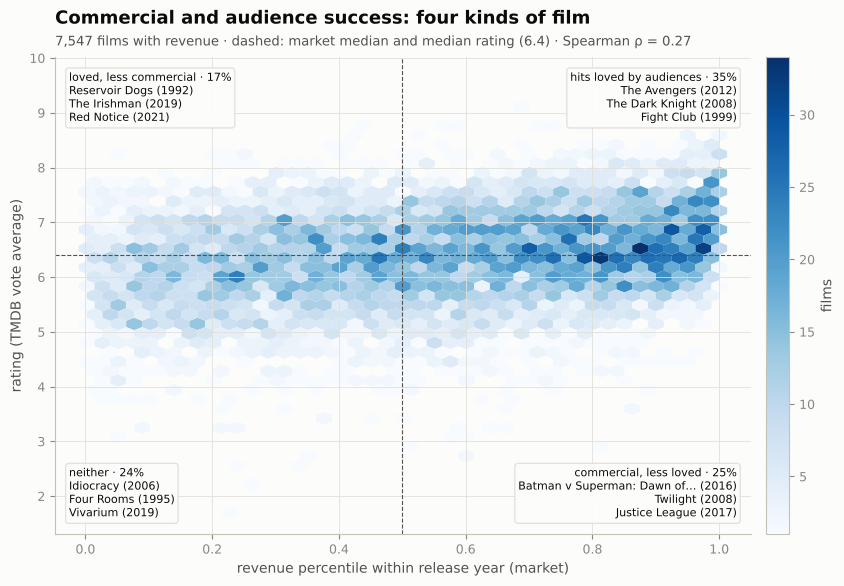

  ✓ 07_success_dimensions/figures/fig_02_success_map.png + table


In [54]:
@figure
def b7_fig02_success_map():
    need_model_table()
    d = s7.dropna(subset=["revenue_percentile_year", "vote_average"])
    r_cut, v_cut = 0.5, d["vote_average"].median()
    fig, ax = plt.subplots(figsize=(9.5, 6.2))
    hb = ax.hexbin(d["revenue_percentile_year"], d["vote_average"], gridsize=40, cmap="Blues", mincnt=1, linewidths=0)
    fig.colorbar(hb, ax=ax, fraction=0.035, pad=0.02, label="films")
    ax.axvline(r_cut, color=INK_2, linewidth=0.8, linestyle="--"); ax.axhline(v_cut, color=INK_2, linewidth=0.8, linestyle="--")
    quad = np.select([(d["revenue_percentile_year"] >= r_cut) & (d["vote_average"] >= v_cut),
                      (d["revenue_percentile_year"] >= r_cut), (d["vote_average"] >= v_cut)],
                     ["hits loved by audiences", "commercial, less loved", "loved, less commercial"], "neither")
    d = d.assign(quadrant=quad)
    share = d["quadrant"].value_counts(normalize=True)
    pos_ = {"hits loved by audiences": (0.98, 0.97, "right", "top"), "commercial, less loved": (0.98, 0.03, "right", "bottom"),
            "loved, less commercial": (0.02, 0.97, "left", "top"), "neither": (0.02, 0.03, "left", "bottom")}
    rows = []
    for q, (x_, y_, ha, va) in pos_.items():
        ex = d[d["quadrant"] == q].sort_values("vote_count", ascending=False).drop_duplicates("title_family").head(3)
        ax.text(x_, y_, f"{q} · {share.get(q, 0):.0%}\n" + "\n".join(ex["label"]), transform=ax.transAxes, ha=ha, va=va,
                fontsize=8, color=INK, bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec=GRID, alpha=0.92))
        rows.append({"quadrant": q, "share": share.get(q, 0), "examples": "; ".join(ex["label"])})
    ax.set_xlabel("revenue percentile within release year (market)")
    ax.set_ylabel("rating (TMDB vote average)")
    ax.set_title("Commercial and audience success: four kinds of film")
    subtitle(ax, f"{len(d):,} films with revenue · dashed: market median and median rating ({v_cut:.1f}) · "
                 f"Spearman ρ = {spearman(d['revenue_percentile_year'], d['vote_average']):.2f}")
    save(fig, pd.DataFrame(rows).round(4), "fig_02_success_map")

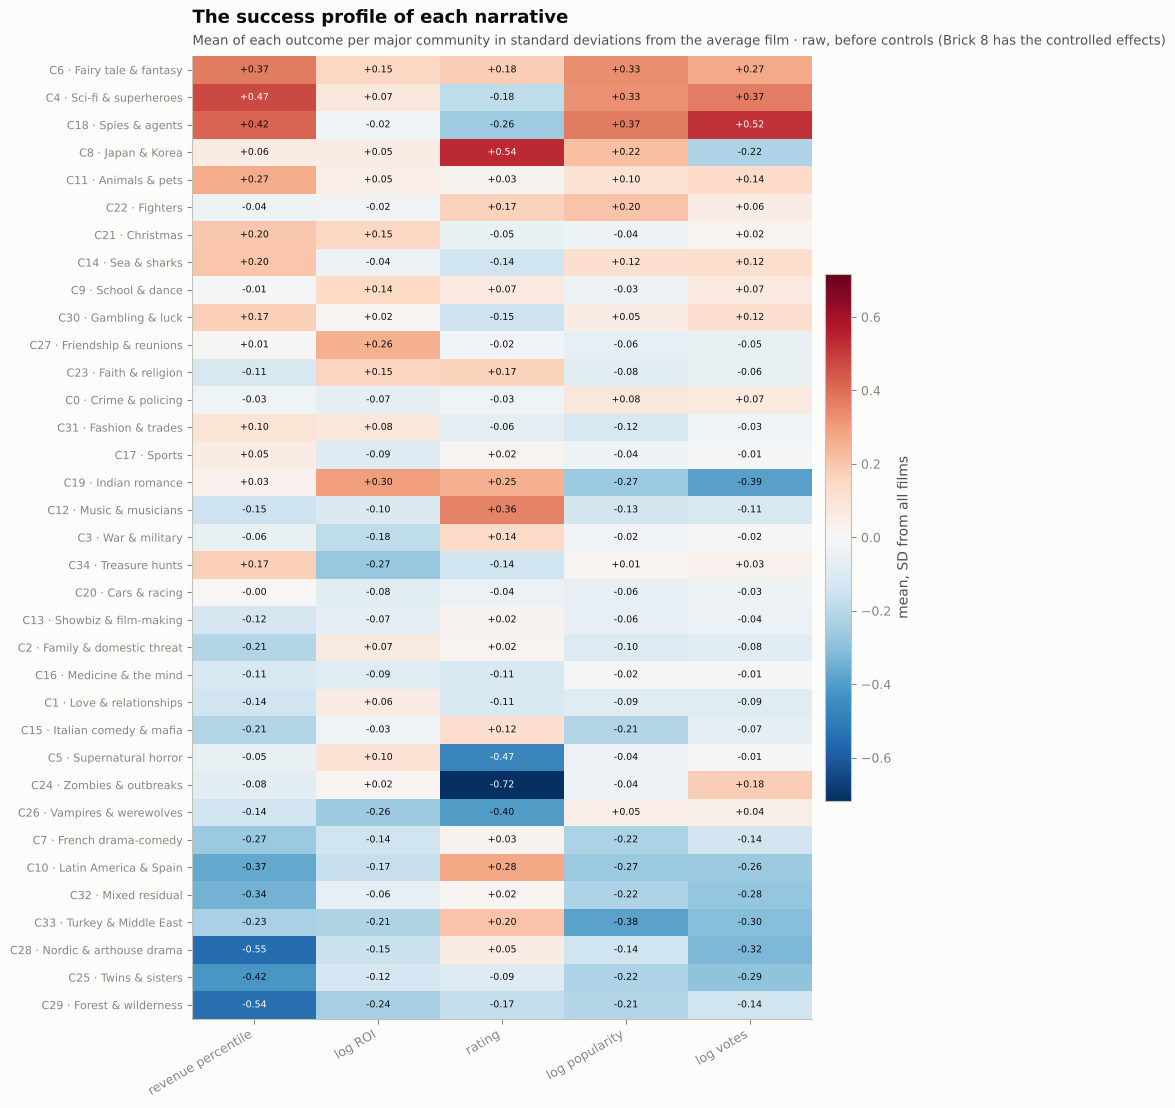

  ✓ 07_success_dimensions/figures/fig_03_community_success_profile.png + table


In [55]:
@figure
def b7_fig03_community_success_profile():
    need_model_table()
    d = s7[s7["community_id"].isin(MAJOR)].copy()
    for c in OUT7:
        d[c] = (d[c] - s7[c].mean()) / s7[c].std()
    t = d.groupby("community_id")[list(OUT7)].mean()
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(t) + 2))
    lim = np.nanmax(np.abs(t.values))
    im = ax.imshow(t.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(t.shape[1]), [OUT7[c] for c in t.columns], rotation=30, ha="right")
    ax.set_yticks(range(len(t)), [CLAB[c] for c in t.index], fontsize=8)
    ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6.8, color="white" if abs(v) > 0.6 * lim else INK)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="mean, SD from all films")
    ax.set_title("The success profile of each narrative")
    subtitle(ax, "Mean of each outcome per major community in standard deviations from the average film · raw, before controls (Brick 8 has the controlled effects)")
    save(fig, t.reset_index().round(4), "fig_03_community_success_profile")

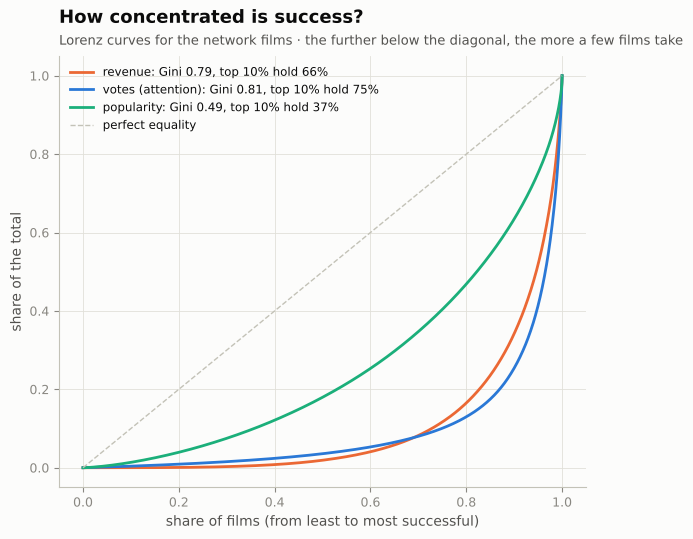

  ✓ 07_success_dimensions/figures/fig_04_concentration.png + table


In [56]:
@figure
def b7_fig04_concentration():
    need_model_table()
    series = {"revenue": s7["revenue_clean"].where(s7["revenue_clean"] > 0), "votes (attention)": s7["vote_count"],
              "popularity": s7["popularity"]}
    fig, ax = plt.subplots(figsize=(6.8, 5.6))
    rows = []
    for (name, s), color in zip(series.items(), [SERIES[1], SERIES[0], SERIES[2]]):
        v = np.sort(s.dropna().values)
        if len(v) < 10:
            continue
        cum = np.cumsum(v) / v.sum()
        x = np.arange(1, len(v) + 1) / len(v)
        gini = 1 - 2 * float(np.sum((cum[1:] + cum[:-1]) / 2 * np.diff(x)))       # trapezoid rule (np.trapz is gone in NumPy 2)
        top10 = 1 - cum[int(0.9 * len(v)) - 1]
        ax.plot(x, cum, color=color, label=f"{name}: Gini {gini:.2f}, top 10% hold {top10:.0%}")
        rows.append({"measure": name, "films": len(v), "gini": gini, "top10_share": top10})
    ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, linestyle="--", label="perfect equality")
    ax.set_xlabel("share of films (from least to most successful)")
    ax.set_ylabel("share of the total")
    ax.legend(loc="upper left", fontsize=8.5)
    ax.set_title("How concentrated is success?")
    subtitle(ax, "Lorenz curves for the network films · the further below the diagonal, the more a few films take")
    save(fig, pd.DataFrame(rows).round(4), "fig_04_concentration")

In [57]:
if mt is not None:
    C7 = s7[list(OUT7)].corr(method="spearman", min_periods=100)
    note7 = [f"ρ(revenue percentile, rating) = {C7.loc['revenue_percentile_year', 'vote_average']:.2f}; "
             f"ρ(revenue percentile, log popularity) = {C7.loc['revenue_percentile_year', 'log_popularity']:.2f}; "
             f"ρ(rating, log popularity) = {C7.loc['vote_average', 'log_popularity']:.2f}"
             + (f"; ρ(log ROI, revenue percentile) = {C7.loc['log_roi', 'revenue_percentile_year']:.2f}." if "log_roi" in C7 else ".")]
else:
    note7 = ["Modelling table not found — run Notebook 05."]

In [58]:
write_note([
    "Brick 7 — Success dimensions",
    "",
    "Outcomes: revenue percentile within the release year's market (all thesis films with revenue), log return on "
    "investment (revenue and budget ≥ $10k), rating (TMDB vote average), log popularity; log votes shown as a second "
    "attention measure.",
    *note7,
    "Interpretation: commercial success, audience evaluation and attention are related but distinct, so the thesis reports the "
    "plot-network results per outcome rather than for one success index.",
    "Main text: fig_01_outcome_correlations, fig_02_success_map. Appendix: fig_03_community_success_profile, fig_04_concentration.",
])

Brick 7 — Success dimensions

Outcomes: revenue percentile within the release year's market (all thesis films with revenue), log return on investment (revenue and budget ≥ $10k), rating (TMDB vote average), log popularity; log votes shown as a second attention measure.
ρ(revenue percentile, rating) = 0.27; ρ(revenue percentile, log popularity) = 0.60; ρ(rating, log popularity) = 0.25; ρ(log ROI, revenue percentile) = 0.70.
Interpretation: commercial success, audience evaluation and attention are related but distinct, so the thesis reports the plot-network results per outcome rather than for one success index.
Main text: fig_01_outcome_correlations, fig_02_success_map. Appendix: fig_03_community_success_profile, fig_04_concentration.

  ✓ 07_success_dimensions/text/brick_07_notes.txt


---
## Brick 8 — Narrative structure and success
**Reader question:** how is a film's place in plot space associated with its success?

This brick redraws the results of Notebooks 05 and 06 together. It does not re-estimate anything. The questions are:
1. How much does plot position add to the usual explanations (year, genre, runtime, language, star power)?
2. Which plot measures carry a signal, for which outcome?
3. Do films with similar plots have similar fates, and does a film's plot help predict the success of films the model has not seen?
4. Which narratives do better after controls, and which are rising?
5. How big are the effects, in units a reader knows (percentile points, % revenue, rating points)?

Correct framing: *plot-network structure is associated with success signals*. Not causal, not a forecasting tool.

In [59]:
start_brick(8)
OUTN = {"log_revenue": "log revenue", "revenue_percentile_year": "revenue percentile", "log_roi": "log ROI",
        "vote_average": "rating", "log_popularity": "log popularity"}
fit = pd.read_csv(FILES["model_fit"]) if FILES["model_fit"].exists() else None

Brick 8 → outputs/thesis_bricks/08_structure_success


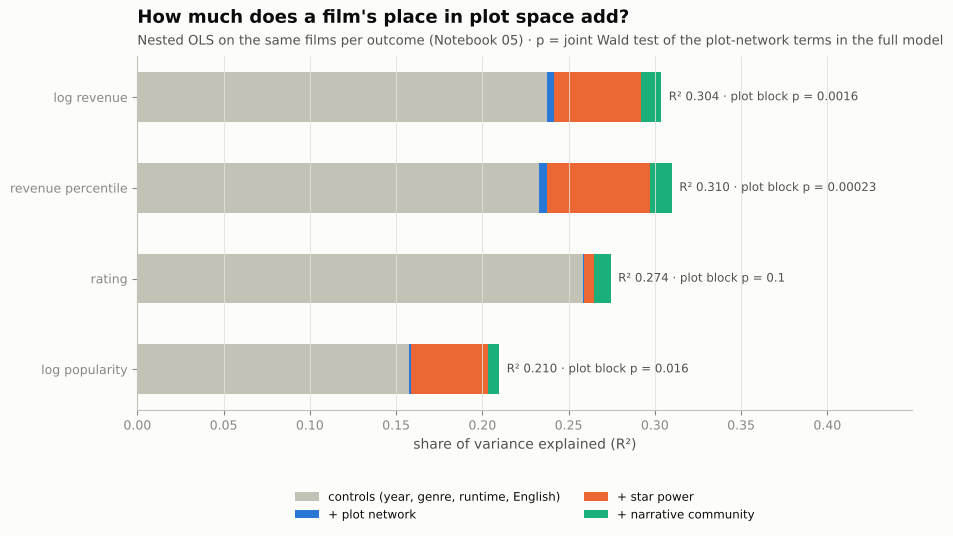

  ✓ 08_structure_success/figures/fig_01_r2_by_block.png + table


In [60]:
@figure
def b8_fig01_r2_by_block():
    need("model_fit")
    specs = ["M1_controls", "M2_add_plot_network", "M3_add_star_power", "M4_add_community"]
    r = fit[fit["model"].isin(specs)].pivot(index="outcome", columns="model", values="r_squared")[specs]
    r = r.loc[[o for o in OUTN if o in r.index]]
    gain = pd.DataFrame({"controls (year, genre, runtime, English)": r["M1_controls"],
                         "+ plot network": r["M2_add_plot_network"] - r["M1_controls"],
                         "+ star power": r["M3_add_star_power"] - r["M2_add_plot_network"],
                         "+ narrative community": r["M4_add_community"] - r["M3_add_star_power"]})
    wald = fit[fit["model"].str.startswith("joint")].set_index("outcome")["wald_p"]
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(gain) + 1.8))
    left = np.zeros(len(gain))
    for col, c in zip(gain.columns, [AXIS, SERIES[0], SERIES[1], SERIES[2]]):
        ax.barh(range(len(gain)), gain[col], left=left, color=c, height=0.55, label=col)
        left += gain[col].values
    for i, (o, tot) in enumerate(zip(gain.index, left)):
        p = wald.get(o, np.nan)
        ax.text(tot, i, f"  R² {tot:.3f} · plot block p = {p:.2g}" if pd.notna(p) else f"  R² {tot:.3f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(range(len(gain)), [OUTN[o] for o in gain.index])
    ax.invert_yaxis()
    ax.set_xlim(0, left.max() * 1.45)
    ax.set_xlabel("share of variance explained (R²)")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
    ax.set_title("How much does a film's place in plot space add?")
    subtitle(ax, "Nested OLS on the same films per outcome (Notebook 05) · p = joint Wald test of the plot-network terms in the full model")
    save(fig, gain.reset_index().round(5), "fig_01_r2_by_block")

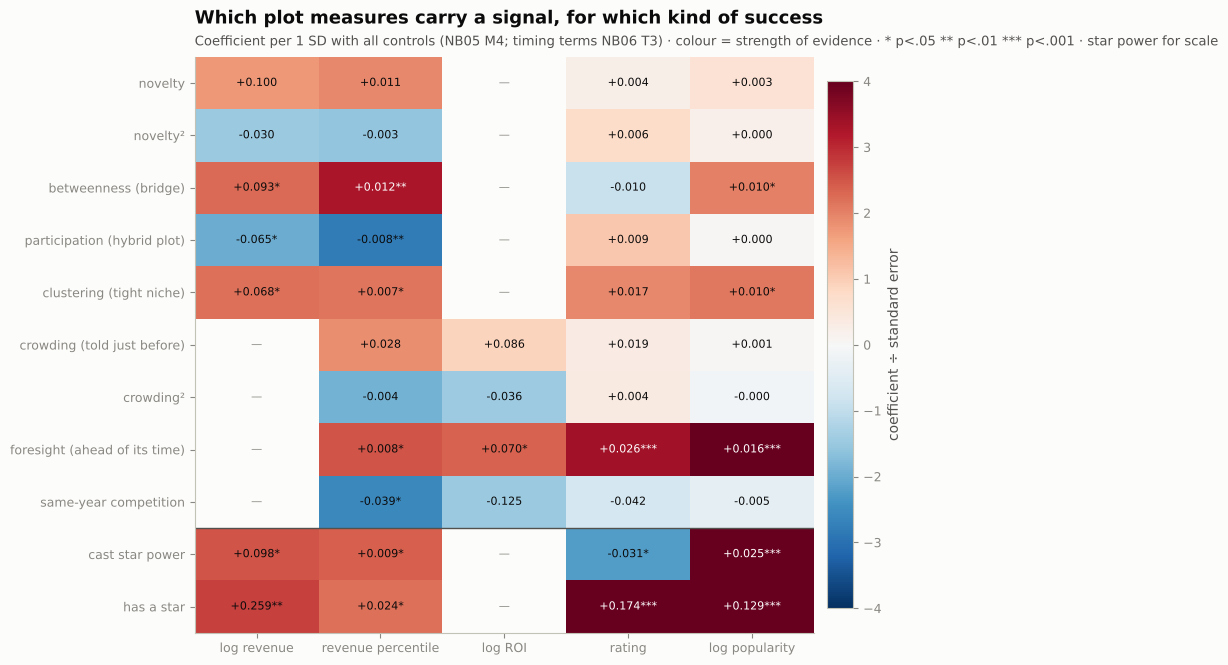

  ✓ 08_structure_success/figures/fig_02_signal_grid.png + table


In [61]:
@figure
def b8_fig02_signal_grid():
    parts = []
    if FILES["coefficients"].exists():
        c5 = pd.read_csv(FILES["coefficients"]).assign(source="NB05 · M4")
        parts.append(c5)
    if FILES["timing"].exists():
        t6 = pd.read_csv(FILES["timing"])
        parts.append(t6[t6["model"] == "T3_plus_competition"].assign(source="NB06 · T3"))
    if not parts:
        raise Missing("Notebook 05/06 coefficient tables not found")
    c = pd.concat(parts, ignore_index=True)
    nice = {"z_novelty": "novelty", "z_novelty_sq": "novelty²", "z_log_betweenness": "betweenness (bridge)",
            "z_participation": "participation (hybrid plot)", "z_clustering": "clustering (tight niche)",
            "crowding_z": "crowding (told just before)", "I(crowding_z ** 2)": "crowding²",
            "foresight_z": "foresight (ahead of its time)", "competition_z": "same-year competition",
            "z_star_index": "cast star power", "has_star": "has a star"}
    c = c[c["term"].isin(nice)]
    c["z"] = c["coef"] / ((c["ci_high"] - c["ci_low"]) / (2 * 1.96))
    rows_ = [t for t in nice if t in c["term"].unique()]
    cols_ = [o for o in OUTN if o in c["outcome"].unique()]
    Z = c.pivot_table(index="term", columns="outcome", values="z", aggfunc="first").reindex(index=rows_, columns=cols_)
    B = c.pivot_table(index="term", columns="outcome", values="coef", aggfunc="first").reindex(index=rows_, columns=cols_)
    P = c.pivot_table(index="term", columns="outcome", values="p_value", aggfunc="first").reindex(index=rows_, columns=cols_)
    fig, ax = plt.subplots(figsize=(8.5, 0.48 * len(rows_) + 2.2))
    im = ax.imshow(Z.clip(-4, 4).values, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
    for i in range(len(rows_)):
        for j in range(len(cols_)):
            if np.isfinite(B.values[i, j]):
                stars = "***" if P.values[i, j] < 0.001 else "**" if P.values[i, j] < 0.01 else "*" if P.values[i, j] < 0.05 else ""
                ax.text(j, i, f"{B.values[i, j]:+.3f}{stars}", ha="center", va="center", fontsize=8,
                        color="white" if abs(Z.values[i, j]) > 3 else INK)
            else:
                ax.text(j, i, "—", ha="center", va="center", fontsize=8, color=MUTED)
    ax.set_xticks(range(len(cols_)), [OUTN[o] for o in cols_])
    ax.set_yticks(range(len(rows_)), [nice[t] for t in rows_])
    n_star = sum(t in ("z_star_index", "has_star") for t in rows_)
    if n_star:
        ax.axhline(len(rows_) - n_star - 0.5, color=INK_2, linewidth=1)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="coefficient ÷ standard error")
    ax.set_title("Which plot measures carry a signal, for which kind of success")
    subtitle(ax, "Coefficient per 1 SD with all controls (NB05 M4; timing terms NB06 T3) · colour = strength of evidence · * p<.05 ** p<.01 *** p<.001 · star power for scale")
    save(fig, c[["source", "outcome", "term", "coef", "ci_low", "ci_high", "p_value", "z"]].round(5), "fig_02_signal_grid")

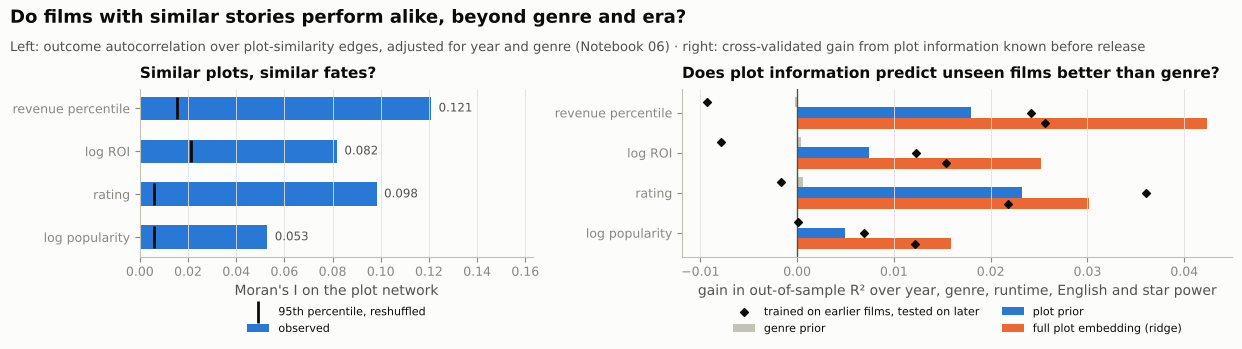

  ✓ 08_structure_success/figures/fig_03_similar_stories_similar_fates.png + table


In [62]:
@figure
def b8_fig03_similar_stories_similar_fates():
    need("moran", "oos")
    mo, cv = pd.read_csv(FILES["moran"]), pd.read_csv(FILES["oos"])
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
    ax = axes[0]
    yy = np.arange(len(mo))[::-1]
    ax.barh(yy, mo["morans_I"], color=SERIES[0], height=0.55, label="observed")
    ax.scatter(mo["null_p95"], yy, marker="|", s=250, color=INK, zorder=3, label="95th percentile, reshuffled")
    for yi, r in zip(yy, mo.itertuples()):
        ax.text(r.morans_I, yi, f"  {r.morans_I:.3f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(yy, [OUTN.get(o, o) for o in mo["outcome"]])
    ax.set_xlim(0, mo["morans_I"].max() * 1.35)
    ax.set_xlabel("Moran's I on the plot network")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=1, fontsize=8)
    ax.set_title("Similar plots, similar fates?", fontsize=11, pad=8)
    ax = axes[1]
    feats = [f for f in ["+ genre prior", "+ plot prior", "+ full plot embedding (ridge)"] if f in cv["features"].unique()]
    outs = [o for o in OUTN if o in cv["outcome"].unique()]
    w = 0.8 / len(feats)
    for j, (f, color) in enumerate(zip(feats, [AXIS, SERIES[0], SERIES[1]])):
        g = cv[cv["features"] == f].set_index("outcome").reindex(outs)
        ax.barh(np.arange(len(outs)) + j * w, g["gain_over_baseline"], height=w, color=color, label=f.replace("+ ", ""))
        ax.scatter(g["forward_gain_over_baseline"], np.arange(len(outs)) + j * w, marker="D", s=16, color=INK, zorder=3,
                   label="trained on earlier films, tested on later" if j == 0 else None)
    ax.set_yticks(np.arange(len(outs)) + w * (len(feats) - 1) / 2, [OUTN[o] for o in outs])
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_xlabel("gain in out-of-sample R² over year, genre, runtime, English and star power")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=8)
    ax.set_title("Does plot information predict unseen films better than genre?", fontsize=11, pad=8)
    fig_header(fig, "Do films with similar stories perform alike, beyond genre and era?",
               "Left: outcome autocorrelation over plot-similarity edges, adjusted for year and genre (Notebook 06) · right: cross-validated gain from plot information known before release")
    save(fig, mo.merge(cv.pivot_table(index="outcome", columns="features", values="gain_over_baseline").reset_index(),
                       on="outcome", how="outer").round(5), "fig_03_similar_stories_similar_fates")

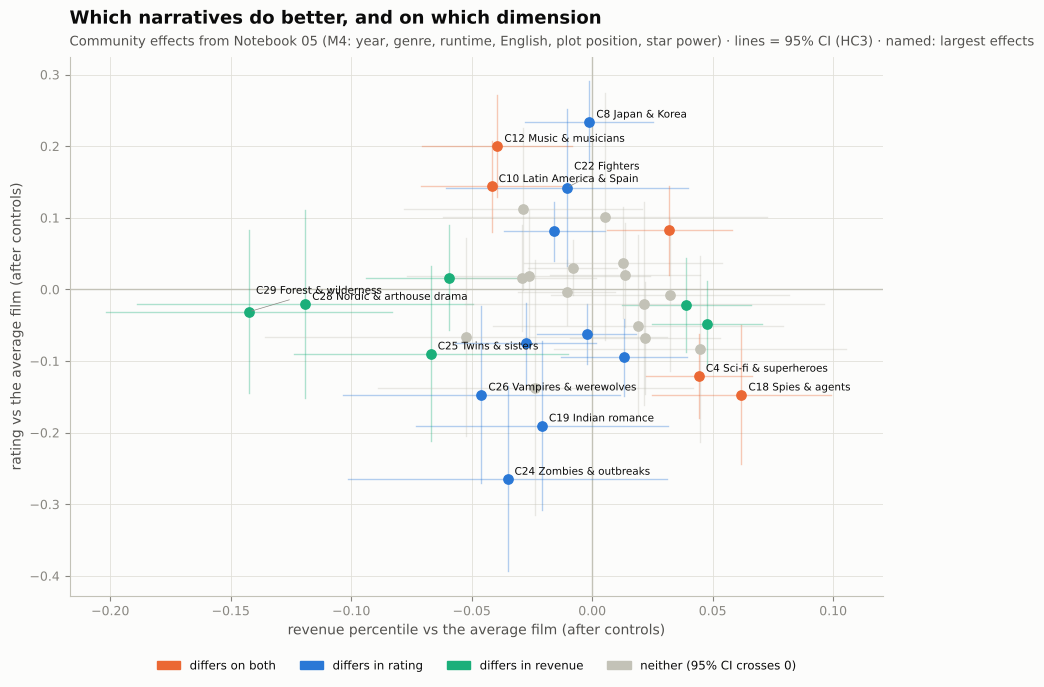

  ✓ 08_structure_success/figures/fig_04_which_narratives_pay.png + table


In [63]:
@figure
def b8_fig04_which_narratives_pay():
    need("community_effects")
    ce = pd.read_csv(FILES["community_effects"])
    ce["label_short"] = ce["community_id"].map(lambda c: SHORT.get(c, f"C{c}"))
    sig_r = (ce["rating_ci_low"] > 0) | (ce["rating_ci_high"] < 0)
    sig_v = (ce["revpct_ci_low"] > 0) | (ce["revpct_ci_high"] < 0)
    fig, ax = plt.subplots(figsize=(10.5, 7))
    ax.axhline(0, color=AXIS, linewidth=1); ax.axvline(0, color=AXIS, linewidth=1)
    for r, sr, sv in zip(ce.itertuples(), sig_r, sig_v):
        color = SERIES[1] if (sr and sv) else SERIES[0] if sr else SERIES[2] if sv else AXIS
        ax.plot([r.revpct_ci_low, r.revpct_ci_high], [r.rating_coef] * 2, color=color, alpha=0.35, linewidth=1)
        ax.plot([r.revpct_coef] * 2, [r.rating_ci_low, r.rating_ci_high], color=color, alpha=0.35, linewidth=1)
        ax.scatter(r.revpct_coef, r.rating_coef, s=45, color=color, zorder=3)
    lab_ = ce[sig_r | sig_v].assign(m=lambda d: d["revpct_coef"].abs() / ce["revpct_coef"].abs().max()
                                    + d["rating_coef"].abs() / ce["rating_coef"].abs().max()).nlargest(12, "m")
    label_points(ax, lab_["revpct_coef"], lab_["rating_coef"],
                 [f"C{c} {short(t, 24)}" for c, t in zip(lab_["community_id"], lab_["label_short"])], step=10)
    ax.set_xlabel("revenue percentile vs the average film (after controls)")
    ax.set_ylabel("rating vs the average film (after controls)")
    ax.legend(handles=[Patch(color=SERIES[1], label="differs on both"), Patch(color=SERIES[0], label="differs in rating"),
                       Patch(color=SERIES[2], label="differs in revenue"), Patch(color=AXIS, label="neither (95% CI crosses 0)")],
              loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=8.5)
    ax.set_title("Which narratives do better, and on which dimension")
    subtitle(ax, "Community effects from Notebook 05 (M4: year, genre, runtime, English, plot position, star power) · lines = 95% CI (HC3) · named: largest effects")
    save(fig, ce.round(5), "fig_04_which_narratives_pay")

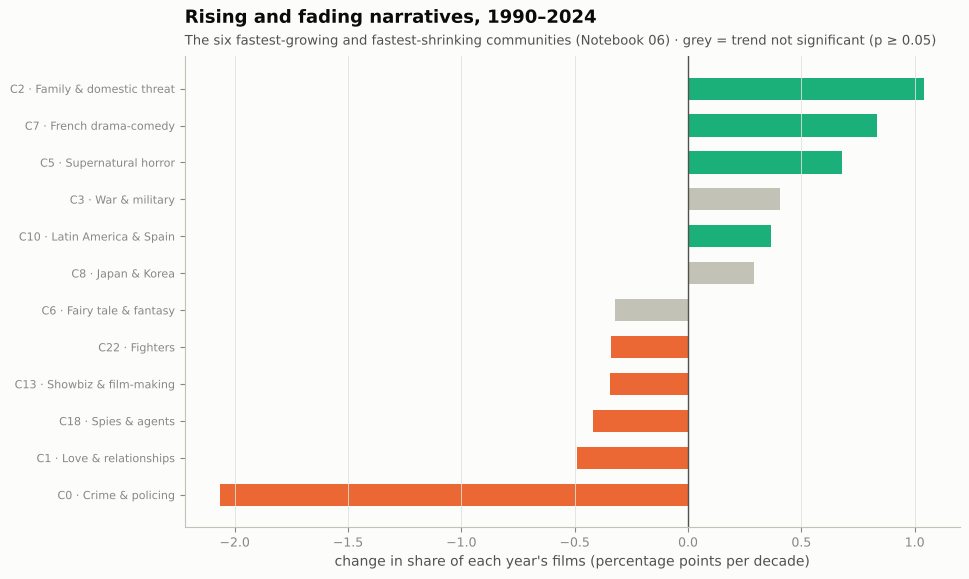

  ✓ 08_structure_success/figures/fig_05_rising_fading.png + table


In [64]:
@figure
def b8_fig05_rising_fading():
    need("trends")
    tr = pd.read_csv(FILES["trends"]).sort_values("trend_pp_per_decade")
    sel = pd.concat([tr.head(6), tr.tail(6)]).drop_duplicates("community_id")
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(sel) + 1.8))
    yy = np.arange(len(sel))
    sig = sel["p_value"] < 0.05
    colors = np.where(sel["trend_pp_per_decade"] > 0, SERIES[2], SERIES[1])
    ax.barh(yy, sel["trend_pp_per_decade"], color=[c if s else AXIS for c, s in zip(colors, sig)], height=0.6)
    ax.set_yticks(yy, [CLAB.get(c, f"C{c}") for c in sel["community_id"]], fontsize=8)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_xlabel("change in share of each year's films (percentage points per decade)")
    ax.grid(axis="y", visible=False)
    ax.set_title("Rising and fading narratives, 1990–2024")
    subtitle(ax, "The six fastest-growing and fastest-shrinking communities (Notebook 06) · grey = trend not significant (p ≥ 0.05)")
    save(fig, sel.round(5), "fig_05_rising_fading")

In [65]:
def key_findings():
    """Short, number-backed statements for the Results chapter and the defence slides."""
    out = []
    if fit is not None:
        r = fit[fit["model"].isin(["M1_controls", "M2_add_plot_network", "M3_add_star_power"])].pivot(
            index="outcome", columns="model", values="r_squared")
        w = fit[fit["model"].str.startswith("joint")].set_index("outcome")["wald_p"]
        for o in [x for x in ["revenue_percentile_year", "vote_average"] if x in r.index]:
            out.append((f"+{r.loc[o, 'M2_add_plot_network'] - r.loc[o, 'M1_controls']:.3f}", f"R² from plot position · {OUTN[o]}",
                        f"star power adds {r.loc[o, 'M3_add_star_power'] - r.loc[o, 'M2_add_plot_network']:.3f}; plot block p = {w.get(o, np.nan):.2g}"))
    if FILES["moran"].exists():
        mo = pd.read_csv(FILES["moran"]).set_index("outcome")
        o = mo["morans_I"].idxmax()
        out.append((f"{mo.loc[o, 'morans_I']:.2f}", f"Moran's I · {OUTN.get(o, o)}", f"chance level ≤ {mo.loc[o, 'null_p95']:.3f}: similar plots, similar fates"))
    if FILES["oos"].exists():
        cv = pd.read_csv(FILES["oos"]).set_index(["outcome", "features"])
        for o in [x for x in ["vote_average", "revenue_percentile_year"] if (x, "+ plot prior") in cv.index]:
            out.append((f"+{cv.loc[(o, '+ plot prior'), 'gain_over_baseline']:.3f}", f"out-of-sample R² · {OUTN[o]}",
                        f"from earlier films' outcomes; genre prior {cv.loc[(o, '+ genre prior'), 'gain_over_baseline']:+.3f}"))
    if FILES["fdr_tests"].exists():          # Notebook 07: count foresight effects that survive the correction
        ft = pd.read_csv(FILES["fdr_tests"]).drop_duplicates(["outcome", "term"])
        f7 = ft[ft["term"] == "foresight_z"]
        keep_ = f7[f7["survives_fdr"] & (f7["coef"] > 0)]
        note_ = ", ".join(OUTN.get(o, o) for o in keep_["outcome"]) or "none"
        if FILES["foresight_windows"].exists():
            fw = pd.read_csv(FILES["foresight_windows"])
            n12 = int(((fw["window"] == "1–2 years after") & (fw["p_value"] < 0.05)).sum())
            note_ += f"; {n12} significant against films only 1–2 years later"
        out.append((f"{len(keep_)}/{len(f7)}", "outcomes with a foresight effect after FDR correction", note_))
    elif FILES["timing"].exists():
        t6 = pd.read_csv(FILES["timing"])
        f6 = t6[(t6["model"] == "T3_plus_competition") & (t6["term"] == "foresight_z")]
        pos_ = int(((f6["p_value"] < 0.05) & (f6["coef"] > 0)).sum())
        out.append((f"{pos_}/{len(f6)}", "outcomes with a positive, significant foresight effect",
                    "stories that later films came to resemble"))
    if FILES["community_effects"].exists():
        ce = pd.read_csv(FILES["community_effects"])
        n_r = int(((ce["rating_ci_low"] > 0) | (ce["rating_ci_high"] < 0)).sum())
        out.append((f"{n_r}/{len(ce)}", "communities that differ in rating", "after year, genre, star power and plot position"))
    if FILES["plain_units"].exists():         # Notebook 07: the largest effect that survives FDR, in plain units
        pu = pd.read_csv(FILES["plain_units"])
        pp = pu[(pu["status"] == "survives FDR") & pu["revenue_equivalent_pct"].notna()]
        if len(pp):
            r_ = pp.loc[pp["plain_coef"].abs().idxmax()]
            b_ = pu[(pu["status"] == "benchmark") & (pu["outcome"] == r_["outcome"])]
            bench_ = f"; cast star power {b_['plain_coef'].iloc[0]:+.1f}" if len(b_) else ""
            out.append((f"{r_['plain_coef']:+.1f} pp", f"{r_['claim']} (P10 → P90)",
                        f"≈ {r_['revenue_equivalent_pct']:+.0f}% revenue for a mid-market film{bench_}"))
    return out

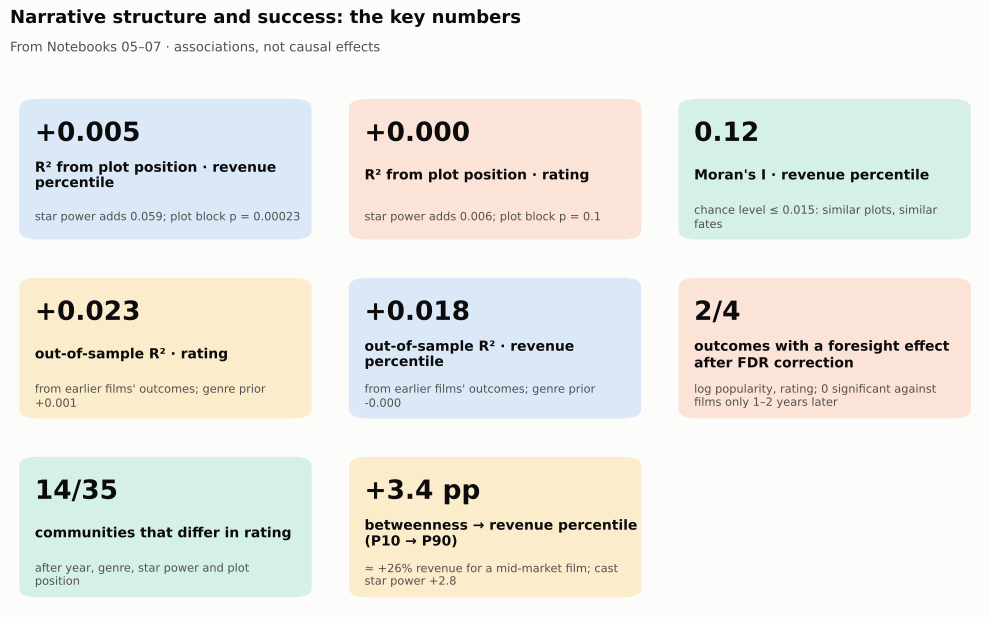

  ✓ 08_structure_success/figures/fig_06_key_findings.png + table


In [66]:
@figure
def b8_fig06_key_findings():
    cards = key_findings()
    if not cards:
        raise Missing("no Notebook 05/06 result tables found")
    fig = card_figure(cards[:9], "Narrative structure and success: the key numbers",
                      "From Notebooks 05–07 · associations, not causal effects")
    save(fig, pd.DataFrame(cards, columns=["value", "label", "note"]), "fig_06_key_findings")

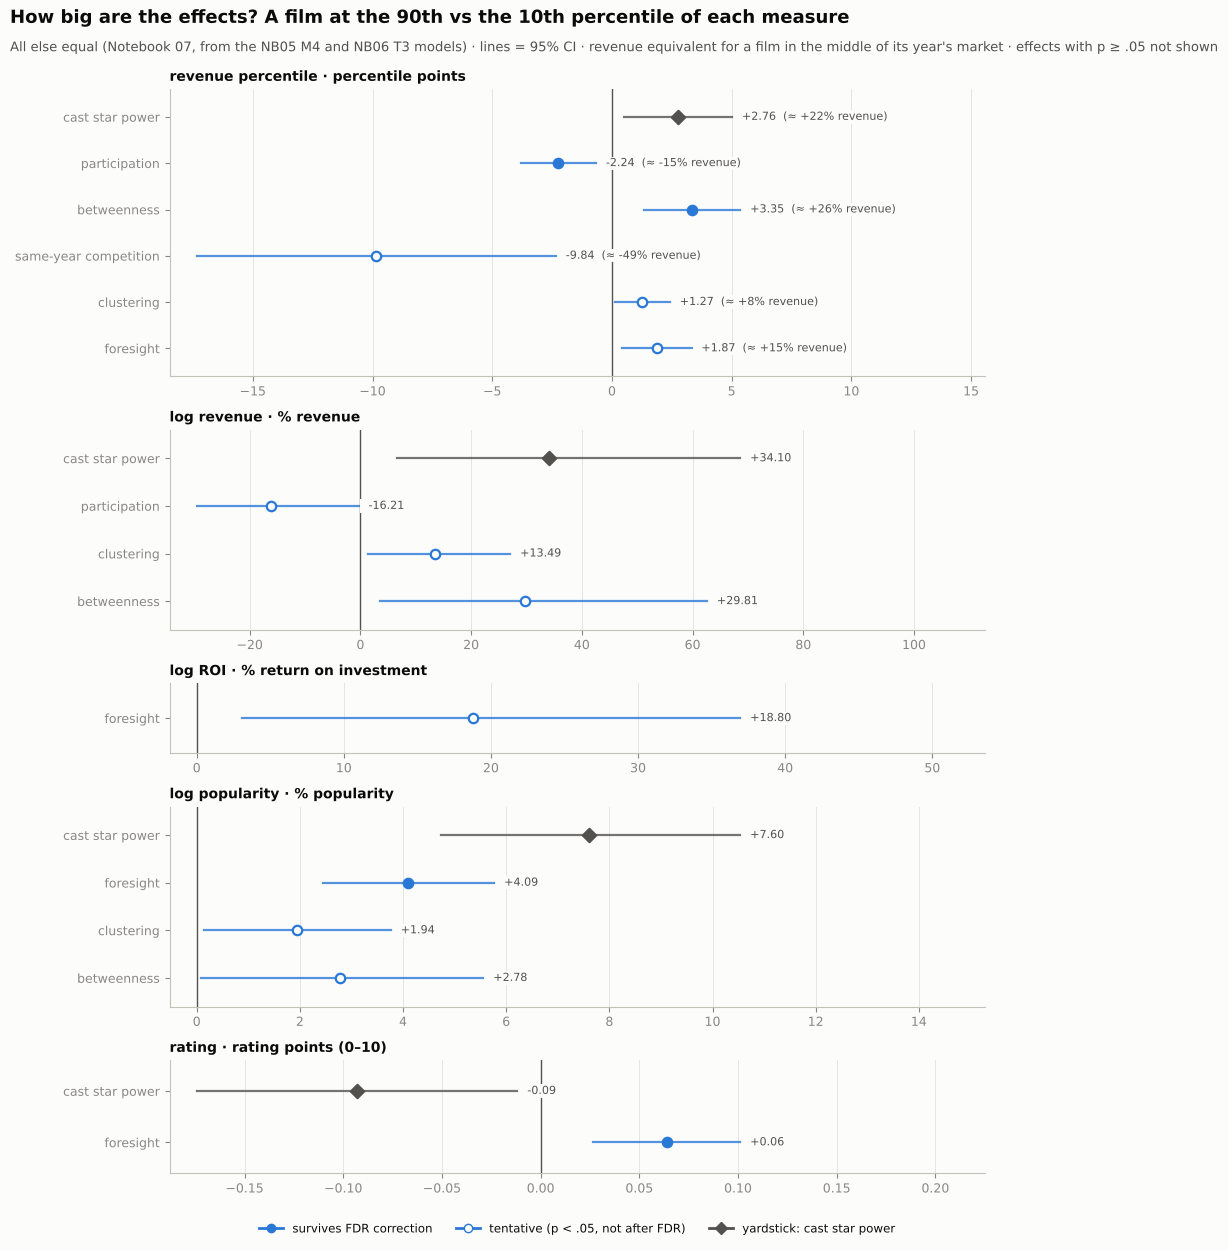

  ✓ 08_structure_success/figures/fig_07_effects_in_plain_units.png + table


In [67]:
@figure
def b8_fig07_effects_in_plain_units():
    need("plain_units")
    pu = pd.read_csv(FILES["plain_units"])
    pu = pu[pu["status"].isin(["survives FDR", "tentative", "benchmark"])]
    order = ["revenue_percentile_year", "log_revenue", "log_roi", "log_popularity", "vote_average"]
    outs = [o for o in order if o in pu["outcome"].unique()]
    rank = {"benchmark": 0, "survives FDR": 1, "tentative": 2}
    panels = [pu[pu["outcome"] == o].assign(r=lambda d: d["status"].map(rank)).sort_values(["r", "plain_coef"]) for o in outs]
    fig, axes = plt.subplots(len(panels), 1, figsize=(10, 0.42 * sum(map(len, panels)) + 0.75 * len(panels) + 1.6),
                             gridspec_kw={"height_ratios": [len(d) + 0.6 for d in panels]})
    for ax, o, d in zip(np.atleast_1d(axes), outs, panels):
        yy = np.arange(len(d))[::-1]
        for yi, r in zip(yy, d.itertuples()):
            color = INK_2 if r.status == "benchmark" else SERIES[0]
            ax.plot([r.plain_ci_low, r.plain_ci_high], [yi, yi], color=color, linewidth=1.6, alpha=0.8)
            ax.scatter(r.plain_coef, yi, s=46, zorder=3, color=color if r.status != "tentative" else SURFACE,
                       edgecolor=color, linewidth=1.6, marker="D" if r.status == "benchmark" else "o")
            txt = f"  {r.plain_coef:+.2f}" + (f"  (≈ {r.revenue_equivalent_pct:+.0f}% revenue)" if pd.notna(r.revenue_equivalent_pct) else "")
            ax.annotate(txt, (max(r.plain_ci_high, r.plain_coef), yi), xytext=(2, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK_2, zorder=4,
                        bbox=dict(boxstyle="square,pad=0.1", fc=SURFACE, ec="none"))
        ax.axvline(0, color=INK_2, linewidth=1)
        ax.set_yticks(yy, [r.claim.split(" → ")[0] for r in d.itertuples()])
        ax.set_ylim(-0.6, len(d) - 0.4)
        lo, hi = min(d["plain_ci_low"].min(), 0), max(d["plain_ci_high"].max(), 0)
        ax.set_xlim(lo - 0.05 * (hi - lo), hi + 0.45 * (hi - lo))
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{OUTN.get(o, o)} · {d['unit'].iloc[0]}", fontsize=10, pad=6)
    ax.legend(handles=[plt.Line2D([], [], color=SERIES[0], marker="o", label="survives FDR correction"),
                       plt.Line2D([], [], color=SERIES[0], marker="o", markerfacecolor=SURFACE, label="tentative (p < .05, not after FDR)"),
                       plt.Line2D([], [], color=INK_2, marker="D", label="yardstick: cast star power")],
              loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=8.5)
    fig_header(fig, "How big are the effects? A film at the 90th vs the 10th percentile of each measure",
               "All else equal (Notebook 07, from the NB05 M4 and NB06 T3 models) · lines = 95% CI · "
               "revenue equivalent for a film in the middle of its year's market · effects with p ≥ .05 not shown")
    save(fig, pd.concat(panels).drop(columns="r").round(5), "fig_07_effects_in_plain_units")


In [68]:
TERM_NAMES = {"z_novelty": "novelty", "z_novelty_sq": "novelty²", "z_log_betweenness": "betweenness",
              "z_participation": "participation", "z_clustering": "clustering", "crowding_z": "crowding",
              "I(crowding_z ** 2)": "crowding²", "foresight_z": "foresight", "competition_z": "same-year competition"}
lines8 = ["Brick 8 — Narrative structure and success", ""]
if FILES["model_fit"].exists():
    r = fit[fit["model"].isin(["M1_controls", "M2_add_plot_network", "M3_add_star_power", "M4_add_community"])].pivot(
        index="outcome", columns="model", values="r_squared")
    w = fit[fit["model"].str.startswith("joint")].set_index("outcome")["wald_p"]
    for o in [x for x in OUTN if x in r.index]:
        lines8.append(f"{OUTN[o]}: R² {r.loc[o, 'M1_controls']:.3f} with controls; plot network +{r.loc[o, 'M2_add_plot_network'] - r.loc[o, 'M1_controls']:.3f}, "
                      f"star power +{r.loc[o, 'M3_add_star_power'] - r.loc[o, 'M2_add_plot_network']:.3f}, community "
                      f"+{r.loc[o, 'M4_add_community'] - r.loc[o, 'M3_add_star_power']:.3f}; plot-network block p = {w.get(o, np.nan):.2g}.")
if FILES["novelty_shape"].exists():
    ns = pd.read_csv(FILES["novelty_shape"])
    lines8.append("Novelty (optimal distinctiveness test): " + ", ".join(f"{OUTN.get(r.outcome, r.outcome)} {r.shape}" for r in ns.itertuples()) + ".")
for v, l, n_ in key_findings():
    lines8.append(f"{l}: {v} ({n_}).")
lines8 += ["", "Storyline for the Results chapter (each sentence follows from the numbers above):"]
if fit is not None:
    g = (r["M2_add_plot_network"] - r["M1_controls"]).reindex([o for o in OUTN if o in r.index])
    s_ = (r["M3_add_star_power"] - r["M2_add_plot_network"]).reindex(g.index)
    lines8.append(f"1. Static position in plot space adds at most {g.max():.3f} R² to year, genre, runtime and language "
                  f"(star power adds up to {s_.max():.3f}); the plot-network block is jointly significant for "
                  f"{int((w.reindex(g.index) < 0.05).sum())} of {len(g)} outcomes (fig_01).")
if FILES["plain_units"].exists():
    pu = pd.read_csv(FILES["plain_units"])
    def _pu(r):
        s_ = f"{r.claim} {r.plain_coef:+.2f} {r.unit}"
        return s_ + (f" (≈ {r.revenue_equivalent_pct:+.0f}% revenue)" if pd.notna(r.revenue_equivalent_pct) else "")
    surv = pu[pu["status"] == "survives FDR"]
    bench = pu[pu["status"] == "benchmark"]
    lines8.append("2. In plain units, a film at the 90th rather than the 10th percentile of the measure (Notebook 07): "
                  + "; ".join(_pu(r) for r in surv.itertuples())
                  + ". Yardstick, cast star power: " + "; ".join(_pu(r) for r in bench.itertuples()) + " (fig_07).")
if FILES["coefficients"].exists() or FILES["timing"].exists():
    sig_terms = []
    for f_, m_ in [("coefficients", None), ("timing", "T3_plus_competition")]:
        if FILES[f_].exists():
            c_ = pd.read_csv(FILES[f_])
            c_ = c_[c_["model"] == m_] if m_ else c_
            c_ = c_[(c_["p_value"] < 0.05) & ~c_["term"].isin(["z_star_index", "z_director_index", "has_star"])]
            sig_terms += [f"{TERM_NAMES.get(t, t)} → {OUTN.get(o, o)} ({b:+.3f})" for t, o, b in zip(c_["term"], c_["outcome"], c_["coef"])]
    if FILES["fdr_tests"].exists():          # Notebook 07: Benjamini–Hochberg over the same plot and timing tests
        ft = pd.read_csv(FILES["fdr_tests"])
        keep_, tent_ = ft[ft["survives_fdr"]], ft[(ft["p_value"] < 0.05) & ~ft["survives_fdr"]]
        lab_ = lambda d: "; ".join(f"{TERM_NAMES.get(t, t)} → {OUTN.get(o, o)} ({b:+.3f})" for t, o, b in zip(d["term"], d["outcome"], d["coef"]))
        lines8.append(f"3. Of {len(ft)} plot and timing tests, {len(keep_) + len(tent_)} have p < 0.05 and {len(keep_)} survive a "
                      f"Benjamini–Hochberg correction (FDR 5%, Notebook 07; fig_02): {lab_(keep_) or 'none'}. "
                      f"Tentative (p < 0.05, not after correction): {lab_(tent_) or 'none'}.")
    else:
        lines8.append("3. Plot measures with p < 0.05 after all controls (fig_02): " + ("; ".join(sig_terms) if sig_terms else "none") + ".")
if FILES["moran"].exists() and FILES["oos"].exists():
    mo = pd.read_csv(FILES["moran"])
    cv = pd.read_csv(FILES["oos"]).pivot_table(index="outcome", columns="features", values="gain_over_baseline")
    better = int((cv["+ plot prior"] > cv["+ genre prior"]).sum()) if {"+ plot prior", "+ genre prior"} <= set(cv) else 0
    lines8.append(f"4. Outcomes cluster on the plot network for {int((mo['p_value'] < 0.05).sum())} of {len(mo)} outcomes "
                  f"(Moran's I {mo['morans_I'].min():.3f}–{mo['morans_I'].max():.3f}); the plot prior beats the genre prior "
                  f"out of sample for {better} of {len(cv)} outcomes (fig_03).")
if FILES["community_effects"].exists():
    ce = pd.read_csv(FILES["community_effects"])
    sr = (ce["rating_ci_low"] > 0) | (ce["rating_ci_high"] < 0)
    sv = (ce["revpct_ci_low"] > 0) | (ce["revpct_ci_high"] < 0)
    fdr_c = ""
    if FILES["fdr_communities"].exists():
        fc = pd.read_csv(FILES["fdr_communities"]).groupby("outcome")["survives_fdr"].sum()
        fdr_c = (f"; after a Benjamini–Hochberg correction {int(fc.get('vote_average', 0))} in rating and "
                 f"{int(fc.get('revenue_percentile_year', 0))} in revenue percentile (Notebook 07)")
    lines8.append(f"5. After controls, {int(sr.sum())} of {len(ce)} labelled communities differ from the average film in rating, "
                  f"{int(sv.sum())} in revenue percentile and {int((sr & sv).sum())} in both{fdr_c} (fig_04).")
if FILES["trends"].exists():
    tr = pd.read_csv(FILES["trends"])
    sig = tr[tr["p_value"] < 0.05]
    lines8.append(f"6. {int((sig['trend_pp_per_decade'] > 0).sum())} communities grew and {int((sig['trend_pp_per_decade'] < 0).sum())} "
                  "shrank significantly as a share of each year's films, 1990–2024 (fig_05).")
if FILES["foresight_windows"].exists() and FILES["imitation"].exists():
    fw = pd.read_csv(FILES["foresight_windows"])
    im_ = pd.read_csv(FILES["imitation"])
    sig_in = lambda w_: ", ".join(OUTN.get(o, o) for o in fw[(fw["window"] == w_) & (fw["p_value"] < 0.05)]["outcome"]) or "none"
    late_ = im_[(im_["window"] == "3–5 years after") & (im_["p_value"] < 0.05) & (im_["coef"] > 0)]["outcome"]
    lines8.append("7. Foresight or imitation (Notebook 07): measured only against films released 1–2 years later — too soon "
                  f"to be copies — foresight is significant for {sig_in('1–2 years after')}; against films 3–5 years later "
                  f"for {sig_in('3–5 years after')}. A film's own success predicts more similar stories 3–5 years later for "
                  f"{', '.join(OUTN.get(o, o) for o in late_) or 'no outcome'}, so imitation cannot be ruled out there.")
if FILES["net_robust"].exists():
    nr = pd.read_csv(FILES["net_robust"])
    jp = nr.groupby("network")["plot_block_p_M4"].apply(lambda p: int((p < 0.05).sum()))
    lines8.append(f"8. Rebuilt networks (Notebook 07): across {', '.join(nr['network'].unique())}, plot position adds "
                  f"{nr['r2_gain_plot_network'].min():.3f}–{nr['r2_gain_plot_network'].max():.3f} R² over the controls; "
                  "the plot block is jointly significant (p < 0.05) for "
                  + ", ".join(f"{int(v)} of 4 outcomes with {n}" for n, v in jp.items())
                  + ". Individual coefficients are less stable — see outputs/tables/robustness/robustness_notes.txt.")
if FILES["story_vs_stars"].exists():      # Notebook 07 Part 6: plot measure × has-a-star, fixed in advance
    sv_ = pd.read_csv(FILES["story_vs_stars"])
    dd_ = sv_[sv_["group"] == "difference"]
    g_ = lambda r, g: sv_[(sv_["outcome"] == r.outcome) & (sv_["term"] == r.term) & (sv_["group"] == g)]["coef"].iloc[0]
    hit_ = [f"{r.claim} (no star {g_(r, 'no star'):+.3f}, with star {g_(r, 'with star'):+.3f}; stronger "
            + ("without a star)" if abs(g_(r, 'no star')) > abs(g_(r, 'with star')) else "with a star, against the hypothesis)")
            for r in dd_[dd_["survives_fdr"].astype(bool)].itertuples()]
    lines8.append(f"9. Story vs stars (Notebook 07): of {len(dd_)} tests of whether plot position matters more for films "
                  f"without a star, {int((dd_['p_value'] < 0.05).sum())} have p < 0.05 and {len(hit_)} survive a "
                  "Benjamini–Hochberg correction" + (": " + "; ".join(hit_) if hit_ else "") + ".")
if FILES["wild_bootstrap"].exists():      # Notebook 07 Part 7: only 36 clusters → wild cluster bootstrap
    wb_ = pd.read_csv(FILES["wild_bootstrap"])
    lines8.append(f"10. Few clusters (Notebook 07): with standard errors clustered by only {int(wb_['clusters'].iloc[0])} "
                  f"communities, a wild cluster bootstrap keeps p < 0.05 for {int(wb_['holds'].sum())} of {len(wb_)} results "
                  "that survive the correction (largest bootstrap p = " f"{wb_['p_wild_bootstrap'].max():.3f}).")
if FILES["sim_check"].exists():
    sc_ = pd.read_csv(FILES["sim_check"])
    sc = sc_.set_index("group")["mean_rating"]
    who_ = sc_["raters"].iloc[0] if "raters" in sc_ else "human rater(s)"
    lines8.append(f"11. Check of the method (Notebook 07; {who_}): blind ratings 1–5 of film pairs — "
                  + ", ".join(f"{g} {v:.2f}" for g, v in sc.items()) + ".")
lines8.append("All results are associations, not causal effects.")

In [69]:
write_note([l for l in lines8 if l is not None])

Brick 8 — Narrative structure and success

log revenue: R² 0.238 with controls; plot network +0.004, star power +0.051, community +0.012; plot-network block p = 0.0016.
revenue percentile: R² 0.233 with controls; plot network +0.005, star power +0.059, community +0.013; plot-network block p = 0.00023.
rating: R² 0.259 with controls; plot network +0.000, star power +0.006, community +0.010; plot-network block p = 0.1.
log popularity: R² 0.158 with controls; plot network +0.001, star power +0.045, community +0.007; plot-network block p = 0.016.
Novelty (optimal distinctiveness test): log revenue flat, revenue percentile flat, rating flat, log popularity flat.
R² from plot position · revenue percentile: +0.005 (star power adds 0.059; plot block p = 0.00023).
R² from plot position · rating: +0.000 (star power adds 0.006; plot block p = 0.1).
Moran's I · revenue percentile: 0.12 (chance level ≤ 0.015: similar plots, similar fates).
out-of-sample R² · rating: +0.023 (from earlier films' outc

---
## Output check

In [70]:
# ═══════════════════════════════════════════════════════════════════════════
# FINAL CELL — Manifest of everything written, and what was skipped
# ═══════════════════════════════════════════════════════════════════════════
manifest = pd.DataFrame(OUTPUTS)
BRICKS_DIR.mkdir(parents=True, exist_ok=True)
manifest.to_csv(BRICKS_DIR / "bricks_manifest.csv", index=False)
print(manifest.groupby(["brick", "kind"]).size().unstack(fill_value=0))
if SKIPPED:
    print(f"\n{len(SKIPPED)} figure(s) skipped:")
    display(pd.DataFrame(SKIPPED))
else:
    print("\nAll figures written ✓")
print(f"\n  ✓ {BRICKS_DIR.relative_to(PROJECT_DIR)}/bricks_manifest.csv")

kind                         figure  table  text
brick                                           
01_data_construction              5      0     1
02_nlp_similarity                 5      0     1
03_network_construction           6      0     1
04_narrative_communities          5      0     1
05_central_story_positions        5      0     1
06_bridging_story_positions       4      0     1
07_success_dimensions             4      1     1
08_structure_success              7      0     1

2 figure(s) skipped:


,brick,figure,reason
0,02_nlp_similarity,b2_fig05_embedding_map,KeyError('community_id')
1,06_bridging_story_positions,b6_fig02_community_contact_matrix,ValueError('underlying array is read-only')



  ✓ outputs/thesis_bricks/bricks_manifest.csv
